In [1]:
import torch
import sys

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("CUDA disponible:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU detectada:", torch.cuda.get_device_name(0))
    print("CUDA de PyTorch:", torch.version.cuda)
    print("Memoria GPU:", round(
        torch.cuda.get_device_properties(0).total_memory / 1024**3, 2
    ), "GB")
else:
    print("No se detectó CUDA. Por ahora PyTorch utilizaría CPU.")

Python: 3.13.1 (tags/v3.13.1:0671451, Dec  3 2024, 19:06:28) [MSC v.1942 64 bit (AMD64)]
PyTorch: 2.15.0+cpu
CUDA disponible: False
No se detectó CUDA. Por ahora PyTorch utilizaría CPU.


In [2]:
import subprocess
import sys

print("Python del entorno Jupyter:")
print(sys.executable)

print("\nInformación de NVIDIA:\n")

resultado = subprocess.run(
    ["nvidia-smi"],
    capture_output=True,
    text=True
)

if resultado.returncode == 0:
    print(resultado.stdout)
else:
    print("No se pudo ejecutar nvidia-smi:")
    print(resultado.stderr)

Python del entorno Jupyter:
C:\Users\Roberto Garcés\PythonProjects\venv\Scripts\python.exe

Información de NVIDIA:

Sun Nov 15 09:23:35 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 581.86                 Driver Version: 581.86         CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                  Driver-Model | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 3050 ...  WDDM  |   00000000:01:00.0 Off |                  N/A |
| N/A   42C    P8              3W /   95W |       0MiB /   6144MiB |      0%      Default |
|                       

In [3]:
%pip uninstall -y torch torchvision torchaudio

Found existing installation: torch 2.15.0
Uninstalling torch-2.15.0:
  Successfully uninstalled torch-2.15.0
Found existing installation: torchvision 0.29.2
Uninstalling torchvision-0.29.2:
  Successfully uninstalled torchvision-0.29.2
Found existing installation: torchaudio 2.11.1
Uninstalling torchaudio-2.11.1:
  Successfully uninstalled torchaudio-2.11.1
Note: you may need to restart the kernel to use updated packages.


You can safely remove it manually.


In [4]:
%pip install torch==2.14.1 torchvision==0.29.1 --index-url https://download.pytorch.org/whl/cu130

Looking in indexes: https://download.pytorch.org/whl/cu130
   ---------------------------------------- 0.0/2.0 GB ? eta -:--:--
   ---------------------------------------- 0.0/2.0 GB 9.0 MB/s eta 0:03:43
   ---------------------------------------- 0.0/2.0 GB 8.7 MB/s eta 0:03:48
   ---------------------------------------- 0.0/2.0 GB 9.1 MB/s eta 0:03:39
   ---------------------------------------- 0.0/2.0 GB 9.1 MB/s eta 0:03:38
   ---------------------------------------- 0.0/2.0 GB 9.3 MB/s eta 0:03:34
   ---------------------------------------- 0.0/2.0 GB 9.6 MB/s eta 0:03:28
   ---------------------------------------- 0.0/2.0 GB 9.2 MB/s eta 0:03:35
   ---------------------------------------- 0.0/2.0 GB 8.7 MB/s eta 0:03:49
   ---------------------------------------- 0.0/2.0 GB 8.6 MB/s eta 0:03:51
   ---------------------------------------- 0.0/2.0 GB 8.6 MB/s eta 0:03:51
   ---------------------------------------- 0.0/2.0 GB 8.7 MB/s eta 0:03:48
   ---------------------------------

In [1]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA disponible:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA:", torch.version.cuda)

    x = torch.rand(3000, 3000, device="cuda")
    y = x @ x

    print("Dispositivo de cálculo:", y.device)
    print("¡GPU funcionando correctamente!")
else:
    print("CUDA todavía no está disponible.")

PyTorch: 2.14.1+cu130
CUDA disponible: True
GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU
CUDA: 13.0
Dispositivo de cálculo: cuda:0
¡GPU funcionando correctamente!


In [4]:
from pathlib import Path

DATA_DIR = Path(r"C:\Users\Roberto Garcés\Downloads\EarthTrend_AI_audit_and_candidate_v1_0")

csv_files = list(DATA_DIR.rglob("*.csv"))

print(f"CSV encontrados: {len(csv_files)}\n")

for i, file in enumerate(csv_files):
    print(f"{i}: {file}")

CSV encontrados: 4

0: C:\Users\Roberto Garcés\Downloads\EarthTrend_AI_audit_and_candidate_v1_0\data_dictionary_TCN_candidate_v1_0.csv
1: C:\Users\Roberto Garcés\Downloads\EarthTrend_AI_audit_and_candidate_v1_0\earthtrend_TCN_candidate_v1_0_2001_2025.csv
2: C:\Users\Roberto Garcés\Downloads\EarthTrend_AI_audit_and_candidate_v1_0\spatial_coverage_audit.csv
3: C:\Users\Roberto Garcés\Downloads\EarthTrend_AI_audit_and_candidate_v1_0\spearman_deseasonalized_candidate_variables.csv


In [6]:
# ============================================================
# EARTH TREND AI
# PASO 1: CARGA Y VALIDACIÓN DEL DATASET
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path

# 1. Rutas
PROJECT_DIR = Path(
    r"C:\Users\Roberto Garcés\Downloads\EarthTrend_AI_audit_and_candidate_v1_0"
)

DATA_PATH = PROJECT_DIR / "earthtrend_TCN_candidate_v1_0_2001_2025.csv"

# 2. Cargar datos
df = pd.read_csv(DATA_PATH)

# 3. Verificar columna temporal
print("Columnas originales:")
print(df.columns.tolist())

if "date" not in df.columns:
    raise ValueError("No se encontró la columna 'date'.")

df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").reset_index(drop=True)

# 4. Variables de entrada
FEATURES = [
    "soil_temp_0_10cm",
    "soil_moisture_0_10cm",
    "soil_moisture_40_100cm",
    "precipitation_monthly_accum",
    "evapotranspiration_mm_month",
    "air_temperature_2m",
    "specific_humidity_2m",
    "wind_eastward_10m",
    "wind_northward_10m"
]

# 5. Verificar columnas
missing_columns = [
    col for col in FEATURES if col not in df.columns
]

if missing_columns:
    raise ValueError(f"Faltan variables: {missing_columns}")

# 6. Auditoría general
print("\n" + "=" * 55)
print("EARTH TREND AI - DATASET AUDIT")
print("=" * 55)

print("\nDimensiones:", df.shape)
print("Fecha inicial:", df["date"].min())
print("Fecha final:", df["date"].max())

print("\nVariables disponibles:", len(FEATURES))

# 7. Valores faltantes
print("\nValores faltantes:")
display(df[FEATURES].isna().sum().to_frame("Missing values"))

# 8. Estadísticas descriptivas
print("\nEstadísticas descriptivas:")
display(df[FEATURES].describe().T)

# 9. Verificación temporal
print("\nFechas duplicadas:", df["date"].duplicated().sum())

expected_dates = pd.date_range(
    start=df["date"].min(),
    end=df["date"].max(),
    freq="MS"
)

missing_dates = expected_dates.difference(df["date"])

print("Meses faltantes en la secuencia:", len(missing_dates))
if len(missing_dates):
    print(missing_dates)

# 10. Primeros registros
print("\nPrimeros registros:")
display(df[["date"] + FEATURES].head())

print("\nDataset cargado y validado correctamente.")

Columnas originales:
['date', 'soil_temp_0_10cm', 'soil_moisture_0_10cm', 'soil_moisture_40_100cm', 'precipitation_monthly_accum', 'air_temperature_2m', 'specific_humidity_2m', 'wind_eastward_10m', 'wind_northward_10m', 'evapotranspiration_mm_month']

EARTH TREND AI - DATASET AUDIT

Dimensiones: (300, 10)
Fecha inicial: 2001-01-01 00:00:00
Fecha final: 2025-12-01 00:00:00

Variables disponibles: 9

Valores faltantes:


,Missing values
soil_temp_0_10cm,0
soil_moisture_0_10cm,0
soil_moisture_40_100cm,0
precipitation_monthly_accum,3
evapotranspiration_mm_month,0
air_temperature_2m,0
specific_humidity_2m,0
wind_eastward_10m,0
wind_northward_10m,0



Estadísticas descriptivas:


,count,mean,std,min,25%,50%,75%,max
soil_temp_0_10cm,300.0,294.751529,7.071352,283.256104,288.093773,294.438476,301.616577,306.661835
soil_moisture_0_10cm,300.0,13.387402,3.323167,8.032072,10.659952,13.086451,15.810265,23.890074
soil_moisture_40_100cm,300.0,95.266552,9.998465,80.166840,87.501593,93.836807,101.070982,137.595093
precipitation_monthly_accum,297.0,15.861101,15.381642,0.131606,4.972197,10.213330,22.096738,76.407694
evapotranspiration_mm_month,300.0,13.480309,6.746820,3.306586,7.854827,12.000470,17.658106,41.042364
air_temperature_2m,300.0,292.253752,5.500548,283.045898,287.259575,291.410507,297.865577,301.987244
specific_humidity_2m,300.0,0.006889,0.001749,0.003984,0.005659,0.006373,0.008160,0.011857
wind_eastward_10m,300.0,1.658390,0.648535,0.071415,1.214090,1.640291,2.059718,3.369997
wind_northward_10m,300.0,-0.652515,0.606053,-2.062045,-1.109244,-0.649522,-0.152257,0.598923



Fechas duplicadas: 0
Meses faltantes en la secuencia: 0

Primeros registros:


,date,soil_temp_0_10cm,soil_moisture_0_10cm,soil_moisture_40_100cm,precipitation_monthly_accum,evapotranspiration_mm_month,air_temperature_2m,specific_humidity_2m,wind_eastward_10m,wind_northward_10m
0,2001-01-01,283.256104,19.499964,95.364388,46.351984,19.413652,283.855621,0.005012,1.519018,-1.132920
1,2001-02-01,284.030090,18.765533,98.313980,58.229763,19.967285,284.228821,0.005332,2.011192,0.031304
2,2001-03-01,287.498627,20.170839,117.867645,35.062601,29.790109,287.436676,0.006286,1.691622,-0.450323
3,2001-04-01,289.843414,14.440060,116.146835,13.106125,20.152869,288.377411,0.005673,2.916733,-0.774936
4,2001-05-01,295.603607,10.785104,111.170128,1.444246,10.751131,294.927826,0.006841,1.675178,0.076764



Dataset cargado y validado correctamente.


In [8]:
%pip install scikit-learn

   ---------------------------------------- 0.0/8.2 MB ? eta -:--:--
   -- ------------------------------------- 0.5/8.2 MB 4.8 MB/s eta 0:00:02
   ------ --------------------------------- 1.3/8.2 MB 4.5 MB/s eta 0:00:02
   ------------ --------------------------- 2.6/8.2 MB 5.3 MB/s eta 0:00:02
   ---------------- ----------------------- 3.4/8.2 MB 4.8 MB/s eta 0:00:02
   ---------------------- ----------------- 4.7/8.2 MB 5.2 MB/s eta 0:00:01
   ----------------------------- ---------- 6.0/8.2 MB 5.4 MB/s eta 0:00:01
   ----------------------------------- ---- 7.3/8.2 MB 5.5 MB/s eta 0:00:01
   ---------------------------------------- 8.2/8.2 MB 5.5 MB/s  0:00:01

   -------------------- ------------------- 2/4 [joblib]
   -------------------- ------------------- 2/4 [joblib]
   -------------------- ------------------- 2/4 [joblib]
   ------------------------------ --------- 3/4 [scikit-learn]
   ------------------------------ --------- 3/4 [scikit-learn]
   -------------------------

In [9]:
import sklearn
import torch

print("Scikit-learn:", sklearn.__version__)
print("PyTorch:", torch.__version__)
print("CUDA disponible:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))

Scikit-learn: 1.9.1
PyTorch: 2.14.1+cu130
CUDA disponible: True
GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU


In [10]:
# ============================================================
# EARTH TREND AI
# PASO 2: PREPARACIÓN Y NORMALIZACIÓN
# ============================================================

import numpy as np
import pandas as pd
import torch

from sklearn.preprocessing import StandardScaler

# ------------------------------------------------------------
# 1. Configuración
# ------------------------------------------------------------

LOOKBACK = 24
HORIZONS = [1, 12]

TRAIN_END = pd.Timestamp("2017-12-01")
VAL_END   = pd.Timestamp("2021-12-01")
TEST_END  = pd.Timestamp("2025-09-01")

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Dispositivo:", DEVICE)

# ------------------------------------------------------------
# 2. Comprobar y ordenar los datos
# ------------------------------------------------------------

df = df.sort_values("date").reset_index(drop=True)

# Asegurar que las variables sean numéricas
df[FEATURES] = df[FEATURES].apply(
    pd.to_numeric, errors="coerce"
)

# Comprobar infinitos
df[FEATURES] = df[FEATURES].replace(
    [np.inf, -np.inf], np.nan
)

# ------------------------------------------------------------
# 3. Separar periodo de entrenamiento
# ------------------------------------------------------------

train_mask = df["date"] <= TRAIN_END

# El scaler aprende exclusivamente del periodo de entrenamiento
scaler = StandardScaler()

scaler.fit(df.loc[train_mask, FEATURES])

# Transformar toda la serie con el scaler de entrenamiento
scaled_values = scaler.transform(df[FEATURES])

# ------------------------------------------------------------
# 4. Revisar los datos normalizados
# ------------------------------------------------------------

print("\nDimensiones de la matriz:", scaled_values.shape)

print("Media de entrenamiento después del escalado:")
print(np.round(
    scaled_values[train_mask].mean(axis=0), 4
))

print("\nDesviación estándar de entrenamiento:")
print(np.round(
    scaled_values[train_mask].std(axis=0), 4
))

print("\nValores faltantes por variable después de normalizar:")
print(
    pd.DataFrame(
        scaled_values,
        columns=FEATURES
    ).isna().sum()
)

print("\nPreparación inicial completada.")

Dispositivo: cuda

Dimensiones de la matriz: (300, 9)
Media de entrenamiento después del escalado:
[-0. -0.  0. -0.  0. -0.  0.  0. -0.]

Desviación estándar de entrenamiento:
[1. 1. 1. 1. 1. 1. 1. 1. 1.]

Valores faltantes por variable después de normalizar:
soil_temp_0_10cm               0
soil_moisture_0_10cm           0
soil_moisture_40_100cm         0
precipitation_monthly_accum    3
evapotranspiration_mm_month    0
air_temperature_2m             0
specific_humidity_2m           0
wind_eastward_10m              0
wind_northward_10m             0
dtype: int64

Preparación inicial completada.


In [11]:
# ============================================================
# EARTH TREND AI
# PASO 3: GENERACIÓN DE VENTANAS TEMPORALES
# ============================================================

def create_windows(
    data,
    dates,
    lookback,
    horizon,
    split_name
):

    X_list = []
    Y_list = []
    target_dates = []

    for i in range(lookback, len(data) - horizon + 1):

        # Ventana histórica
        x = data[i-lookback:i]

        # Horizonte futuro
        y = data[i:i+horizon]

        # Fechas de los objetivos
        y_dates = dates[i:i+horizon]

        # ----------------------------------------------------
        # Verificar que la ventana de entrada y salida
        # no contenga valores faltantes.
        # ----------------------------------------------------

        if not np.isfinite(x).all():
            continue

        if not np.isfinite(y).all():
            continue

        # ----------------------------------------------------
        # Separación cronológica según TODO el horizonte
        # objetivo.
        # ----------------------------------------------------

        first_date = y_dates[0]
        last_date = y_dates[-1]

        if split_name == "train":

            valid_period = last_date <= TRAIN_END

        elif split_name == "validation":

            valid_period = (
                first_date > TRAIN_END
                and last_date <= VAL_END
            )

        elif split_name == "test":

            valid_period = (
                first_date > VAL_END
                and last_date <= TEST_END
            )

        else:
            raise ValueError("Conjunto desconocido.")

        if not valid_period:
            continue

        # PyTorch TCN espera (variables, tiempo)
        X_list.append(x.T)

        # Salida: (horizonte, variables)
        Y_list.append(y)

        target_dates.append(y_dates)

    X = np.asarray(X_list, dtype=np.float32)
    Y = np.asarray(Y_list, dtype=np.float32)

    return X, Y, target_dates


# ------------------------------------------------------------
# 1. Preparar fechas
# ------------------------------------------------------------

dates = df["date"].to_numpy()

# ------------------------------------------------------------
# 2. Generar conjuntos para ambos horizontes
# ------------------------------------------------------------

datasets = {}

for horizon in HORIZONS:

    print(f"\nPreparando horizonte: {horizon} mes(es)")

    datasets[horizon] = {}

    for split in ["train", "validation", "test"]:

        X, Y, target_dates = create_windows(
            data=scaled_values,
            dates=dates,
            lookback=LOOKBACK,
            horizon=horizon,
            split_name=split
        )

        datasets[horizon][split] = {
            "X": X,
            "Y": Y,
            "dates": target_dates
        }

        print(
            f"{split:12s} | "
            f"X: {X.shape} | "
            f"Y: {Y.shape}"
        )

print("\nGeneración de ventanas completada.")


Preparando horizonte: 1 mes(es)
train        | X: (180, 9, 24) | Y: (180, 1, 9)
validation   | X: (48, 9, 24) | Y: (48, 1, 9)
test         | X: (45, 9, 24) | Y: (45, 1, 9)

Preparando horizonte: 12 mes(es)
train        | X: (169, 9, 24) | Y: (169, 12, 9)
validation   | X: (37, 9, 24) | Y: (37, 12, 9)
test         | X: (34, 9, 24) | Y: (34, 12, 9)

Generación de ventanas completada.


In [12]:
# ============================================================
# EARTH TREND AI
# PASO 4: CONVERSIÓN A TENSORES
# ============================================================

torch_datasets = {}

for horizon in HORIZONS:

    torch_datasets[horizon] = {}

    for split in ["train", "validation", "test"]:

        X = datasets[horizon][split]["X"]
        Y = datasets[horizon][split]["Y"]

        X_tensor = torch.tensor(
            X,
            dtype=torch.float32
        )

        Y_tensor = torch.tensor(
            Y,
            dtype=torch.float32
        )

        torch_datasets[horizon][split] = {
            "X": X_tensor,
            "Y": Y_tensor
        }

    print(f"\nHorizonte: {horizon} mes(es)")

    print(
        "Entrada:",
        torch_datasets[horizon]["train"]["X"].shape
    )

    print(
        "Salida:",
        torch_datasets[horizon]["train"]["Y"].shape
    )

print("\nTensores preparados correctamente.")
print("Dispositivo disponible:", DEVICE)


Horizonte: 1 mes(es)
Entrada: torch.Size([180, 9, 24])
Salida: torch.Size([180, 1, 9])

Horizonte: 12 mes(es)
Entrada: torch.Size([169, 9, 24])
Salida: torch.Size([169, 12, 9])

Tensores preparados correctamente.
Dispositivo disponible: cuda


In [13]:
# ============================================================
# EARTH TREND AI
# PASO 5: ARQUITECTURA TCN EN PYTORCH
# ============================================================

import torch
import torch.nn as nn
import torch.nn.functional as F

# ------------------------------------------------------------
# 1. Convolución causal
# ------------------------------------------------------------

class CausalConv1d(nn.Module):

    def __init__(
        self,
        in_channels,
        out_channels,
        kernel_size,
        dilation
    ):

        super().__init__()

        self.padding = (kernel_size - 1) * dilation

        self.conv = nn.Conv1d(
            in_channels,
            out_channels,
            kernel_size=kernel_size,
            dilation=dilation,
            padding=self.padding
        )

    def forward(self, x):

        out = self.conv(x)

        # Eliminar información temporal futura
        if self.padding > 0:
            out = out[:, :, :-self.padding]

        return out


# ------------------------------------------------------------
# 2. Bloque residual TCN
# ------------------------------------------------------------

class TCNBlock(nn.Module):

    def __init__(
        self,
        channels,
        kernel_size,
        dilation,
        dropout
    ):

        super().__init__()

        self.conv1 = CausalConv1d(
            channels,
            channels,
            kernel_size,
            dilation
        )

        self.conv2 = CausalConv1d(
            channels,
            channels,
            kernel_size,
            dilation
        )

        self.dropout = nn.Dropout(dropout)

        self.activation = nn.ReLU()

        self.norm1 = nn.BatchNorm1d(channels)
        self.norm2 = nn.BatchNorm1d(channels)

    def forward(self, x):

        residual = x

        out = self.conv1(x)
        out = self.norm1(out)
        out = self.activation(out)
        out = self.dropout(out)

        out = self.conv2(out)
        out = self.norm2(out)
        out = self.activation(out)
        out = self.dropout(out)

        return self.activation(out + residual)


# ------------------------------------------------------------
# 3. Red TCN multivariable
# ------------------------------------------------------------

class EarthTrendTCN(nn.Module):

    def __init__(
        self,
        input_channels=9,
        output_channels=9,
        hidden_channels=32,
        kernel_size=3,
        dilations=(1, 2, 4, 8),
        dropout=0.1,
        horizon=1
    ):

        super().__init__()

        self.horizon = horizon
        self.output_channels = output_channels

        self.input_projection = nn.Conv1d(
            input_channels,
            hidden_channels,
            kernel_size=1
        )

        self.tcn_blocks = nn.Sequential(

            *[
                TCNBlock(
                    channels=hidden_channels,
                    kernel_size=kernel_size,
                    dilation=d,
                    dropout=dropout
                )
                for d in dilations
            ]

        )

        self.output_head = nn.Sequential(

            nn.Linear(hidden_channels, 64),
            nn.ReLU(),
            nn.Dropout(dropout),

            nn.Linear(
                64,
                horizon * output_channels
            )

        )

    def forward(self, x):

        # x: (batch, variables, tiempo)

        out = self.input_projection(x)

        out = self.tcn_blocks(out)

        # Representación del último instante
        out = out[:, :, -1]

        out = self.output_head(out)

        # (batch, horizonte, variables)
        out = out.view(
            -1,
            self.horizon,
            self.output_channels
        )

        return out


print("Arquitectura EarthTrend TCN definida.")

Arquitectura EarthTrend TCN definida.


In [14]:
# ============================================================
# PASO 6: INICIALIZACIÓN DE MODELOS
# ============================================================

models = {}

for horizon in HORIZONS:

    model = EarthTrendTCN(
        input_channels=len(FEATURES),
        output_channels=len(FEATURES),
        hidden_channels=32,
        kernel_size=3,
        dilations=(1, 2, 4, 8),
        dropout=0.1,
        horizon=horizon
    )

    model = model.to(DEVICE)

    models[horizon] = model

    print(f"\nModelo para horizonte: {horizon} mes(es)")
    print("Parámetros:", sum(
        p.numel() for p in model.parameters()
    ))

    print("Dispositivo:", next(model.parameters()).device)


# ------------------------------------------------------------
# Prueba de propagación
# ------------------------------------------------------------

for horizon in HORIZONS:

    model = models[horizon]

    X_sample = torch_datasets[horizon]["train"]["X"][:4]
    X_sample = X_sample.to(DEVICE)

    with torch.no_grad():

        prediction = model(X_sample)

    print(f"\nHorizonte: {horizon}")
    print("Entrada:", X_sample.shape)
    print("Predicción:", prediction.shape)

print("\n¡Ambos modelos funcionan correctamente!")


Modelo para horizonte: 1 mes(es)
Parámetros: 28361
Dispositivo: cuda:0

Modelo para horizonte: 12 mes(es)
Parámetros: 34796
Dispositivo: cuda:0

Horizonte: 1
Entrada: torch.Size([4, 9, 24])
Predicción: torch.Size([4, 1, 9])

Horizonte: 12
Entrada: torch.Size([4, 9, 24])
Predicción: torch.Size([4, 12, 9])

¡Ambos modelos funcionan correctamente!


In [15]:
# ============================================================
# EARTH TREND AI
# PASO 7: CONFIGURACIÓN DEL ENTRENAMIENTO
# ============================================================

import os
import copy
import random
import numpy as np
import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader

# ------------------------------------------------------------
# 1. Reproducibilidad
# ------------------------------------------------------------

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# ------------------------------------------------------------
# 2. Hiperparámetros
# ------------------------------------------------------------

BATCH_SIZE = 16
EPOCHS = 500
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4

PATIENCE = 50
MIN_DELTA = 1e-5

# ------------------------------------------------------------
# 3. Directorio para guardar modelos
# ------------------------------------------------------------

CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
CHECKPOINT_DIR.mkdir(exist_ok=True)

# ------------------------------------------------------------
# 4. Preparar DataLoaders
# ------------------------------------------------------------

loaders = {}

for horizon in HORIZONS:

    loaders[horizon] = {}

    for split in ["train", "validation"]:

        X = torch_datasets[horizon][split]["X"]
        Y = torch_datasets[horizon][split]["Y"]

        dataset = TensorDataset(X, Y)

        loaders[horizon][split] = DataLoader(
            dataset,
            batch_size=BATCH_SIZE,
            shuffle=(split == "train"),
            drop_last=False,
            pin_memory=torch.cuda.is_available()
        )

    print(
        f"Horizonte {horizon}: "
        f"{len(loaders[horizon]['train'])} lotes de entrenamiento"
    )

print("\nConfiguración de entrenamiento preparada.")

Horizonte 1: 12 lotes de entrenamiento
Horizonte 12: 11 lotes de entrenamiento

Configuración de entrenamiento preparada.


In [16]:
# ============================================================
# EARTH TREND AI
# PASO 8: TRAINING LOOP CON EARLY STOPPING
# ============================================================

def train_model(model, horizon, loaders):

    model = model.to(DEVICE)

    criterion = nn.HuberLoss(delta=1.0)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=0.5,
        patience=15,
        min_lr=1e-6
    )

    history = {
        "train_loss": [],
        "val_loss": [],
        "learning_rate": []
    }

    best_val_loss = float("inf")
    best_weights = None
    patience_counter = 0

    checkpoint_path = (
        CHECKPOINT_DIR / f"earthtrend_tcn_h{horizon}.pth"
    )

    print(f"\nEntrenando horizonte de {horizon} mes(es)")
    print("-" * 55)

    for epoch in range(EPOCHS):

        # ----------------------------------------
        # TRAIN
        # ----------------------------------------

        model.train()

        train_loss = 0.0
        train_samples = 0

        for X_batch, Y_batch in loaders["train"]:

            X_batch = X_batch.to(DEVICE)
            Y_batch = Y_batch.to(DEVICE)

            optimizer.zero_grad(set_to_none=True)

            predictions = model(X_batch)

            loss = criterion(predictions, Y_batch)

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=1.0
            )

            optimizer.step()

            batch_size = X_batch.size(0)

            train_loss += loss.item() * batch_size
            train_samples += batch_size

        train_loss /= train_samples

        # ----------------------------------------
        # VALIDATION
        # ----------------------------------------

        model.eval()

        val_loss = 0.0
        val_samples = 0

        with torch.no_grad():

            for X_batch, Y_batch in loaders["validation"]:

                X_batch = X_batch.to(DEVICE)
                Y_batch = Y_batch.to(DEVICE)

                predictions = model(X_batch)

                loss = criterion(predictions, Y_batch)

                batch_size = X_batch.size(0)

                val_loss += loss.item() * batch_size
                val_samples += batch_size

        val_loss /= val_samples

        scheduler.step(val_loss)

        current_lr = optimizer.param_groups[0]["lr"]

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["learning_rate"].append(current_lr)

        # ----------------------------------------
        # EARLY STOPPING
        # ----------------------------------------

        if val_loss < best_val_loss - MIN_DELTA:

            best_val_loss = val_loss

            best_weights = copy.deepcopy(
                model.state_dict()
            )

            torch.save(
                {
                    "model_state_dict": best_weights,
                    "horizon": horizon,
                    "epoch": epoch + 1,
                    "validation_loss": best_val_loss,
                    "features": FEATURES
                },
                checkpoint_path
            )

            patience_counter = 0

        else:

            patience_counter += 1

        # ----------------------------------------
        # PROGRESS
        # ----------------------------------------

        if (epoch + 1) % 10 == 0 or epoch == 0:

            print(
                f"Epoch {epoch+1:03d}/{EPOCHS} | "
                f"Train: {train_loss:.5f} | "
                f"Val: {val_loss:.5f} | "
                f"LR: {current_lr:.2e}"
            )

        if patience_counter >= PATIENCE:

            print(
                f"\nEarly stopping en epoch {epoch+1}"
            )

            break

    # Recuperar mejores pesos
    if best_weights is None:
        raise RuntimeError("No se guardaron pesos válidos.")

    model.load_state_dict(best_weights)

    print("\nEntrenamiento terminado.")
    print("Mejor validation loss:", best_val_loss)
    print("Checkpoint:", checkpoint_path)

    return model, history

In [17]:
# ============================================================
# EARTH TREND AI
# PASO 9: ENTRENAMIENTO DE AMBOS MODELOS
# ============================================================

trained_models = {}
training_histories = {}

for horizon in HORIZONS:

    print("\n" + "=" * 60)
    print(f"MODELO: HORIZONTE {horizon} MES(ES)")
    print("=" * 60)

    model = models[horizon]

    trained_model, history = train_model(
        model=model,
        horizon=horizon,
        loaders=loaders[horizon]
    )

    trained_models[horizon] = trained_model
    training_histories[horizon] = history

print("\n¡ENTRENAMIENTO DE EARTH TREND AI COMPLETADO!")


MODELO: HORIZONTE 1 MES(ES)

Entrenando horizonte de 1 mes(es)
-------------------------------------------------------
Epoch 001/500 | Train: 0.42434 | Val: 0.39055 | LR: 1.00e-03
Epoch 010/500 | Train: 0.14861 | Val: 0.13929 | LR: 1.00e-03
Epoch 020/500 | Train: 0.10625 | Val: 0.14712 | LR: 1.00e-03
Epoch 030/500 | Train: 0.08061 | Val: 0.15284 | LR: 5.00e-04
Epoch 040/500 | Train: 0.07495 | Val: 0.15591 | LR: 5.00e-04
Epoch 050/500 | Train: 0.06887 | Val: 0.15136 | LR: 2.50e-04

Early stopping en epoch 59

Entrenamiento terminado.
Mejor validation loss: 0.133069376150767
Checkpoint: C:\Users\Roberto Garcés\Downloads\EarthTrend_AI_audit_and_candidate_v1_0\checkpoints\earthtrend_tcn_h1.pth

MODELO: HORIZONTE 12 MES(ES)

Entrenando horizonte de 12 mes(es)
-------------------------------------------------------
Epoch 001/500 | Train: 0.47129 | Val: 0.42931 | LR: 1.00e-03
Epoch 010/500 | Train: 0.18636 | Val: 0.17861 | LR: 1.00e-03
Epoch 020/500 | Train: 0.16395 | Val: 0.16203 | LR: 1.00

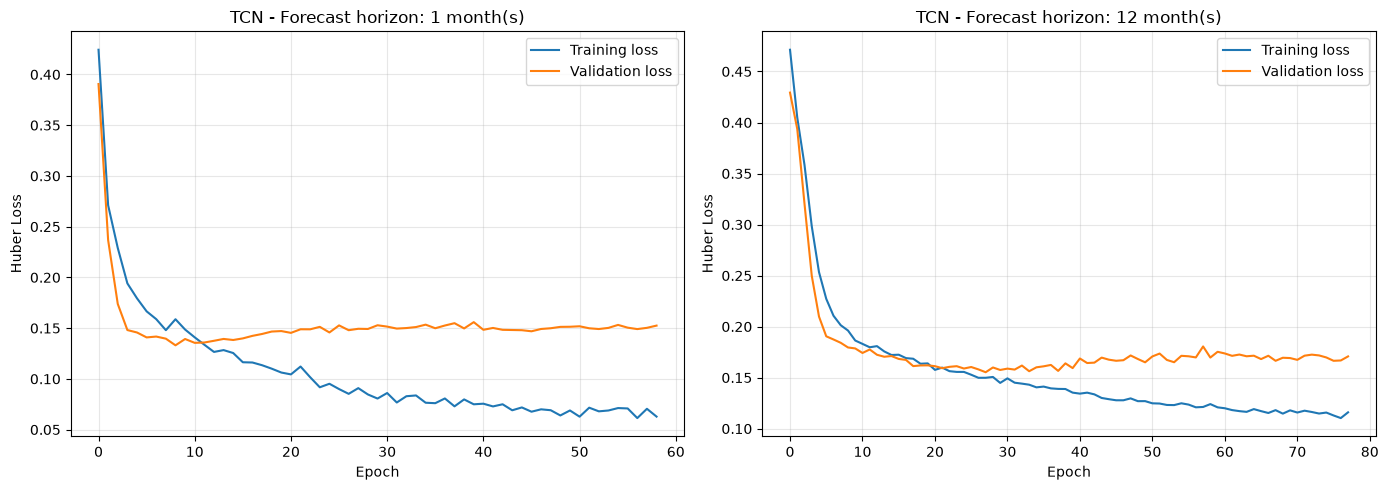

In [18]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, horizon in zip(axes, HORIZONS):

    history = training_histories[horizon]

    ax.plot(
        history["train_loss"],
        label="Training loss"
    )

    ax.plot(
        history["val_loss"],
        label="Validation loss"
    )

    ax.set_title(
        f"TCN - Forecast horizon: {horizon} month(s)"
    )

    ax.set_xlabel("Epoch")
    ax.set_ylabel("Huber Loss")

    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [19]:
# ============================================================
# EARTH TREND AI
# PASO 10: EVALUACIÓN EN TEST
# ============================================================

import numpy as np
import pandas as pd
import torch

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

results = {}
predictions_original = {}

for horizon in HORIZONS:

    model = trained_models[horizon]
    model.eval()

    X_test = torch_datasets[horizon]["test"]["X"].to(DEVICE)

    Y_test = torch_datasets[horizon]["test"]["Y"].numpy()

    with torch.no_grad():
        Y_pred = model(X_test).cpu().numpy()

    # Convertir a unidades originales
    n_samples, h, n_features = Y_test.shape

    Y_test_original = scaler.inverse_transform(
        Y_test.reshape(-1, n_features)
    ).reshape(n_samples, h, n_features)

    Y_pred_original = scaler.inverse_transform(
        Y_pred.reshape(-1, n_features)
    ).reshape(n_samples, h, n_features)

    predictions_original[horizon] = {
        "real": Y_test_original,
        "pred": Y_pred_original
    }

    rows = []

    for j, variable in enumerate(FEATURES):

        real = Y_test_original[:, :, j].ravel()
        pred = Y_pred_original[:, :, j].ravel()

        mae = mean_absolute_error(real, pred)
        rmse = np.sqrt(mean_squared_error(real, pred))
        r2 = r2_score(real, pred)

        rows.append({
            "Variable": variable,
            "MAE": mae,
            "RMSE": rmse,
            "R2": r2
        })

    results[horizon] = pd.DataFrame(rows)

    print(f"\n{'='*65}")
    print(f"RESULTADOS - HORIZONTE {horizon} MES(ES)")
    print(f"{'='*65}")

    display(results[horizon].round(4))

print("\nEvaluación completada.")


RESULTADOS - HORIZONTE 1 MES(ES)


,Variable,MAE,RMSE,R2
0,soil_temp_0_10cm,1.2246,1.7712,0.9378
1,soil_moisture_0_10cm,1.4197,1.8059,0.7195
2,soil_moisture_40_100cm,6.1317,7.2848,-0.0075
3,precipitation_monthly_accum,7.3853,9.5551,0.4329
4,evapotranspiration_mm_month,3.9948,5.5789,0.4917
5,air_temperature_2m,1.2600,1.5872,0.9209
6,specific_humidity_2m,0.0006,0.0009,0.8106
7,wind_eastward_10m,0.3832,0.5013,0.5074
8,wind_northward_10m,0.2975,0.3755,0.5274



RESULTADOS - HORIZONTE 12 MES(ES)


,Variable,MAE,RMSE,R2
0,soil_temp_0_10cm,1.3687,1.7003,0.9435
1,soil_moisture_0_10cm,1.5736,2.0209,0.6692
2,soil_moisture_40_100cm,10.2725,11.6828,-2.0274
3,precipitation_monthly_accum,6.7105,9.3801,0.5137
4,evapotranspiration_mm_month,4.2470,5.9855,0.4174
5,air_temperature_2m,1.3983,1.7118,0.9096
6,specific_humidity_2m,0.0006,0.0008,0.8001
7,wind_eastward_10m,0.4089,0.5238,0.4687
8,wind_northward_10m,0.2918,0.3633,0.4998



Evaluación completada.


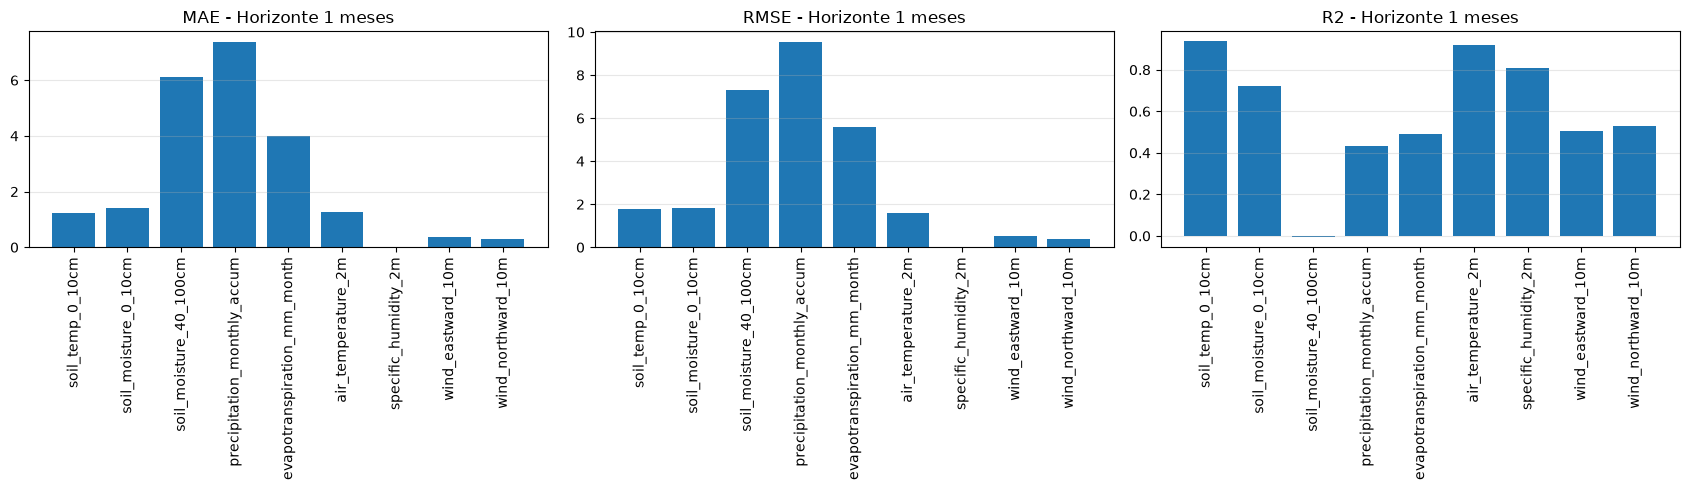

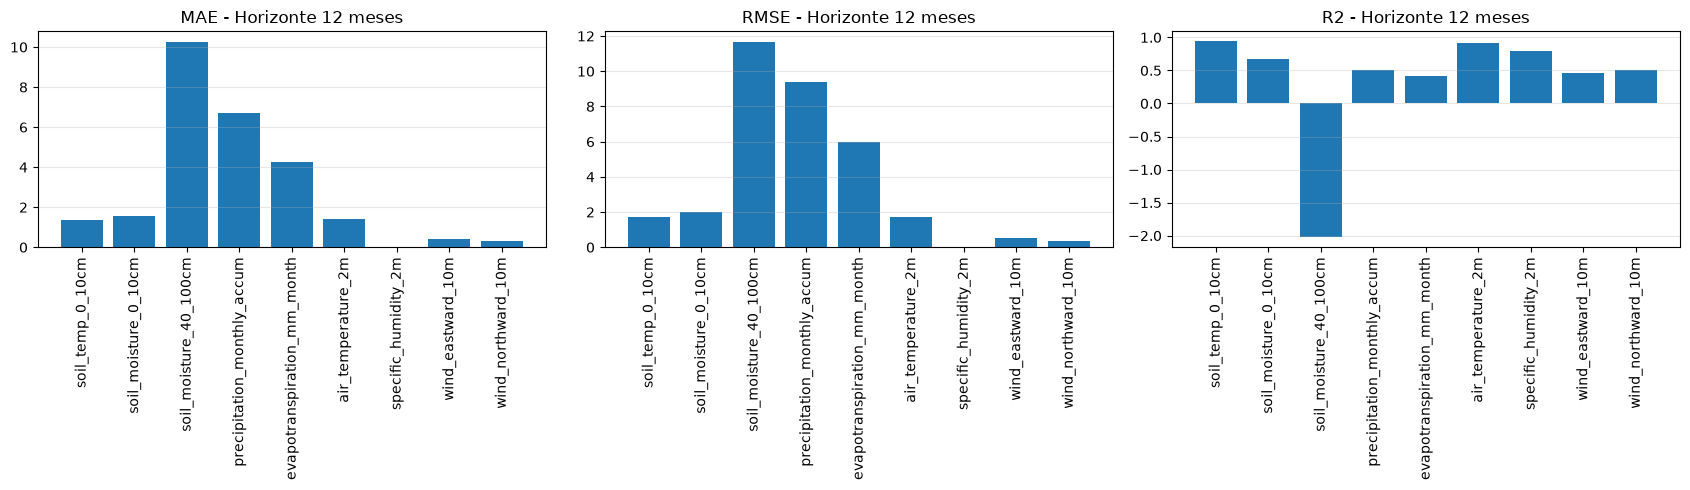

In [20]:
import matplotlib.pyplot as plt

for horizon in HORIZONS:

    metrics = results[horizon]

    fig, axes = plt.subplots(1, 3, figsize=(17, 5))

    for ax, metric in zip(
        axes,
        ["MAE", "RMSE", "R2"]
    ):

        ax.bar(
            metrics["Variable"],
            metrics[metric]
        )

        ax.set_title(f"{metric} - Horizonte {horizon} meses")
        ax.tick_params(axis="x", rotation=90)
        ax.grid(axis="y", alpha=0.3)

    plt.tight_layout()
    plt.show()

In [21]:
# ============================================================
# EARTH TREND AI
# PASO 11: COMPARACIÓN CONTRA BASELINES
# ============================================================

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

baseline_results = {}

for horizon in HORIZONS:

    # Datos reales y predicciones TCN en unidades originales
    real = predictions_original[horizon]["real"]
    pred_tcn = predictions_original[horizon]["pred"]

    # Entradas históricas de test, todavía normalizadas
    X_test = torch_datasets[horizon]["test"]["X"].numpy()

    n_samples, n_features, lookback = X_test.shape

    # --------------------------------------------------------
    # Baseline 1: persistencia
    # Repite el último valor observado
    # --------------------------------------------------------

    last_values = X_test[:, :, -1]

    persistence_scaled = np.repeat(
        last_values[:, None, :],
        horizon,
        axis=1
    )

    # --------------------------------------------------------
    # Baseline 2: persistencia estacional
    # Utiliza los mismos meses del año anterior
    # --------------------------------------------------------

    seasonal_scaled = X_test[
        :,
        :,
        LOOKBACK - 12 : LOOKBACK - 12 + horizon
    ].transpose(0, 2, 1)

    # Convertir a unidades originales
    persistence = scaler.inverse_transform(
        persistence_scaled.reshape(-1, n_features)
    ).reshape(n_samples, horizon, n_features)

    seasonal = scaler.inverse_transform(
        seasonal_scaled.reshape(-1, n_features)
    ).reshape(n_samples, horizon, n_features)

    # --------------------------------------------------------
    # Métricas
    # --------------------------------------------------------

    rows = []

    for j, variable in enumerate(FEATURES):

        y_true = real[:, :, j].ravel()

        models_to_compare = {
            "TCN": pred_tcn[:, :, j].ravel(),
            "Persistence": persistence[:, :, j].ravel(),
            "Seasonal": seasonal[:, :, j].ravel()
        }

        for model_name, y_pred in models_to_compare.items():

            rows.append({
                "Variable": variable,
                "Model": model_name,
                "MAE": mean_absolute_error(y_true, y_pred),
                "RMSE": np.sqrt(
                    mean_squared_error(y_true, y_pred)
                ),
                "R2": r2_score(y_true, y_pred)
            })

    baseline_results[horizon] = pd.DataFrame(rows)

    print(f"\n{'='*75}")
    print(f"COMPARACIÓN - HORIZONTE {horizon} MES(ES)")
    print("=" * 75)

    display(
        baseline_results[horizon].round(4)
    )


COMPARACIÓN - HORIZONTE 1 MES(ES)


,Variable,Model,MAE,RMSE,R2
0,soil_temp_0_10cm,TCN,1.2246,1.7712,0.9378
1,soil_temp_0_10cm,Persistence,3.2262,3.8296,0.7093
2,soil_temp_0_10cm,Seasonal,1.2094,1.5612,0.9517
3,soil_moisture_0_10cm,TCN,1.4197,1.8059,0.7195
4,soil_moisture_0_10cm,Persistence,2.1868,2.7314,0.3583
5,soil_moisture_0_10cm,Seasonal,1.8737,2.3129,0.5399
6,soil_moisture_40_100cm,TCN,6.1317,7.2848,-0.0075
7,soil_moisture_40_100cm,Persistence,2.5962,3.6844,0.7423
8,soil_moisture_40_100cm,Seasonal,7.8436,9.9374,-0.8748
9,precipitation_monthly_accum,TCN,7.3853,9.5551,0.4329



COMPARACIÓN - HORIZONTE 12 MES(ES)


,Variable,Model,MAE,RMSE,R2
0,soil_temp_0_10cm,TCN,1.3687,1.7003,0.9435
1,soil_temp_0_10cm,Persistence,8.3220,10.2442,-1.0509
2,soil_temp_0_10cm,Seasonal,1.2982,1.6609,0.9461
3,soil_moisture_0_10cm,TCN,1.5736,2.0209,0.6692
4,soil_moisture_0_10cm,Persistence,4.1380,5.0829,-1.0925
5,soil_moisture_0_10cm,Seasonal,1.8163,2.2103,0.6043
6,soil_moisture_40_100cm,TCN,10.2725,11.6828,-2.0274
7,soil_moisture_40_100cm,Persistence,7.7310,9.5312,-1.0150
8,soil_moisture_40_100cm,Seasonal,6.9828,9.1353,-0.8511
9,precipitation_monthly_accum,TCN,6.7105,9.3801,0.5137


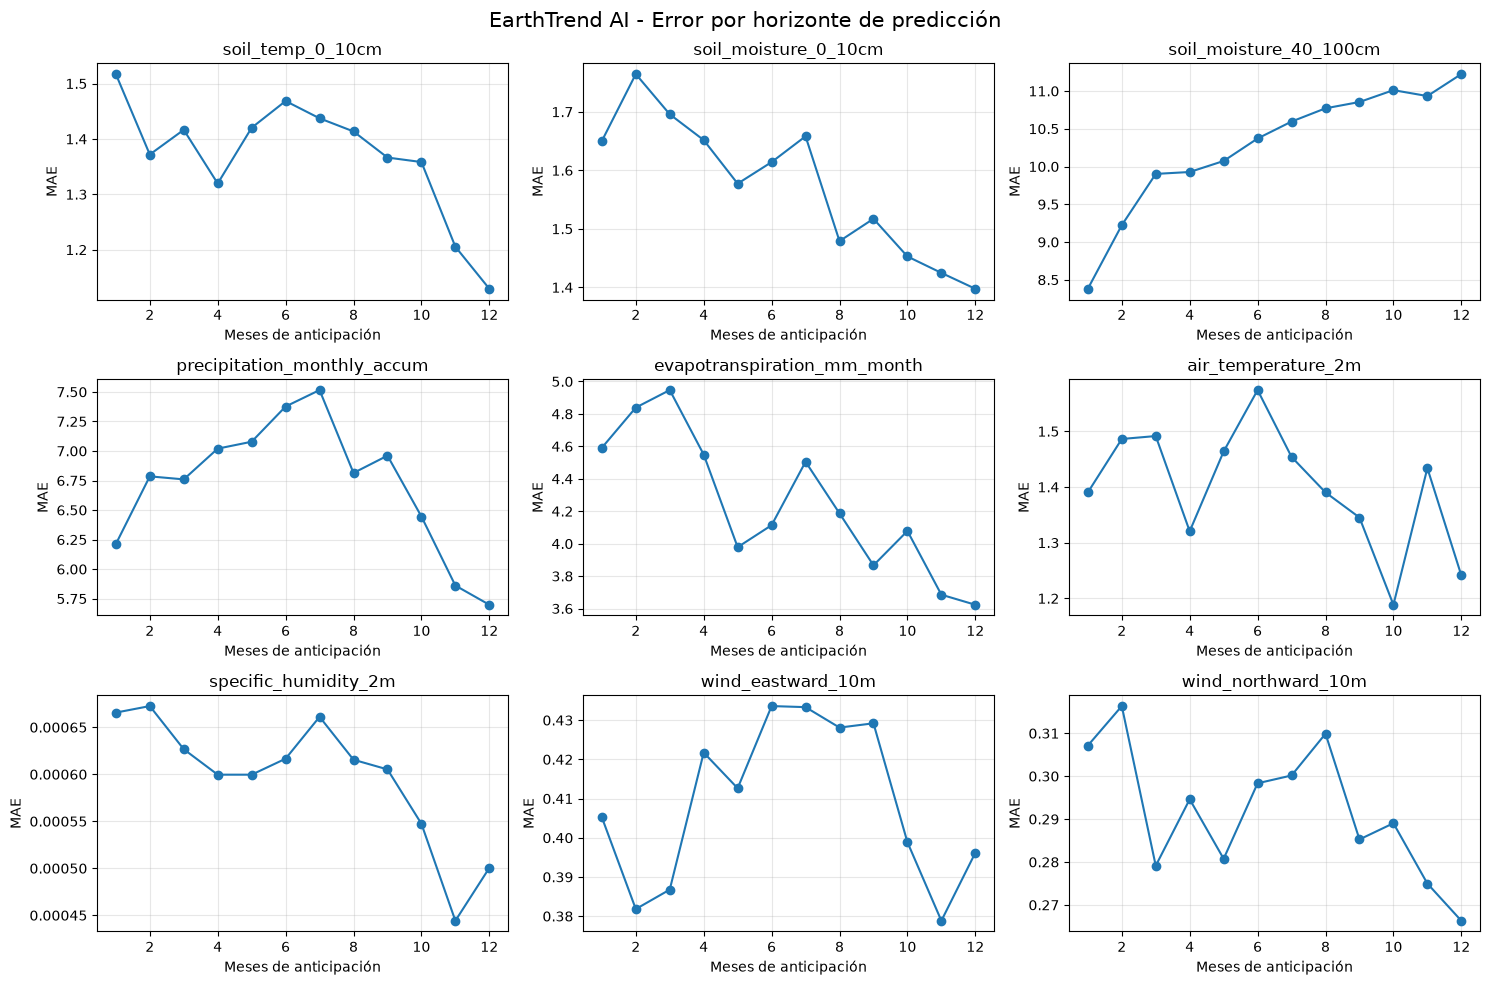

In [22]:
# ============================================================
# PASO 12: ERROR SEGÚN EL MES DE ANTICIPACIÓN
# ============================================================

import matplotlib.pyplot as plt

horizon = 12

real = predictions_original[horizon]["real"]
pred = predictions_original[horizon]["pred"]

mae_by_lead = np.mean(
    np.abs(real - pred),
    axis=0
)

fig, axes = plt.subplots(3, 3, figsize=(15, 10))

for j, ax in enumerate(axes.flat):

    ax.plot(
        range(1, horizon + 1),
        mae_by_lead[:, j],
        marker="o"
    )

    ax.set_title(FEATURES[j])
    ax.set_xlabel("Meses de anticipación")
    ax.set_ylabel("MAE")
    ax.grid(alpha=0.3)

plt.suptitle(
    "EarthTrend AI - Error por horizonte de predicción",
    fontsize=15
)

plt.tight_layout()
plt.show()

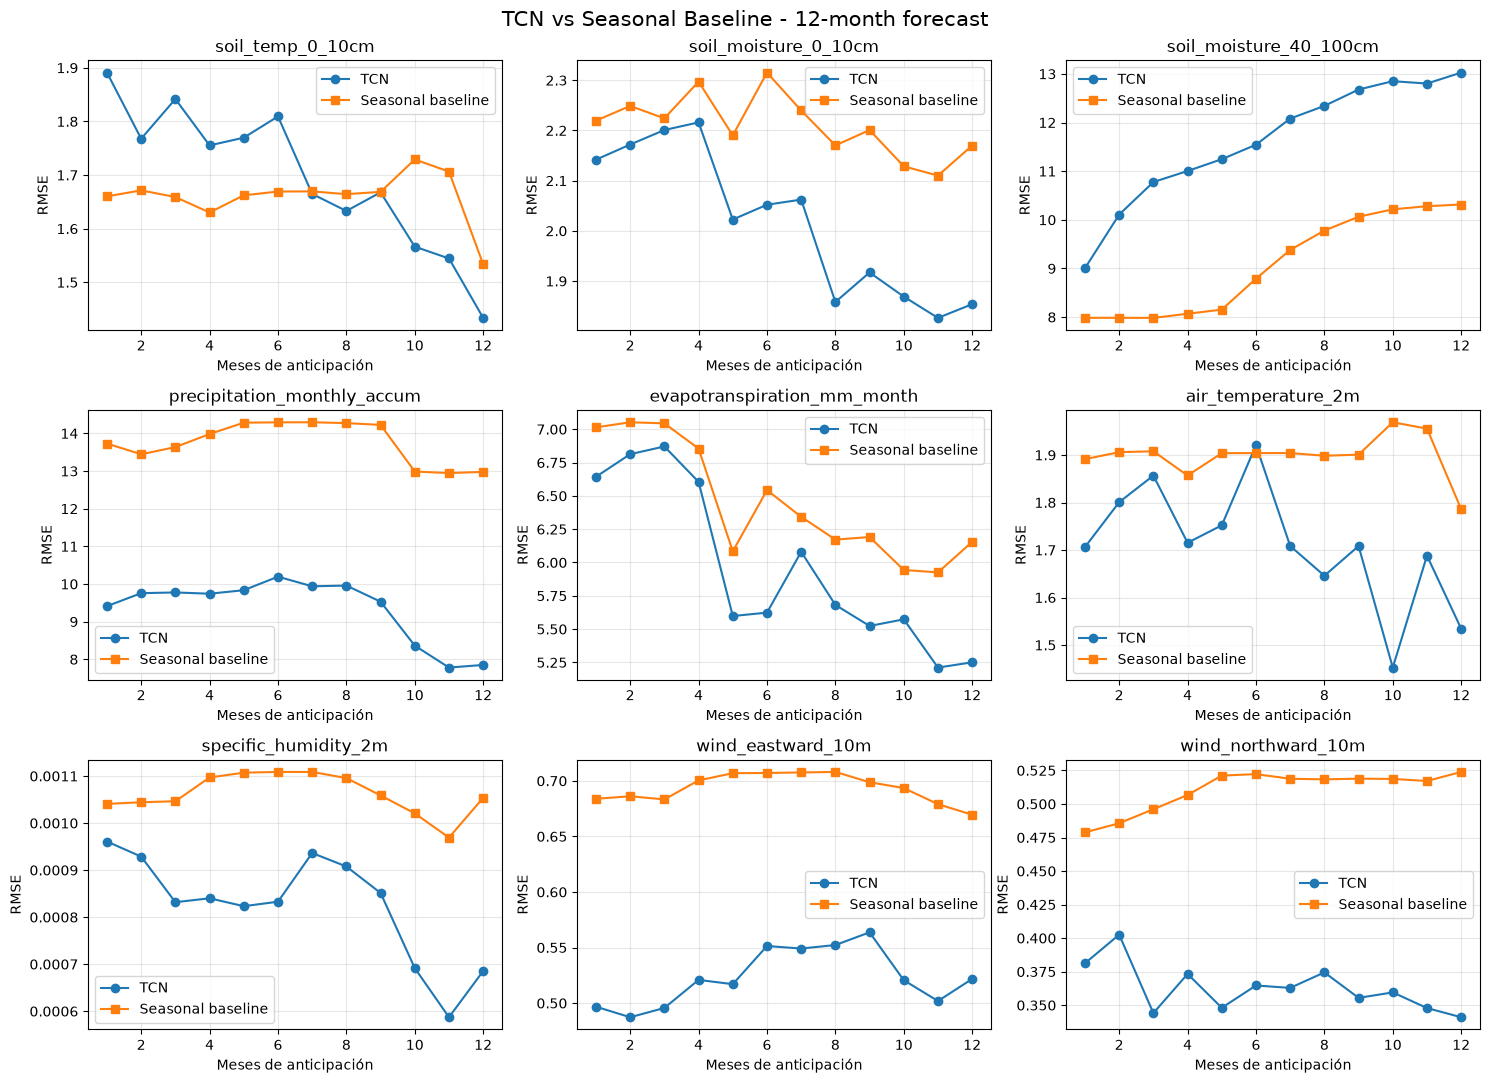

In [23]:
# ============================================================
# EARTH TREND AI
# PASO 13: COMPARACIÓN POR MES DE ANTICIPACIÓN
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

horizon = 12

real = predictions_original[horizon]["real"]
pred_tcn = predictions_original[horizon]["pred"]

X_test = torch_datasets[horizon]["test"]["X"].numpy()

n_samples, n_features, lookback = X_test.shape

# Baseline estacional: mismo mes del año anterior
seasonal_scaled = X_test[
    :, :, lookback - 12:lookback
].transpose(0, 2, 1)

seasonal = scaler.inverse_transform(
    seasonal_scaled.reshape(-1, n_features)
).reshape(n_samples, horizon, n_features)

# Calcular RMSE para cada paso de anticipación
rmse_tcn = np.sqrt(
    np.mean((real - pred_tcn)**2, axis=0)
)

rmse_seasonal = np.sqrt(
    np.mean((real - seasonal)**2, axis=0)
)

# Gráficas
fig, axes = plt.subplots(3, 3, figsize=(15, 11))

for j, ax in enumerate(axes.flat):

    ax.plot(
        range(1, 13),
        rmse_tcn[:, j],
        marker="o",
        label="TCN"
    )

    ax.plot(
        range(1, 13),
        rmse_seasonal[:, j],
        marker="s",
        label="Seasonal baseline"
    )

    ax.set_title(FEATURES[j])
    ax.set_xlabel("Meses de anticipación")
    ax.set_ylabel("RMSE")
    ax.grid(alpha=0.3)
    ax.legend()

plt.suptitle(
    "TCN vs Seasonal Baseline - 12-month forecast",
    fontsize=15
)

plt.tight_layout()
plt.show()

In [24]:
# ============================================================
# EARTH TREND AI - EXPERIMENTO A
# A1. GENERACIÓN DE VENTANAS PARA 24, 36 Y 48 MESES
# ============================================================

import numpy as np
import pandas as pd
import torch
from pathlib import Path

LOOKBACKS_A = [24, 36, 48]
HORIZONS_A = [1, 12]

dates = df["date"].to_numpy()
data_scaled = scaler.transform(df[FEATURES]).astype(np.float32)

# Fechas objetivo comunes a los tres experimentos
VAL_START = pd.Timestamp("2018-01-01")
TEST_START = pd.Timestamp("2022-01-01")
TEST_END_A = pd.Timestamp("2025-09-01")

def make_windows_A(data, dates, lookback, horizon, split):

    X_list, Y_list, date_list = [], [], []

    for i in range(lookback, len(data) - horizon + 1):

        x = data[i-lookback:i]
        y = data[i:i+horizon]
        y_dates = pd.to_datetime(dates[i:i+horizon])

        if not np.isfinite(x).all() or not np.isfinite(y).all():
            continue

        first_date = y_dates[0]
        last_date = y_dates[-1]

        if split == "train":
            valid = last_date <= TRAIN_END

        elif split == "validation":
            valid = (
                first_date >= VAL_START
                and last_date < TEST_START
            )

        elif split == "test":
            valid = (
                first_date >= TEST_START
                and last_date <= TEST_END_A
            )

        else:
            raise ValueError("Split desconocido.")

        if valid:
            X_list.append(x.T)
            Y_list.append(y)
            date_list.append(y_dates)

    if not X_list:
        return (
            np.empty((0, len(FEATURES), lookback), dtype=np.float32),
            np.empty((0, horizon, len(FEATURES)), dtype=np.float32),
            []
        )

    return (
        np.asarray(X_list, dtype=np.float32),
        np.asarray(Y_list, dtype=np.float32),
        date_list
    )


# Construir todos los conjuntos
experiment_A = {}

for lookback in LOOKBACKS_A:

    experiment_A[lookback] = {}

    for horizon in HORIZONS_A:

        experiment_A[lookback][horizon] = {}

        for split in ["train", "validation", "test"]:

            X, Y, target_dates = make_windows_A(
                data_scaled,
                dates,
                lookback,
                horizon,
                split
            )

            experiment_A[lookback][horizon][split] = {
                "X": torch.tensor(X, dtype=torch.float32),
                "Y": torch.tensor(Y, dtype=torch.float32),
                "dates": target_dates
            }

            print(
                f"Lookback {lookback:2d} | "
                f"Horizon {horizon:2d} | "
                f"{split:10s} | "
                f"X={X.shape} | Y={Y.shape}"
            )

print("\nExperimento A: ventanas generadas.")

Lookback 24 | Horizon  1 | train      | X=(180, 9, 24) | Y=(180, 1, 9)
Lookback 24 | Horizon  1 | validation | X=(48, 9, 24) | Y=(48, 1, 9)
Lookback 24 | Horizon  1 | test       | X=(45, 9, 24) | Y=(45, 1, 9)
Lookback 24 | Horizon 12 | train      | X=(169, 9, 24) | Y=(169, 12, 9)
Lookback 24 | Horizon 12 | validation | X=(37, 9, 24) | Y=(37, 12, 9)
Lookback 24 | Horizon 12 | test       | X=(34, 9, 24) | Y=(34, 12, 9)
Lookback 36 | Horizon  1 | train      | X=(168, 9, 36) | Y=(168, 1, 9)
Lookback 36 | Horizon  1 | validation | X=(48, 9, 36) | Y=(48, 1, 9)
Lookback 36 | Horizon  1 | test       | X=(45, 9, 36) | Y=(45, 1, 9)
Lookback 36 | Horizon 12 | train      | X=(157, 9, 36) | Y=(157, 12, 9)
Lookback 36 | Horizon 12 | validation | X=(37, 9, 36) | Y=(37, 12, 9)
Lookback 36 | Horizon 12 | test       | X=(34, 9, 36) | Y=(34, 12, 9)
Lookback 48 | Horizon  1 | train      | X=(156, 9, 48) | Y=(156, 1, 9)
Lookback 48 | Horizon  1 | validation | X=(48, 9, 48) | Y=(48, 1, 9)
Lookback 48 | Hori

In [25]:
# ============================================================
# A2. CONFIGURACIÓN DE LOS MODELOS
# ============================================================

import torch.nn as nn
import copy
import random

SEED_A = 42

def set_seed_A(seed=42):

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def build_model_A(horizon):

    model = EarthTrendTCN(
        input_channels=len(FEATURES),
        output_channels=len(FEATURES),
        hidden_channels=32,
        kernel_size=3,
        dilations=(1, 2, 4, 8),
        dropout=0.1,
        horizon=horizon
    )

    return model.to(DEVICE)


print("Configuración experimental definida.")
print("GPU:", DEVICE)

Configuración experimental definida.
GPU: cuda


In [26]:
# ============================================================
# A3. ENTRENAMIENTO REUTILIZABLE
# ============================================================

from torch.utils.data import TensorDataset, DataLoader

EPOCHS_A = 300
BATCH_SIZE_A = 16
PATIENCE_A = 30
LR_A = 1e-3

CHECKPOINT_A = PROJECT_DIR / "experiment_A_checkpoints"
CHECKPOINT_A.mkdir(exist_ok=True)

def train_experiment_A(model, data, lookback, horizon, seed):

    set_seed_A(seed)

    model = model.to(DEVICE)

    train_ds = TensorDataset(
        data["train"]["X"],
        data["train"]["Y"]
    )

    val_ds = TensorDataset(
        data["validation"]["X"],
        data["validation"]["Y"]
    )

    generator = torch.Generator()
    generator.manual_seed(seed)

    train_loader = DataLoader(
        train_ds,
        batch_size=BATCH_SIZE_A,
        shuffle=True,
        generator=generator,
        pin_memory=torch.cuda.is_available()
    )

    val_loader = DataLoader(
        val_ds,
        batch_size=BATCH_SIZE_A,
        shuffle=False,
        pin_memory=torch.cuda.is_available()
    )

    criterion = nn.HuberLoss(delta=1.0)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LR_A,
        weight_decay=1e-4
    )

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=0.5,
        patience=10,
        min_lr=1e-6
    )

    history = {
        "train_loss": [],
        "val_loss": []
    }

    best_loss = float("inf")
    best_weights = None
    patience_counter = 0

    checkpoint_path = (
        CHECKPOINT_A /
        f"TCN_lb{lookback}_h{horizon}.pth"
    )

    for epoch in range(EPOCHS_A):

        # Entrenamiento
        model.train()

        total_train = 0.0
        n_train = 0

        for xb, yb in train_loader:

            xb = xb.to(DEVICE, non_blocking=True)
            yb = yb.to(DEVICE, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)

            output = model(xb)
            loss = criterion(output, yb)

            loss.backward()

            nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=1.0
            )

            optimizer.step()

            total_train += loss.item() * len(xb)
            n_train += len(xb)

        train_loss = total_train / n_train

        # Validación
        model.eval()

        total_val = 0.0
        n_val = 0

        with torch.no_grad():

            for xb, yb in val_loader:

                xb = xb.to(DEVICE, non_blocking=True)
                yb = yb.to(DEVICE, non_blocking=True)

                output = model(xb)
                loss = criterion(output, yb)

                total_val += loss.item() * len(xb)
                n_val += len(xb)

        val_loss = total_val / n_val

        scheduler.step(val_loss)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)

        # Guardar mejores pesos
        if val_loss < best_loss - 1e-5:

            best_loss = val_loss
            best_weights = copy.deepcopy(model.state_dict())

            torch.save(
                {
                    "model_state_dict": best_weights,
                    "lookback": lookback,
                    "horizon": horizon,
                    "best_val_loss": best_loss,
                    "seed": seed
                },
                checkpoint_path
            )

            patience_counter = 0

        else:
            patience_counter += 1

        if (epoch + 1) % 10 == 0:

            print(
                f"LB={lookback} H={horizon} | "
                f"Epoch {epoch+1:03d} | "
                f"Train={train_loss:.4f} | "
                f"Val={val_loss:.4f}"
            )

        if patience_counter >= PATIENCE_A:
            print(f"Early stopping: época {epoch+1}")
            break

    if best_weights is None:
        raise RuntimeError("No se obtuvo un checkpoint válido.")

    model.load_state_dict(best_weights)

    return model, history, best_loss


print("Función de entrenamiento experimental lista.")

Función de entrenamiento experimental lista.


In [27]:
# ============================================================
# A4. EJECUCIÓN DEL EXPERIMENTO A
# ============================================================

models_A = {}
histories_A = {}
summary_A = []

for lookback in LOOKBACKS_A:

    for horizon in HORIZONS_A:

        print("\n" + "=" * 65)
        print(f"EXPERIMENTO A | LOOKBACK={lookback} | HORIZON={horizon}")
        print("=" * 65)

        # Fijar semilla ANTES de inicializar el modelo
        run_seed = SEED_A

        set_seed_A(run_seed)

        model = build_model_A(horizon)

        model, history, best_val = train_experiment_A(
            model=model,
            data=experiment_A[lookback][horizon],
            lookback=lookback,
            horizon=horizon,
            seed=run_seed
        )

        models_A[(lookback, horizon)] = model
        histories_A[(lookback, horizon)] = history

        summary_A.append({
            "Lookback": lookback,
            "Horizon": horizon,
            "Best validation loss": best_val,
            "Best epoch": int(np.argmin(history["val_loss"])) + 1,
            "Epochs trained": len(history["val_loss"])
        })

        print(f"\nMejor validation loss: {best_val:.5f}")

        # Liberar memoria temporal
        if torch.cuda.is_available():
            torch.cuda.empty_cache()


summary_A_df = pd.DataFrame(summary_A)

display(
    summary_A_df.sort_values(
        ["Horizon", "Best validation loss"]
    ).round(5)
)

summary_A_df.to_csv(
    PROJECT_DIR / "experiment_A_summary.csv",
    index=False
)

print("\nExperimento A completado.")


EXPERIMENTO A | LOOKBACK=24 | HORIZON=1
LB=24 H=1 | Epoch 010 | Train=0.1460 | Val=0.1444
LB=24 H=1 | Epoch 020 | Train=0.1070 | Val=0.1401
LB=24 H=1 | Epoch 030 | Train=0.0862 | Val=0.1403
LB=24 H=1 | Epoch 040 | Train=0.0776 | Val=0.1375
Early stopping: época 49

Mejor validation loss: 0.13226

EXPERIMENTO A | LOOKBACK=24 | HORIZON=12
LB=24 H=12 | Epoch 010 | Train=0.1899 | Val=0.1813
LB=24 H=12 | Epoch 020 | Train=0.1653 | Val=0.1651
LB=24 H=12 | Epoch 030 | Train=0.1493 | Val=0.1592
LB=24 H=12 | Epoch 040 | Train=0.1423 | Val=0.1566
LB=24 H=12 | Epoch 050 | Train=0.1363 | Val=0.1590
LB=24 H=12 | Epoch 060 | Train=0.1285 | Val=0.1655
Early stopping: época 61

Mejor validation loss: 0.15261

EXPERIMENTO A | LOOKBACK=36 | HORIZON=1
LB=36 H=1 | Epoch 010 | Train=0.1422 | Val=0.1281
LB=36 H=1 | Epoch 020 | Train=0.0982 | Val=0.1331
LB=36 H=1 | Epoch 030 | Train=0.0832 | Val=0.1370
LB=36 H=1 | Epoch 040 | Train=0.0793 | Val=0.1361
Early stopping: época 40

Mejor validation loss: 0.12809

,Lookback,Horizon,Best validation loss,Best epoch,Epochs trained
2,36,1,0.12809,10,40
4,48,1,0.12987,9,39
0,24,1,0.13226,19,49
1,24,12,0.15261,31,61
3,36,12,0.15291,29,59
5,48,12,0.16322,41,71



Experimento A completado.


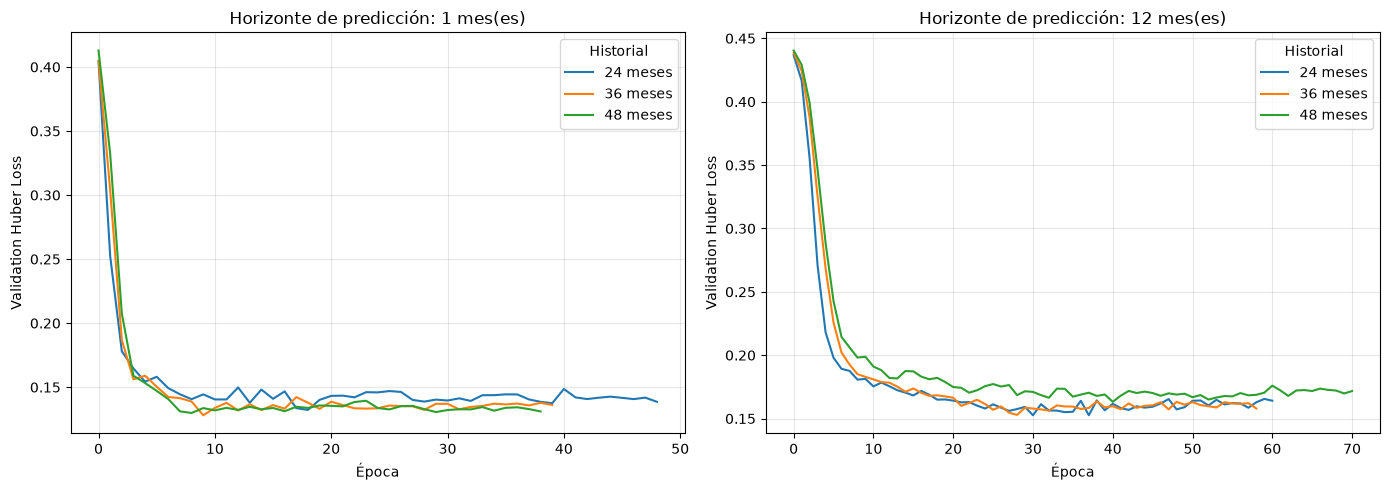

In [28]:
# ============================================================
# A5. COMPARACIÓN DE CURVAS DE VALIDACIÓN
# ============================================================

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, horizon in zip(axes, HORIZONS_A):

    for lookback in LOOKBACKS_A:

        history = histories_A[(lookback, horizon)]

        ax.plot(
            history["val_loss"],
            label=f"{lookback} meses"
        )

    ax.set_title(f"Horizonte de predicción: {horizon} mes(es)")
    ax.set_xlabel("Época")
    ax.set_ylabel("Validation Huber Loss")
    ax.legend(title="Historial")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [29]:
# ============================================================
# A6. EVALUACIÓN EN TEST
# ============================================================

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

test_A_rows = []

for lookback in LOOKBACKS_A:

    for horizon in HORIZONS_A:

        model = models_A[(lookback, horizon)]
        test_data = experiment_A[lookback][horizon]["test"]

        X_test = test_data["X"].to(DEVICE)
        Y_test = test_data["Y"].numpy()

        model.eval()

        with torch.no_grad():
            Y_pred = model(X_test).cpu().numpy()

        n, h, f = Y_test.shape

        real_original = scaler.inverse_transform(
            Y_test.reshape(-1, f)
        ).reshape(n, h, f)

        pred_original = scaler.inverse_transform(
            Y_pred.reshape(-1, f)
        ).reshape(n, h, f)

        for j, variable in enumerate(FEATURES):

            real = real_original[:, :, j].ravel()
            pred = pred_original[:, :, j].ravel()

            test_A_rows.append({
                "Lookback": lookback,
                "Horizon": horizon,
                "Variable": variable,
                "MAE": mean_absolute_error(real, pred),
                "RMSE": np.sqrt(mean_squared_error(real, pred)),
                "R2": r2_score(real, pred)
            })

test_A_df = pd.DataFrame(test_A_rows)

test_A_df.to_csv(
    PROJECT_DIR / "experiment_A_test_metrics.csv",
    index=False
)

display(test_A_df.round(4))

print("Métricas guardadas.")

,Lookback,Horizon,Variable,MAE,RMSE,R2
0,24,1,soil_temp_0_10cm,1.7412,2.0487,0.9168
1,24,1,soil_moisture_0_10cm,1.8045,2.2469,0.5658
2,24,1,soil_moisture_40_100cm,5.7368,6.7067,0.1461
3,24,1,precipitation_monthly_accum,6.9202,8.7250,0.5271
4,24,1,evapotranspiration_mm_month,4.4719,6.1308,0.3862
5,24,1,air_temperature_2m,1.5809,1.8915,0.8877
6,24,1,specific_humidity_2m,0.0007,0.0009,0.7667
7,24,1,wind_eastward_10m,0.3853,0.5066,0.4970
8,24,1,wind_northward_10m,0.2741,0.3500,0.5894
9,24,12,soil_temp_0_10cm,1.1725,1.5080,0.9556


Métricas guardadas.


In [30]:
display(
    summary_A_df.pivot(
        index="Lookback",
        columns="Horizon",
        values="Best validation loss"
    ).round(5)
)

Horizon,1,12
Lookback,,
24,0.13226,0.15261
36,0.12809,0.15291
48,0.12987,0.16322


In [31]:
# ============================================================
# EARTH TREND AI - EXPERIMENTO B
# B1. CONFIGURACIONES DE VARIABLES
# ============================================================

FEATURE_GROUPS_B = {
    "B0_all": FEATURES.copy(),

    "B1_no_deep_moisture": [
        f for f in FEATURES
        if f != "soil_moisture_40_100cm"
    ],

    "B2_no_deep_moisture_no_wind": [
        f for f in FEATURES
        if f not in [
            "soil_moisture_40_100cm",
            "wind_eastward_10m",
            "wind_northward_10m"
        ]
    ]
}

TARGETS_B = FEATURES.copy()

for name, features in FEATURE_GROUPS_B.items():

    print(f"\n{name}")
    print("Variables de entrada:", len(features))

    for feature in features:
        print(" -", feature)

    print("Objetivos:", len(TARGETS_B))


B0_all
Variables de entrada: 9
 - soil_temp_0_10cm
 - soil_moisture_0_10cm
 - soil_moisture_40_100cm
 - precipitation_monthly_accum
 - evapotranspiration_mm_month
 - air_temperature_2m
 - specific_humidity_2m
 - wind_eastward_10m
 - wind_northward_10m
Objetivos: 9

B1_no_deep_moisture
Variables de entrada: 8
 - soil_temp_0_10cm
 - soil_moisture_0_10cm
 - precipitation_monthly_accum
 - evapotranspiration_mm_month
 - air_temperature_2m
 - specific_humidity_2m
 - wind_eastward_10m
 - wind_northward_10m
Objetivos: 9

B2_no_deep_moisture_no_wind
Variables de entrada: 6
 - soil_temp_0_10cm
 - soil_moisture_0_10cm
 - precipitation_monthly_accum
 - evapotranspiration_mm_month
 - air_temperature_2m
 - specific_humidity_2m
Objetivos: 9


In [32]:
import inspect

print(inspect.signature(EarthTrendTCN))

(input_channels=9, output_channels=9, hidden_channels=32, kernel_size=3, dilations=(1, 2, 4, 8), dropout=0.1, horizon=1)


In [33]:
# ============================================================
# EXPERIMENTO B - GENERACIÓN DE DATOS
# ============================================================

LOOKBACK_B = {
    1: 36,
    12: 24
}

experiment_B = {}

for group_name, input_features in FEATURE_GROUPS_B.items():

    experiment_B[group_name] = {}

    input_indices = [
        FEATURES.index(feature)
        for feature in input_features
    ]

    for horizon in HORIZONS_A:

        lookback = LOOKBACK_B[horizon]

        experiment_B[group_name][horizon] = {}

        for split in ["train", "validation", "test"]:

            original = experiment_A[lookback][horizon][split]

            X = original["X"][:, input_indices, :]
            Y = original["Y"]

            experiment_B[group_name][horizon][split] = {
                "X": X.clone(),
                "Y": Y.clone(),
                "dates": original["dates"]
            }

            print(
                f"{group_name} | H={horizon} | {split}: "
                f"X={tuple(X.shape)}, Y={tuple(Y.shape)}"
            )

print("\nDatos del Experimento B preparados.")

B0_all | H=1 | train: X=(168, 9, 36), Y=(168, 1, 9)
B0_all | H=1 | validation: X=(48, 9, 36), Y=(48, 1, 9)
B0_all | H=1 | test: X=(45, 9, 36), Y=(45, 1, 9)
B0_all | H=12 | train: X=(169, 9, 24), Y=(169, 12, 9)
B0_all | H=12 | validation: X=(37, 9, 24), Y=(37, 12, 9)
B0_all | H=12 | test: X=(34, 9, 24), Y=(34, 12, 9)
B1_no_deep_moisture | H=1 | train: X=(168, 8, 36), Y=(168, 1, 9)
B1_no_deep_moisture | H=1 | validation: X=(48, 8, 36), Y=(48, 1, 9)
B1_no_deep_moisture | H=1 | test: X=(45, 8, 36), Y=(45, 1, 9)
B1_no_deep_moisture | H=12 | train: X=(169, 8, 24), Y=(169, 12, 9)
B1_no_deep_moisture | H=12 | validation: X=(37, 8, 24), Y=(37, 12, 9)
B1_no_deep_moisture | H=12 | test: X=(34, 8, 24), Y=(34, 12, 9)
B2_no_deep_moisture_no_wind | H=1 | train: X=(168, 6, 36), Y=(168, 1, 9)
B2_no_deep_moisture_no_wind | H=1 | validation: X=(48, 6, 36), Y=(48, 1, 9)
B2_no_deep_moisture_no_wind | H=1 | test: X=(45, 6, 36), Y=(45, 1, 9)
B2_no_deep_moisture_no_wind | H=12 | train: X=(169, 6, 24), Y=(169,

In [34]:
# ============================================================
# EXPERIMENTO B - ENTRENAMIENTO
# ============================================================

models_B = {}
histories_B = {}
summary_B = []

CHECKPOINT_B = PROJECT_DIR / "experiment_B_checkpoints"
CHECKPOINT_B.mkdir(exist_ok=True)

for group_name, input_features in FEATURE_GROUPS_B.items():

    for horizon in HORIZONS_A:

        lookback = LOOKBACK_B[horizon]

        print("\n" + "=" * 65)
        print(f"GRUPO: {group_name}")
        print(f"ENTRADAS: {len(input_features)}")
        print(f"HORIZONTE: {horizon}")
        print(f"LOOKBACK: {lookback}")
        print("=" * 65)

        set_seed_A(SEED_A)

        model = EarthTrendTCN(
            input_channels=len(input_features),
            output_channels=len(TARGETS_B),
            hidden_channels=32,
            kernel_size=3,
            dilations=(1, 2, 4, 8),
            dropout=0.1,
            horizon=horizon
        ).to(DEVICE)

        model, history, best_val = train_experiment_A(
            model=model,
            data=experiment_B[group_name][horizon],
            lookback=lookback,
            horizon=horizon,
            seed=SEED_A
        )

        models_B[(group_name, horizon)] = model
        histories_B[(group_name, horizon)] = history

        # Guardar checkpoint independiente del experimento A
        torch.save(
            {
                "model_state_dict": model.state_dict(),
                "input_features": input_features,
                "target_features": TARGETS_B,
                "lookback": lookback,
                "horizon": horizon,
                "best_val_loss": best_val
            },
            CHECKPOINT_B / f"{group_name}_h{horizon}.pth"
        )

        summary_B.append({
            "Group": group_name,
            "Horizon": horizon,
            "Lookback": lookback,
            "Input variables": len(input_features),
            "Best validation loss": best_val,
            "Best epoch": int(np.argmin(history["val_loss"])) + 1
        })

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

summary_B_df = pd.DataFrame(summary_B)

display(summary_B_df.round(5))

summary_B_df.to_csv(
    PROJECT_DIR / "experiment_B_summary.csv",
    index=False
)

print("\nExperimento B completado.")


GRUPO: B0_all
ENTRADAS: 9
HORIZONTE: 1
LOOKBACK: 36
LB=36 H=1 | Epoch 010 | Train=0.1420 | Val=0.1273
LB=36 H=1 | Epoch 020 | Train=0.0979 | Val=0.1356
LB=36 H=1 | Epoch 030 | Train=0.0842 | Val=0.1380
LB=36 H=1 | Epoch 040 | Train=0.0795 | Val=0.1379
Early stopping: época 40

GRUPO: B0_all
ENTRADAS: 9
HORIZONTE: 12
LOOKBACK: 24
LB=24 H=12 | Epoch 010 | Train=0.1896 | Val=0.1810
LB=24 H=12 | Epoch 020 | Train=0.1656 | Val=0.1641
LB=24 H=12 | Epoch 030 | Train=0.1497 | Val=0.1570
LB=24 H=12 | Epoch 040 | Train=0.1424 | Val=0.1567
LB=24 H=12 | Epoch 050 | Train=0.1342 | Val=0.1647
LB=24 H=12 | Epoch 060 | Train=0.1241 | Val=0.1725
Early stopping: época 68

GRUPO: B1_no_deep_moisture
ENTRADAS: 8
HORIZONTE: 1
LOOKBACK: 36
LB=36 H=1 | Epoch 010 | Train=0.1526 | Val=0.1481
LB=36 H=1 | Epoch 020 | Train=0.1065 | Val=0.1410
LB=36 H=1 | Epoch 030 | Train=0.0870 | Val=0.1431
LB=36 H=1 | Epoch 040 | Train=0.0666 | Val=0.1494
Early stopping: época 47

GRUPO: B1_no_deep_moisture
ENTRADAS: 8
HORIZO

,Group,Horizon,Lookback,Input variables,Best validation loss,Best epoch
0,B0_all,1,36,9,0.12732,10
1,B0_all,12,24,9,0.15123,38
2,B1_no_deep_moisture,1,36,8,0.13367,17
3,B1_no_deep_moisture,12,24,8,0.15301,50
4,B2_no_deep_moisture_no_wind,1,36,6,0.14012,32
5,B2_no_deep_moisture_no_wind,12,24,6,0.15360,40



Experimento B completado.


In [35]:
# ============================================================
# EXPERIMENTO B - EVALUACIÓN
# ============================================================

results_B = []

for group_name, input_features in FEATURE_GROUPS_B.items():

    for horizon in HORIZONS_A:

        model = models_B[(group_name, horizon)]

        test_data = experiment_B[group_name][horizon]["test"]

        X_test = test_data["X"].to(DEVICE)
        Y_test = test_data["Y"].numpy()

        model.eval()

        with torch.no_grad():
            Y_pred = model(X_test).cpu().numpy()

        n, h, f = Y_test.shape

        real = scaler.inverse_transform(
            Y_test.reshape(-1, f)
        ).reshape(n, h, f)

        pred = scaler.inverse_transform(
            Y_pred.reshape(-1, f)
        ).reshape(n, h, f)

        for j, variable in enumerate(TARGETS_B):

            y_true = real[:, :, j].ravel()
            y_pred = pred[:, :, j].ravel()

            results_B.append({
                "Group": group_name,
                "Horizon": horizon,
                "Variable": variable,
                "MAE": mean_absolute_error(y_true, y_pred),
                "RMSE": np.sqrt(
                    mean_squared_error(y_true, y_pred)
                ),
                "R2": r2_score(y_true, y_pred)
            })

results_B_df = pd.DataFrame(results_B)

results_B_df.to_csv(
    PROJECT_DIR / "experiment_B_test_metrics.csv",
    index=False
)

display(results_B_df.round(4))

print("\nEvaluación B completada.")

,Group,Horizon,Variable,MAE,RMSE,R2
0,B0_all,1,soil_temp_0_10cm,1.5509,1.8539,0.9319
1,B0_all,1,soil_moisture_0_10cm,1.5920,1.9088,0.6866
2,B0_all,1,soil_moisture_40_100cm,5.7512,6.6190,0.1683
3,B0_all,1,precipitation_monthly_accum,7.4992,9.3232,0.4601
4,B0_all,1,evapotranspiration_mm_month,4.3218,5.8401,0.4430
5,B0_all,1,air_temperature_2m,1.2935,1.6032,0.9193
6,B0_all,1,specific_humidity_2m,0.0007,0.0009,0.7784
7,B0_all,1,wind_eastward_10m,0.4106,0.5292,0.4511
8,B0_all,1,wind_northward_10m,0.2907,0.3726,0.5347
9,B0_all,12,soil_temp_0_10cm,1.1950,1.5487,0.9531



Evaluación B completada.


In [36]:
# ============================================================
# EXPERIMENTO B - COMPARACIÓN DE VALIDACIÓN
# ============================================================

display(
    summary_B_df.pivot(
        index="Group",
        columns="Horizon",
        values="Best validation loss"
    ).round(5)
)

Horizon,1,12
Group,,
B0_all,0.12732,0.15123
B1_no_deep_moisture,0.13367,0.15301
B2_no_deep_moisture_no_wind,0.14012,0.15360


In [37]:
import inspect

print("Firma del modelo:")
print(inspect.signature(EarthTrendTCN))

print("\nFirma de la función de entrenamiento:")
print(inspect.signature(train_experiment_A))

print("\nDispositivo:")
print(DEVICE)

print("\nConfiguración B0:")
print(FEATURE_GROUPS_B["B0_all"])

Firma del modelo:
(input_channels=9, output_channels=9, hidden_channels=32, kernel_size=3, dilations=(1, 2, 4, 8), dropout=0.1, horizon=1)

Firma de la función de entrenamiento:
(model, data, lookback, horizon, seed)

Dispositivo:
cuda

Configuración B0:
['soil_temp_0_10cm', 'soil_moisture_0_10cm', 'soil_moisture_40_100cm', 'precipitation_monthly_accum', 'evapotranspiration_mm_month', 'air_temperature_2m', 'specific_humidity_2m', 'wind_eastward_10m', 'wind_northward_10m']


In [38]:
import inspect

# Revisar cómo funciona el entrenamiento
print("=" * 65)
print("CÓDIGO DE train_experiment_A")
print("=" * 65)

print(inspect.getsource(train_experiment_A))

# Revisar las estructuras de datos disponibles
print("\n" + "=" * 65)
print("ESTRUCTURAS DISPONIBLES")
print("=" * 65)

candidates = [
    "torch_datasets",
    "datasets",
    "FEATURE_GROUPS_B",
    "summary_B_df",
    "trained_models",
    "training_histories"
]

for name in candidates:
    if name in globals():
        obj = globals()[name]
        print(f"\n{name}: {type(obj)}")

        if isinstance(obj, dict):
            print("Claves:", list(obj.keys()))

            for key, value in list(obj.items())[:2]:
                print(f"  [{key}]: {type(value)}")

                if isinstance(value, dict):
                    for subkey, subvalue in list(value.items())[:3]:
                        print(
                            f"    {subkey}: {type(subvalue)}",
                            getattr(subvalue, "shape", "")
                        )

CÓDIGO DE train_experiment_A
def train_experiment_A(model, data, lookback, horizon, seed):

    set_seed_A(seed)

    model = model.to(DEVICE)

    train_ds = TensorDataset(
        data["train"]["X"],
        data["train"]["Y"]
    )

    val_ds = TensorDataset(
        data["validation"]["X"],
        data["validation"]["Y"]
    )

    generator = torch.Generator()
    generator.manual_seed(seed)

    train_loader = DataLoader(
        train_ds,
        batch_size=BATCH_SIZE_A,
        shuffle=True,
        generator=generator,
        pin_memory=torch.cuda.is_available()
    )

    val_loader = DataLoader(
        val_ds,
        batch_size=BATCH_SIZE_A,
        shuffle=False,
        pin_memory=torch.cuda.is_available()
    )

    criterion = nn.HuberLoss(delta=1.0)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LR_A,
        weight_decay=1e-4
    )

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
       

In [39]:
# ============================================================
# EARTH TREND AI - VERIFICACIÓN DE DATOS PARA EXPERIMENTO C
# ============================================================

print("=" * 65)
print("VERIFICACIÓN DE TENSORES")
print("=" * 65)

for horizon in [1, 12]:

    print(f"\nHORIZONTE: {horizon} MES(ES)")

    for split in ["train", "validation", "test"]:

        X = torch_datasets[horizon][split]["X"]
        Y = torch_datasets[horizon][split]["Y"]

        print(
            f"{split:12s} | "
            f"X: {tuple(X.shape)} | "
            f"Y: {tuple(Y.shape)}"
        )

print("\n" + "=" * 65)
print("CONFIGURACIÓN DE ENTRENAMIENTO")
print("=" * 65)

print("BATCH_SIZE_A:", BATCH_SIZE_A)
print("LR_A:", LR_A)
print("EPOCHS_A:", EPOCHS_A)
print("PATIENCE_A:", PATIENCE_A)
print("DEVICE:", DEVICE)

print("\n" + "=" * 65)
print("DIRECTORIOS DE CHECKPOINT")
print("=" * 65)

print("CHECKPOINT_A:", CHECKPOINT_A)

VERIFICACIÓN DE TENSORES

HORIZONTE: 1 MES(ES)
train        | X: (180, 9, 24) | Y: (180, 1, 9)
validation   | X: (48, 9, 24) | Y: (48, 1, 9)
test         | X: (45, 9, 24) | Y: (45, 1, 9)

HORIZONTE: 12 MES(ES)
train        | X: (169, 9, 24) | Y: (169, 12, 9)
validation   | X: (37, 9, 24) | Y: (37, 12, 9)
test         | X: (34, 9, 24) | Y: (34, 12, 9)

CONFIGURACIÓN DE ENTRENAMIENTO
BATCH_SIZE_A: 16
LR_A: 0.001
EPOCHS_A: 300
PATIENCE_A: 30
DEVICE: cuda

DIRECTORIOS DE CHECKPOINT
CHECKPOINT_A: C:\Users\Roberto Garcés\Downloads\EarthTrend_AI_audit_and_candidate_v1_0\experiment_A_checkpoints


In [40]:
# ============================================================
# EARTH TREND AI
# EXPERIMENTO C - OPTIMIZACIÓN DE ARQUITECTURA
# ============================================================

import os
import copy
import torch
import pandas as pd
import numpy as np

import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader
from pathlib import Path

# ------------------------------------------------------------
# 1. CONFIGURACIONES
# ------------------------------------------------------------

CONFIGURATIONS_C = {
    "C0": {
        "hidden_channels": 32,
        "dropout": 0.10,
        "kernel_size": 3
    },
    "C1": {
        "hidden_channels": 64,
        "dropout": 0.10,
        "kernel_size": 3
    },
    "C2": {
        "hidden_channels": 96,
        "dropout": 0.10,
        "kernel_size": 3
    },
    "C3": {
        "hidden_channels": 32,
        "dropout": 0.05,
        "kernel_size": 3
    },
    "C4": {
        "hidden_channels": 32,
        "dropout": 0.20,
        "kernel_size": 3
    },
    "C5": {
        "hidden_channels": 32,
        "dropout": 0.10,
        "kernel_size": 5
    }
}

LOOKBACKS_C = {
    1: 36,
    12: 24
}

SEED_C = 42

# Directorio independiente: no toca A ni B
CHECKPOINT_C = (
    Path(CHECKPOINT_A).parent /
    "experiment_C_checkpoints"
)

CHECKPOINT_C.mkdir(
    parents=True,
    exist_ok=True
)

print("Experimento C configurado")
print("Dispositivo:", DEVICE)
print("Directorio:", CHECKPOINT_C)

Experimento C configurado
Dispositivo: cuda
Directorio: C:\Users\Roberto Garcés\Downloads\EarthTrend_AI_audit_and_candidate_v1_0\experiment_C_checkpoints


In [41]:
# ============================================================
# FUNCIÓN DE ENTRENAMIENTO - EXPERIMENTO C
# ============================================================

def train_experiment_C(
    model,
    data,
    lookback,
    horizon,
    seed,
    config_name,
    config
):

    set_seed_A(seed)

    model = model.to(DEVICE)

    train_ds = TensorDataset(
        data["train"]["X"],
        data["train"]["Y"]
    )

    val_ds = TensorDataset(
        data["validation"]["X"],
        data["validation"]["Y"]
    )

    generator = torch.Generator()
    generator.manual_seed(seed)

    train_loader = DataLoader(
        train_ds,
        batch_size=BATCH_SIZE_A,
        shuffle=True,
        generator=generator,
        pin_memory=(DEVICE.type == "cuda")
    )

    val_loader = DataLoader(
        val_ds,
        batch_size=BATCH_SIZE_A,
        shuffle=False,
        pin_memory=(DEVICE.type == "cuda")
    )

    criterion = nn.HuberLoss(delta=1.0)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LR_A,
        weight_decay=1e-4
    )

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=0.5,
        patience=10,
        min_lr=1e-6
    )

    history = {
        "train_loss": [],
        "val_loss": []
    }

    best_loss = float("inf")
    best_weights = None
    patience_counter = 0

    # Carpeta única por configuración y horizonte
    experiment_dir = (
        CHECKPOINT_C /
        f"{config_name}_lb{lookback}_h{horizon}"
    )

    experiment_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    checkpoint_path = (
        experiment_dir /
        "best_model.pth"
    )

    print(
        f"\nIniciando {config_name} | "
        f"LB={lookback} | H={horizon}"
    )

    for epoch in range(EPOCHS_A):

        # -------------------------
        # ENTRENAMIENTO
        # -------------------------

        model.train()

        total_train = 0.0
        n_train = 0

        for xb, yb in train_loader:

            xb = xb.to(DEVICE, non_blocking=True)
            yb = yb.to(DEVICE, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)

            output = model(xb)

            loss = criterion(output, yb)

            loss.backward()

            nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=1.0
            )

            optimizer.step()

            total_train += loss.item() * len(xb)
            n_train += len(xb)

        train_loss = total_train / n_train

        # -------------------------
        # VALIDACIÓN
        # -------------------------

        model.eval()

        total_val = 0.0
        n_val = 0

        with torch.no_grad():

            for xb, yb in val_loader:

                xb = xb.to(DEVICE, non_blocking=True)
                yb = yb.to(DEVICE, non_blocking=True)

                output = model(xb)

                loss = criterion(output, yb)

                total_val += loss.item() * len(xb)
                n_val += len(xb)

        val_loss = total_val / n_val

        scheduler.step(val_loss)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)

        # -------------------------
        # CHECKPOINT
        # -------------------------

        if val_loss < best_loss - 1e-5:

            best_loss = val_loss

            best_weights = copy.deepcopy(
                model.state_dict()
            )

            torch.save(
                {
                    "model_state_dict": best_weights,
                    "config_name": config_name,
                    "config": config,
                    "lookback": lookback,
                    "horizon": horizon,
                    "best_val_loss": best_loss,
                    "seed": seed
                },
                checkpoint_path
            )

            patience_counter = 0

        else:

            patience_counter += 1

        # -------------------------
        # PROGRESO
        # -------------------------

        if (epoch + 1) % 10 == 0:

            print(
                f"{config_name} | "
                f"Epoch {epoch+1:03d} | "
                f"Train={train_loss:.5f} | "
                f"Val={val_loss:.5f}"
            )

        if patience_counter >= PATIENCE_A:

            print(
                f"Early stopping en época {epoch+1}"
            )

            break

    if best_weights is None:

        raise RuntimeError(
            f"No se obtuvo checkpoint para {config_name}"
        )

    model.load_state_dict(best_weights)

    print(
        f"{config_name} terminado | "
        f"Mejor validación={best_loss:.6f}"
    )

    return model, history, best_loss

In [42]:
# ============================================================
# EXPERIMENTO C - EJECUCIÓN COMPLETA
# ============================================================

models_C = {}
histories_C = {}
results_C = []

for horizon in [1, 12]:

    lookback = LOOKBACKS_C[horizon]

    data = torch_datasets[horizon]

    print("\n" + "=" * 65)
    print(f"HORIZONTE: {horizon} MESES")
    print("=" * 65)

    for config_name, config in CONFIGURATIONS_C.items():

        print("\n" + "-" * 55)

        model = EarthTrendTCN(
            input_channels=9,
            output_channels=9,
            hidden_channels=config["hidden_channels"],
            kernel_size=config["kernel_size"],
            dilations=(1, 2, 4, 8),
            dropout=config["dropout"],
            horizon=horizon
        )

        trained_model, history, best_loss = train_experiment_C(
            model=model,
            data=data,
            lookback=lookback,
            horizon=horizon,
            seed=SEED_C,
            config_name=config_name,
            config=config
        )

        key = (config_name, horizon)

        models_C[key] = trained_model
        histories_C[key] = history

        results_C.append({
            "Configuration": config_name,
            "Horizon": horizon,
            "Lookback": lookback,
            "Filters": config["hidden_channels"],
            "Dropout": config["dropout"],
            "Kernel": config["kernel_size"],
            "Best validation loss": best_loss
        })

        # Liberar memoria de GPU
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()

    print(f"\nHorizonte {horizon} completado.")

summary_C_df = pd.DataFrame(results_C)

print("\n" + "=" * 65)
print("EXPERIMENTO C COMPLETADO")
print("=" * 65)

display(
    summary_C_df.sort_values(
        ["Horizon", "Best validation loss"]
    ).reset_index(drop=True)
)


HORIZONTE: 1 MESES

-------------------------------------------------------

Iniciando C0 | LB=36 | H=1
C0 | Epoch 010 | Train=0.14495 | Val=0.13944
C0 | Epoch 020 | Train=0.10474 | Val=0.14852
C0 | Epoch 030 | Train=0.08501 | Val=0.15646
C0 | Epoch 040 | Train=0.07546 | Val=0.15928
Early stopping en época 40
C0 terminado | Mejor validación=0.139442

-------------------------------------------------------

Iniciando C1 | LB=36 | H=1
C1 | Epoch 010 | Train=0.11497 | Val=0.13602
C1 | Epoch 020 | Train=0.06974 | Val=0.13643
C1 | Epoch 030 | Train=0.05272 | Val=0.13278
C1 | Epoch 040 | Train=0.04737 | Val=0.13274
Early stopping en época 41
C1 terminado | Mejor validación=0.121366

-------------------------------------------------------

Iniciando C2 | LB=36 | H=1
C2 | Epoch 010 | Train=0.09722 | Val=0.15202
C2 | Epoch 020 | Train=0.05554 | Val=0.15361
C2 | Epoch 030 | Train=0.04167 | Val=0.14798
Early stopping en época 35
C2 terminado | Mejor validación=0.139001

-------------------------

,Configuration,Horizon,Lookback,Filters,Dropout,Kernel,Best validation loss
0,C1,1,36,64,0.10,3,0.121366
1,C3,1,36,32,0.05,3,0.125396
2,C5,1,36,32,0.10,5,0.132691
3,C4,1,36,32,0.20,3,0.134759
4,C2,1,36,96,0.10,3,0.139001
5,C0,1,36,32,0.10,3,0.139442
6,C4,12,24,32,0.20,3,0.150371
7,C0,12,24,32,0.10,3,0.150632
8,C5,12,24,32,0.10,5,0.151288
9,C1,12,24,64,0.10,3,0.152716


In [43]:
# ============================================================
# SELECCIÓN DE ARQUITECTURA POR HORIZONTE
# ============================================================

best_C = (
    summary_C_df
    .sort_values("Best validation loss")
    .groupby("Horizon")
    .first()
    .reset_index()
)

print("MEJORES CONFIGURACIONES DE EXPERIMENTO C")

display(best_C)

print("\nComparación resumida:")

display(
    summary_C_df.pivot(
        index="Configuration",
        columns="Horizon",
        values="Best validation loss"
    ).round(5)
)

MEJORES CONFIGURACIONES DE EXPERIMENTO C


,Horizon,Configuration,Lookback,Filters,Dropout,Kernel,Best validation loss
0,1,C1,36,64,0.1,3,0.121366
1,12,C4,24,32,0.2,3,0.150371



Comparación resumida:


Horizon,1,12
Configuration,,
C0,0.13944,0.15063
C1,0.12137,0.15272
C2,0.13900,0.15316
C3,0.12540,0.15398
C4,0.13476,0.15037
C5,0.13269,0.15129


In [44]:
# ============================================================
# EARTH TREND AI - EXPERIMENTO D
# ESTABILIDAD DE LAS ARQUITECTURAS GANADORAS
# ============================================================

from pathlib import Path
import copy
import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

SEEDS_D = [21, 42, 63, 84, 105]

WINNERS_D = {
    1: {
        "name": "C1",
        "lookback": 36,
        "hidden_channels": 64,
        "dropout": 0.10,
        "kernel_size": 3
    },
    12: {
        "name": "C4",
        "lookback": 24,
        "hidden_channels": 32,
        "dropout": 0.20,
        "kernel_size": 3
    }
}

CHECKPOINT_D = (
    Path(CHECKPOINT_A).parent /
    "experiment_D_checkpoints"
)

CHECKPOINT_D.mkdir(
    parents=True,
    exist_ok=True
)

print("Experimento D configurado")
print("GPU:", DEVICE)
print("Semillas:", SEEDS_D)
print("Directorio:", CHECKPOINT_D)

Experimento D configurado
GPU: cuda
Semillas: [21, 42, 63, 84, 105]
Directorio: C:\Users\Roberto Garcés\Downloads\EarthTrend_AI_audit_and_candidate_v1_0\experiment_D_checkpoints


In [45]:
# ============================================================
# FUNCIÓN DE ENTRENAMIENTO - EXPERIMENTO D
# ============================================================

def train_experiment_D(
    model,
    data,
    lookback,
    horizon,
    seed,
    config_name
):

    set_seed_A(seed)

    model = model.to(DEVICE)

    train_ds = TensorDataset(
        data["train"]["X"],
        data["train"]["Y"]
    )

    val_ds = TensorDataset(
        data["validation"]["X"],
        data["validation"]["Y"]
    )

    generator = torch.Generator()
    generator.manual_seed(seed)

    train_loader = DataLoader(
        train_ds,
        batch_size=BATCH_SIZE_A,
        shuffle=True,
        generator=generator,
        pin_memory=(DEVICE.type == "cuda")
    )

    val_loader = DataLoader(
        val_ds,
        batch_size=BATCH_SIZE_A,
        shuffle=False,
        pin_memory=(DEVICE.type == "cuda")
    )

    criterion = nn.HuberLoss(delta=1.0)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LR_A,
        weight_decay=1e-4
    )

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=0.5,
        patience=10,
        min_lr=1e-6
    )

    history = {
        "train_loss": [],
        "val_loss": []
    }

    best_loss = float("inf")
    best_weights = None
    best_epoch = 0
    patience_counter = 0

    run_dir = (
        CHECKPOINT_D /
        f"{config_name}_h{horizon}_seed{seed}"
    )

    run_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    checkpoint_path = run_dir / "best_model.pth"

    print(
        f"\n{config_name} | Horizonte={horizon} | "
        f"Semilla={seed}"
    )

    for epoch in range(EPOCHS_A):

        # Entrenamiento
        model.train()

        total_train = 0.0
        n_train = 0

        for xb, yb in train_loader:

            xb = xb.to(DEVICE, non_blocking=True)
            yb = yb.to(DEVICE, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)

            output = model(xb)
            loss = criterion(output, yb)

            loss.backward()

            nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=1.0
            )

            optimizer.step()

            total_train += loss.item() * len(xb)
            n_train += len(xb)

        train_loss = total_train / n_train

        # Validación
        model.eval()

        total_val = 0.0
        n_val = 0

        with torch.no_grad():

            for xb, yb in val_loader:

                xb = xb.to(DEVICE, non_blocking=True)
                yb = yb.to(DEVICE, non_blocking=True)

                output = model(xb)
                loss = criterion(output, yb)

                total_val += loss.item() * len(xb)
                n_val += len(xb)

        val_loss = total_val / n_val

        scheduler.step(val_loss)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)

        if val_loss < best_loss - 1e-5:

            best_loss = val_loss
            best_epoch = epoch + 1

            best_weights = copy.deepcopy(
                model.state_dict()
            )

            torch.save(
                {
                    "model_state_dict": best_weights,
                    "config_name": config_name,
                    "lookback": lookback,
                    "horizon": horizon,
                    "seed": seed,
                    "best_val_loss": best_loss,
                    "best_epoch": best_epoch
                },
                checkpoint_path
            )

            patience_counter = 0

        else:

            patience_counter += 1

        if (epoch + 1) % 10 == 0:

            print(
                f"Epoch {epoch+1:03d} | "
                f"Train={train_loss:.5f} | "
                f"Val={val_loss:.5f}"
            )

        if patience_counter >= PATIENCE_A:

            print(
                f"Early stopping en época {epoch+1}"
            )

            break

    if best_weights is None:
        raise RuntimeError("No se obtuvo un modelo válido.")

    model.load_state_dict(best_weights)

    print(
        f"Terminado | Mejor val={best_loss:.6f} | "
        f"Época={best_epoch}"
    )

    return model, history, best_loss, best_epoch

In [46]:
# ============================================================
# EXPERIMENTO D - ENTRENAMIENTO
# ============================================================

models_D = {}
histories_D = {}
results_D = []

for horizon, config in WINNERS_D.items():

    print("\n" + "=" * 65)
    print(f"HORIZONTE: {horizon} MESES")
    print("=" * 65)

    lookback = config["lookback"]
    data = torch_datasets[horizon]

    for seed in SEEDS_D:

        model = EarthTrendTCN(
            input_channels=9,
            output_channels=9,
            hidden_channels=config["hidden_channels"],
            kernel_size=config["kernel_size"],
            dilations=(1, 2, 4, 8),
            dropout=config["dropout"],
            horizon=horizon
        )

        trained_model, history, best_loss, best_epoch = (
            train_experiment_D(
                model=model,
                data=data,
                lookback=lookback,
                horizon=horizon,
                seed=seed,
                config_name=config["name"]
            )
        )

        key = (horizon, seed)

        models_D[key] = trained_model
        histories_D[key] = history

        results_D.append({
            "Configuration": config["name"],
            "Horizon": horizon,
            "Lookback": lookback,
            "Seed": seed,
            "Best validation loss": best_loss,
            "Best epoch": best_epoch
        })

        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()

summary_D_df = pd.DataFrame(results_D)

print("\nEXPERIMENTO D COMPLETADO")

display(
    summary_D_df.sort_values(
        ["Horizon", "Seed"]
    ).reset_index(drop=True)
)


HORIZONTE: 1 MESES

C1 | Horizonte=1 | Semilla=21
Epoch 010 | Train=0.10411 | Val=0.14629
Epoch 020 | Train=0.07769 | Val=0.13834
Epoch 030 | Train=0.05078 | Val=0.13603
Epoch 040 | Train=0.04546 | Val=0.13662
Early stopping en época 42
Terminado | Mejor val=0.132138 | Época=12

C1 | Horizonte=1 | Semilla=42
Epoch 010 | Train=0.12036 | Val=0.14659
Epoch 020 | Train=0.06974 | Val=0.15478
Epoch 030 | Train=0.05444 | Val=0.14949
Epoch 040 | Train=0.05119 | Val=0.14553
Epoch 050 | Train=0.04422 | Val=0.14120
Epoch 060 | Train=0.04514 | Val=0.14324
Epoch 070 | Train=0.04216 | Val=0.14226
Early stopping en época 79
Terminado | Mejor val=0.138778 | Época=49

C1 | Horizonte=1 | Semilla=63
Epoch 010 | Train=0.11542 | Val=0.15917
Epoch 020 | Train=0.07382 | Val=0.14597
Epoch 030 | Train=0.05084 | Val=0.14329
Epoch 040 | Train=0.04467 | Val=0.14591
Early stopping en época 41
Terminado | Mejor val=0.140873 | Época=11

C1 | Horizonte=1 | Semilla=84
Epoch 010 | Train=0.11204 | Val=0.13107
Epoch 020

,Configuration,Horizon,Lookback,Seed,Best validation loss,Best epoch
0,C1,1,36,21,0.132138,12
1,C1,1,36,42,0.138778,49
2,C1,1,36,63,0.140873,11
3,C1,1,36,84,0.131072,10
4,C1,1,36,105,0.131909,12
5,C4,12,24,21,0.150139,51
6,C4,12,24,42,0.147835,80
7,C4,12,24,63,0.152659,60
8,C4,12,24,84,0.150965,85
9,C4,12,24,105,0.150261,67


In [47]:
# ============================================================
# EXPERIMENTO D - ESTABILIDAD
# ============================================================

stability_D = (
    summary_D_df
    .groupby(["Configuration", "Horizon"])
    ["Best validation loss"]
    .agg(
        Mean="mean",
        Std="std",
        Minimum="min",
        Maximum="max"
    )
    .reset_index()
)

print("ESTABILIDAD DE LOS MODELOS")

display(stability_D.round(6))

# Coeficiente de variación
stability_D["CV_percent"] = (
    100 * stability_D["Std"] / stability_D["Mean"]
)

print("\nCOEFICIENTE DE VARIACIÓN")

display(
    stability_D[
        ["Configuration", "Horizon", "CV_percent"]
    ].round(3)
)

ESTABILIDAD DE LOS MODELOS


,Configuration,Horizon,Mean,Std,Minimum,Maximum
0,C1,1,0.134954,0.004526,0.131072,0.140873
1,C4,12,0.150372,0.001738,0.147835,0.152659



COEFICIENTE DE VARIACIÓN


,Configuration,Horizon,CV_percent
0,C1,1,3.354
1,C4,12,1.156


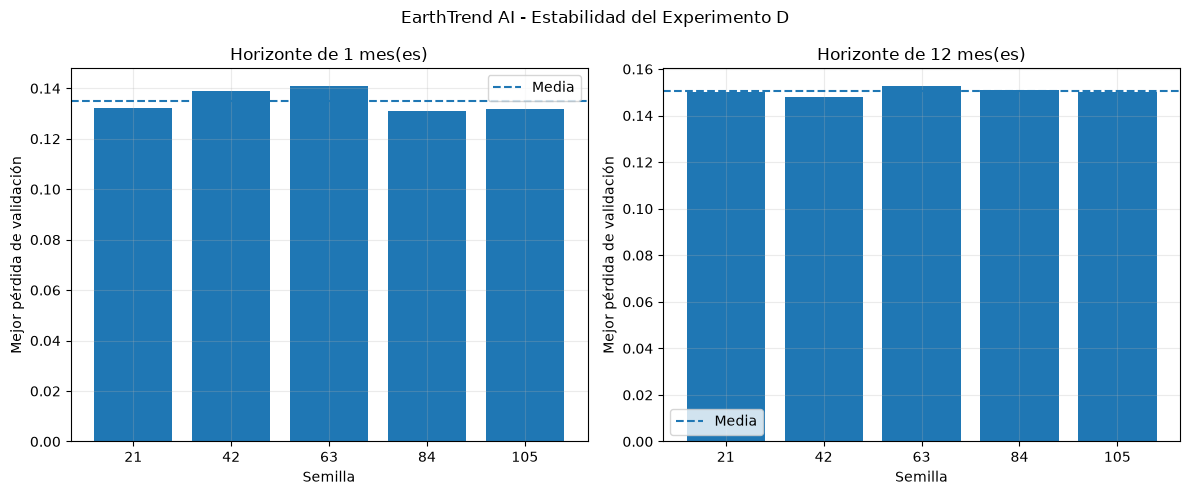

In [48]:
# ============================================================
# COMPARACIÓN DE PÉRDIDAS ENTRE SEMILLAS
# ============================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 5)
)

for ax, horizon in zip(axes, [1, 12]):

    subset = summary_D_df[
        summary_D_df["Horizon"] == horizon
    ]

    ax.bar(
        subset["Seed"].astype(str),
        subset["Best validation loss"]
    )

    ax.axhline(
        subset["Best validation loss"].mean(),
        linestyle="--",
        label="Media"
    )

    ax.set_title(
        f"Horizonte de {horizon} mes(es)"
    )

    ax.set_xlabel("Semilla")
    ax.set_ylabel("Mejor pérdida de validación")
    ax.legend()
    ax.grid(alpha=0.25)

plt.suptitle(
    "EarthTrend AI - Estabilidad del Experimento D"
)

plt.tight_layout()
plt.show()

In [49]:
# Resultados individuales del experimento D

display(
    summary_D_df[
        [
            "Configuration",
            "Horizon",
            "Seed",
            "Best validation loss",
            "Best epoch"
        ]
    ].sort_values(
        ["Horizon", "Seed"]
    ).round(6)
)

,Configuration,Horizon,Seed,Best validation loss,Best epoch
0,C1,1,21,0.132138,12
1,C1,1,42,0.138778,49
2,C1,1,63,0.140873,11
3,C1,1,84,0.131072,10
4,C1,1,105,0.131909,12
5,C4,12,21,0.150139,51
6,C4,12,42,0.147835,80
7,C4,12,63,0.152659,60
8,C4,12,84,0.150965,85
9,C4,12,105,0.150261,67


In [50]:

# ============================================================
# EARTH TREND AI - FASE FINAL
# PASO 1: PREPARACIÓN TRAIN + VALIDATION Y TEST
# ============================================================

from sklearn.preprocessing import StandardScaler
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from pathlib import Path
import copy
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

# Configuración
SEEDS_FINAL = [21, 42, 63, 84, 105]

FINAL_END = pd.Timestamp("2021-12-01")
FINAL_TEST_END = pd.Timestamp("2025-09-01")

LOOKBACK_FINAL = {
    1: 36,
    12: 24
}

# Configuraciones ganadoras del experimento C
CONFIG_FINAL = {
    1: {
        "name": "C1",
        "hidden_channels": 64,
        "dropout": 0.10,
        "kernel_size": 3
    },
    12: {
        "name": "C4",
        "hidden_channels": 32,
        "dropout": 0.20,
        "kernel_size": 3
    }
}

# Escalador final: solamente hasta diciembre de 2021
final_scaler = StandardScaler()

final_train_mask = df["date"] <= FINAL_END

final_scaler.fit(
    df.loc[final_train_mask, FEATURES]
)

final_scaled = final_scaler.transform(
    df[FEATURES]
).astype(np.float32)

final_dates = df["date"].to_numpy()

print("Escalador final preparado.")
print("Periodo de ajuste:", df.loc[final_train_mask, "date"].min(),
      "a", df.loc[final_train_mask, "date"].max())


# ------------------------------------------------------------
# Generación de ventanas
# ------------------------------------------------------------

def create_final_windows(data, dates, lookback, horizon):

    X_trainval, Y_trainval = [], []
    X_test, Y_test = [], []

    dates_test = []

    for i in range(lookback, len(data) - horizon + 1):

        x = data[i-lookback:i]
        y = data[i:i+horizon]

        y_dates = pd.to_datetime(dates[i:i+horizon])

        if not np.isfinite(x).all() or not np.isfinite(y).all():
            continue

        first_date = y_dates[0]
        last_date = y_dates[-1]

        # Train + validation
        if last_date <= FINAL_END:

            X_trainval.append(x.T)
            Y_trainval.append(y)

        # Test completamente separado
        elif (
            first_date > FINAL_END
            and last_date <= FINAL_TEST_END
        ):

            X_test.append(x.T)
            Y_test.append(y)
            dates_test.append(y_dates)

    return {
        "trainval": {
            "X": torch.tensor(
                np.asarray(X_trainval),
                dtype=torch.float32
            ),
            "Y": torch.tensor(
                np.asarray(Y_trainval),
                dtype=torch.float32
            )
        },
        "test": {
            "X": torch.tensor(
                np.asarray(X_test),
                dtype=torch.float32
            ),
            "Y": torch.tensor(
                np.asarray(Y_test),
                dtype=torch.float32
            ),
            "dates": dates_test
        }
    }


final_datasets = {}

for horizon in [1, 12]:

    lb = LOOKBACK_FINAL[horizon]

    final_datasets[horizon] = create_final_windows(
        data=final_scaled,
        dates=final_dates,
        lookback=lb,
        horizon=horizon
    )

    print(f"\nHorizonte: {horizon} meses")

    for split in ["trainval", "test"]:

        print(
            split,
            "X:", tuple(final_datasets[horizon][split]["X"].shape),
            "Y:", tuple(final_datasets[horizon][split]["Y"].shape)
        )

print("\nPreparación final completada.")


Escalador final preparado.
Periodo de ajuste: 2001-01-01 00:00:00 a 2021-12-01 00:00:00

Horizonte: 1 meses
trainval X: (216, 9, 36) Y: (216, 1, 9)
test X: (45, 9, 36) Y: (45, 1, 9)

Horizonte: 12 meses
trainval X: (217, 9, 24) Y: (217, 12, 9)
test X: (34, 9, 24) Y: (34, 12, 9)

Preparación final completada.


In [51]:

# ============================================================
# PASO 2: ENTRENAMIENTO FINAL DE LOS ENSEMBLES
# ============================================================

BATCH_FINAL = 16
LR_FINAL = 1e-3

CHECKPOINT_FINAL = (
    Path(CHECKPOINT_A).parent /
    "EarthTrend_AI_Final_Ensemble"
)

CHECKPOINT_FINAL.mkdir(parents=True, exist_ok=True)


def set_seed_final(seed):

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def train_final_member(horizon, seed, epochs):

    config = CONFIG_FINAL[horizon]
    lookback = LOOKBACK_FINAL[horizon]

    set_seed_final(seed)

    model = EarthTrendTCN(
        input_channels=len(FEATURES),
        output_channels=len(FEATURES),
        hidden_channels=config["hidden_channels"],
        kernel_size=config["kernel_size"],
        dilations=(1, 2, 4, 8),
        dropout=config["dropout"],
        horizon=horizon
    ).to(DEVICE)

    train_ds = TensorDataset(
        final_datasets[horizon]["trainval"]["X"],
        final_datasets[horizon]["trainval"]["Y"]
    )

    generator = torch.Generator()
    generator.manual_seed(seed)

    loader = DataLoader(
        train_ds,
        batch_size=BATCH_FINAL,
        shuffle=True,
        generator=generator,
        pin_memory=(DEVICE.type == "cuda")
    )

    criterion = nn.HuberLoss(delta=1.0)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LR_FINAL,
        weight_decay=1e-4
    )

    history = []

    print(
        f"\nH={horizon} | Semilla={seed} | "
        f"Épocas={epochs} | Arquitectura={config['name']}"
    )

    for epoch in range(epochs):

        model.train()

        total_loss = 0.0
        total_samples = 0

        for xb, yb in loader:

            xb = xb.to(DEVICE, non_blocking=True)
            yb = yb.to(DEVICE, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)

            prediction = model(xb)
            loss = criterion(prediction, yb)

            loss.backward()

            nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=1.0
            )

            optimizer.step()

            total_loss += loss.item() * len(xb)
            total_samples += len(xb)

        epoch_loss = total_loss / total_samples
        history.append(epoch_loss)

        if (epoch + 1) % 10 == 0 or epoch == 0:

            print(
                f"Epoch {epoch+1:03d}/{epochs} | "
                f"Loss={epoch_loss:.5f}"
            )

    checkpoint_path = (
        CHECKPOINT_FINAL /
        f"TCN_h{horizon}_seed{seed}.pth"
    )

    torch.save(
        {
            "model_state_dict": model.state_dict(),
            "horizon": horizon,
            "lookback": lookback,
            "seed": seed,
            "epochs": epochs,
            "config": config,
            "features": FEATURES,
            "scaler_mean": final_scaler.mean_,
            "scaler_scale": final_scaler.scale_
        },
        checkpoint_path
    )

    return model, history


# Recuperar las mejores épocas del experimento D
models_final = {}
histories_final = {}
final_training_rows = []

for horizon in [1, 12]:

    models_final[horizon] = {}

    for seed in SEEDS_FINAL:

        selected = summary_D_df[
            (summary_D_df["Horizon"] == horizon)
            & (summary_D_df["Seed"] == seed)
        ]

        if len(selected) != 1:
            raise ValueError(
                f"No se encontró una única configuración "
                f"para H={horizon}, seed={seed}"
            )

        epochs = int(selected.iloc[0]["Best epoch"])

        model, history = train_final_member(
            horizon=horizon,
            seed=seed,
            epochs=epochs
        )

        models_final[horizon][seed] = model
        histories_final[(horizon, seed)] = history

        final_training_rows.append({
            "Horizon": horizon,
            "Seed": seed,
            "Epochs": epochs,
            "Final training loss": history[-1]
        })

        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()


final_training_summary = pd.DataFrame(final_training_rows)

display(final_training_summary)

final_training_summary.to_csv(
    CHECKPOINT_FINAL / "final_training_summary.csv",
    index=False
)

print("\nLos diez modelos finales fueron entrenados y guardados.")



H=1 | Semilla=21 | Épocas=12 | Arquitectura=C1
Epoch 001/12 | Loss=0.37084
Epoch 010/12 | Loss=0.09948

H=1 | Semilla=42 | Épocas=49 | Arquitectura=C1
Epoch 001/49 | Loss=0.36614
Epoch 010/49 | Loss=0.11138
Epoch 020/49 | Loss=0.06892
Epoch 030/49 | Loss=0.05388
Epoch 040/49 | Loss=0.04354

H=1 | Semilla=63 | Épocas=11 | Arquitectura=C1
Epoch 001/11 | Loss=0.34762
Epoch 010/11 | Loss=0.10054

H=1 | Semilla=84 | Épocas=10 | Arquitectura=C1
Epoch 001/10 | Loss=0.36240
Epoch 010/10 | Loss=0.10008

H=1 | Semilla=105 | Épocas=12 | Arquitectura=C1
Epoch 001/12 | Loss=0.40176
Epoch 010/12 | Loss=0.10814

H=12 | Semilla=21 | Épocas=51 | Arquitectura=C4
Epoch 001/51 | Loss=0.50077
Epoch 010/51 | Loss=0.20965
Epoch 020/51 | Loss=0.17741
Epoch 030/51 | Loss=0.16818
Epoch 040/51 | Loss=0.16148
Epoch 050/51 | Loss=0.15476

H=12 | Semilla=42 | Épocas=80 | Arquitectura=C4
Epoch 001/80 | Loss=0.50858
Epoch 010/80 | Loss=0.21019
Epoch 020/80 | Loss=0.18106
Epoch 030/80 | Loss=0.16704
Epoch 040/80 | Lo

,Horizon,Seed,Epochs,Final training loss
0,1,21,12,0.089869
1,1,42,49,0.039806
2,1,63,11,0.100784
3,1,84,10,0.100081
4,1,105,12,0.097438
5,12,21,51,0.149656
6,12,42,80,0.138738
7,12,63,60,0.149612
8,12,84,85,0.141724
9,12,105,67,0.148194



Los diez modelos finales fueron entrenados y guardados.


In [52]:

# ============================================================
# PASO 3: ENSEMBLE Y EVALUACIÓN FINAL EN TEST
# ============================================================

ensemble_predictions = {}
individual_predictions = {}
final_metrics = []

best_seed_by_horizon = {}

for horizon in [1, 12]:

    print("\n" + "=" * 65)
    print(f"EVALUACIÓN FINAL | HORIZONTE {horizon}")
    print("=" * 65)

    test_data = final_datasets[horizon]["test"]

    X_test = test_data["X"].to(DEVICE)
    Y_test_scaled = test_data["Y"].numpy()

    predictions_scaled = {}

    # Predicciones de los cinco miembros
    for seed in SEEDS_FINAL:

        model = models_final[horizon][seed]
        model.eval()

        with torch.no_grad():
            pred = model(X_test).cpu().numpy()

        predictions_scaled[seed] = pred

    # Ensemble: promedio de predicciones
    ensemble_scaled = np.mean(
        np.stack(list(predictions_scaled.values()), axis=0),
        axis=0
    )

    # Mejor semilla según validación del experimento D
    subset = summary_D_df[
        summary_D_df["Horizon"] == horizon
    ]

    best_seed = int(
        subset.loc[
            subset["Best validation loss"].idxmin(),
            "Seed"
        ]
    )

    best_seed_by_horizon[horizon] = best_seed

    best_individual_scaled = predictions_scaled[best_seed]

    # Convertir a unidades originales
    n, h, f = Y_test_scaled.shape

    real_original = final_scaler.inverse_transform(
        Y_test_scaled.reshape(-1, f)
    ).reshape(n, h, f)

    ensemble_original = final_scaler.inverse_transform(
        ensemble_scaled.reshape(-1, f)
    ).reshape(n, h, f)

    individual_original = final_scaler.inverse_transform(
        best_individual_scaled.reshape(-1, f)
    ).reshape(n, h, f)

    ensemble_predictions[horizon] = ensemble_original
    individual_predictions[horizon] = individual_original

    print("Mejor semilla individual:", best_seed)
    print("Muestras de test:", n)

    # Métricas por variable
    for j, variable in enumerate(FEATURES):

        y_true = real_original[:, :, j].ravel()

        for model_name, prediction in [
            ("Ensemble", ensemble_original),
            ("Best individual", individual_original)
        ]:

            y_pred = prediction[:, :, j].ravel()

            final_metrics.append({
                "Horizon": horizon,
                "Variable": variable,
                "Model": model_name,
                "MAE": mean_absolute_error(y_true, y_pred),
                "RMSE": np.sqrt(
                    mean_squared_error(y_true, y_pred)
                ),
                "R2": r2_score(y_true, y_pred)
            })


final_metrics_df = pd.DataFrame(final_metrics)

print("\nRESULTADOS FINALES EN TEST")

display(
    final_metrics_df.round(5)
)

final_metrics_df.to_csv(
    CHECKPOINT_FINAL / "final_ensemble_test_metrics.csv",
    index=False
)

print("\nMétricas guardadas.")



EVALUACIÓN FINAL | HORIZONTE 1
Mejor semilla individual: 84
Muestras de test: 45

EVALUACIÓN FINAL | HORIZONTE 12
Mejor semilla individual: 42
Muestras de test: 34

RESULTADOS FINALES EN TEST


,Horizon,Variable,Model,MAE,RMSE,R2
0,1,soil_temp_0_10cm,Ensemble,1.40802,1.67644,0.94429
1,1,soil_temp_0_10cm,Best individual,1.96969,2.41040,0.88483
2,1,soil_moisture_0_10cm,Ensemble,1.50335,1.92518,0.68121
3,1,soil_moisture_0_10cm,Best individual,1.78474,2.25415,0.56296
4,1,soil_moisture_40_100cm,Ensemble,4.30903,5.36267,0.45403
5,1,soil_moisture_40_100cm,Best individual,4.60859,5.77920,0.36592
6,1,precipitation_monthly_accum,Ensemble,6.60419,9.29446,0.46340
7,1,precipitation_monthly_accum,Best individual,7.32666,9.62819,0.42417
8,1,evapotranspiration_mm_month,Ensemble,4.33953,6.08012,0.39628
9,1,evapotranspiration_mm_month,Best individual,4.71729,6.40929,0.32914



Métricas guardadas.


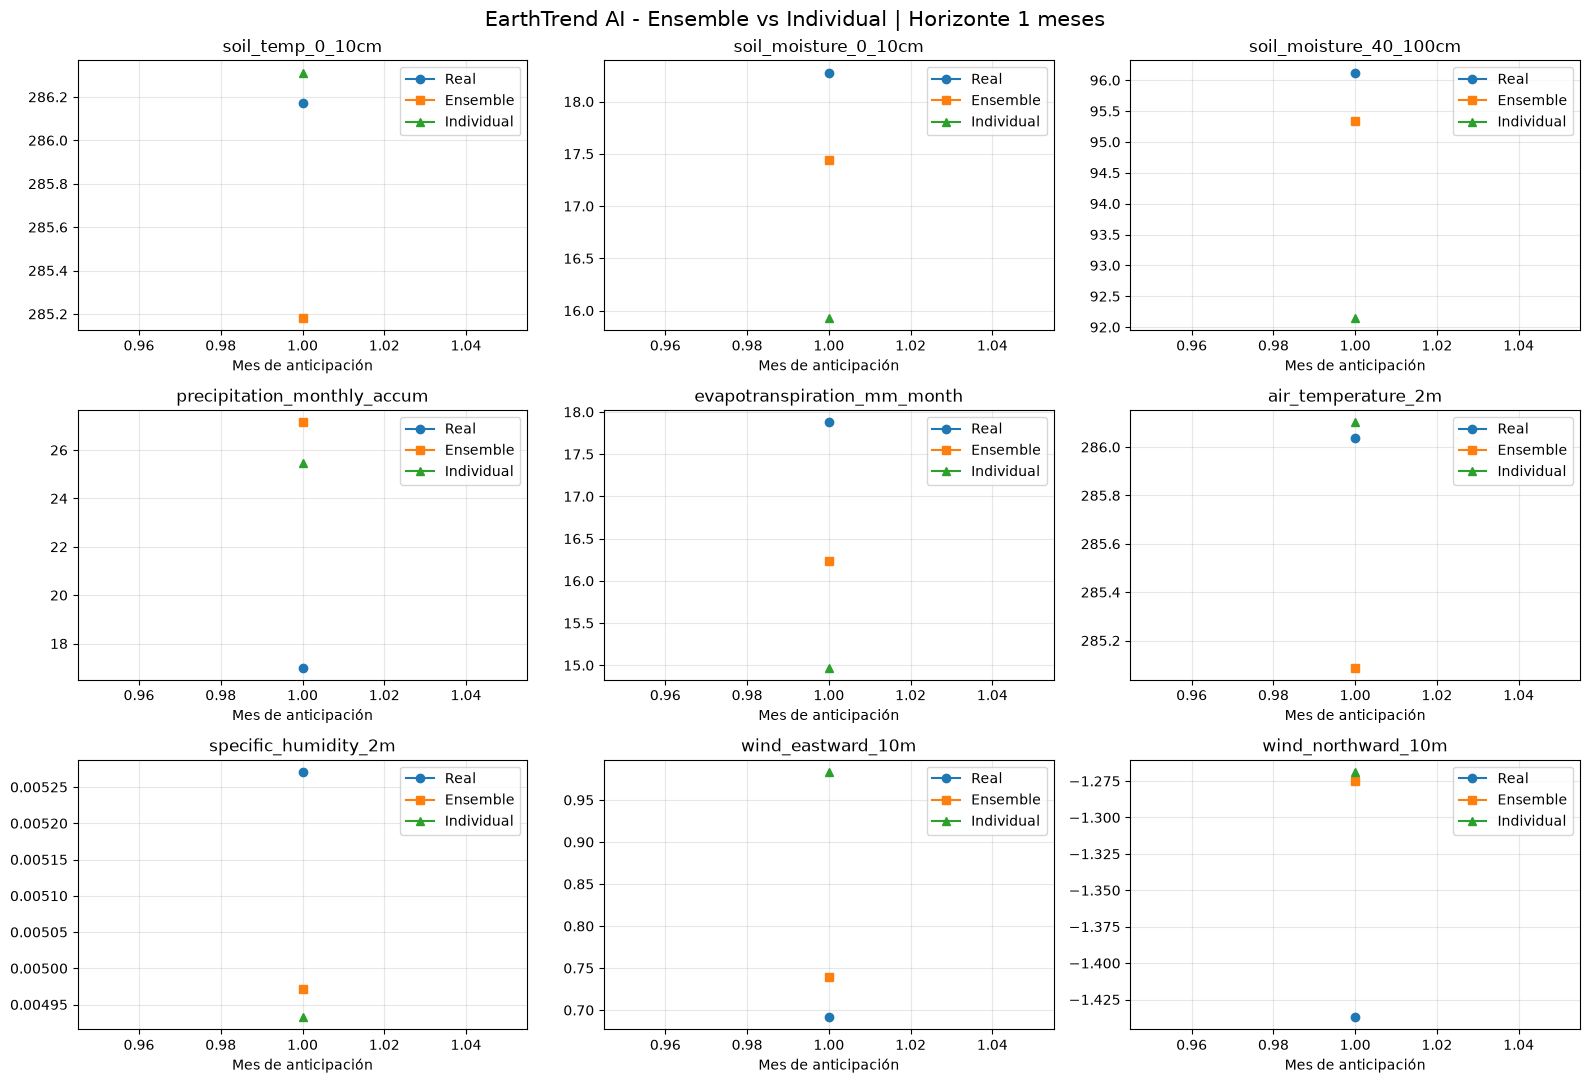

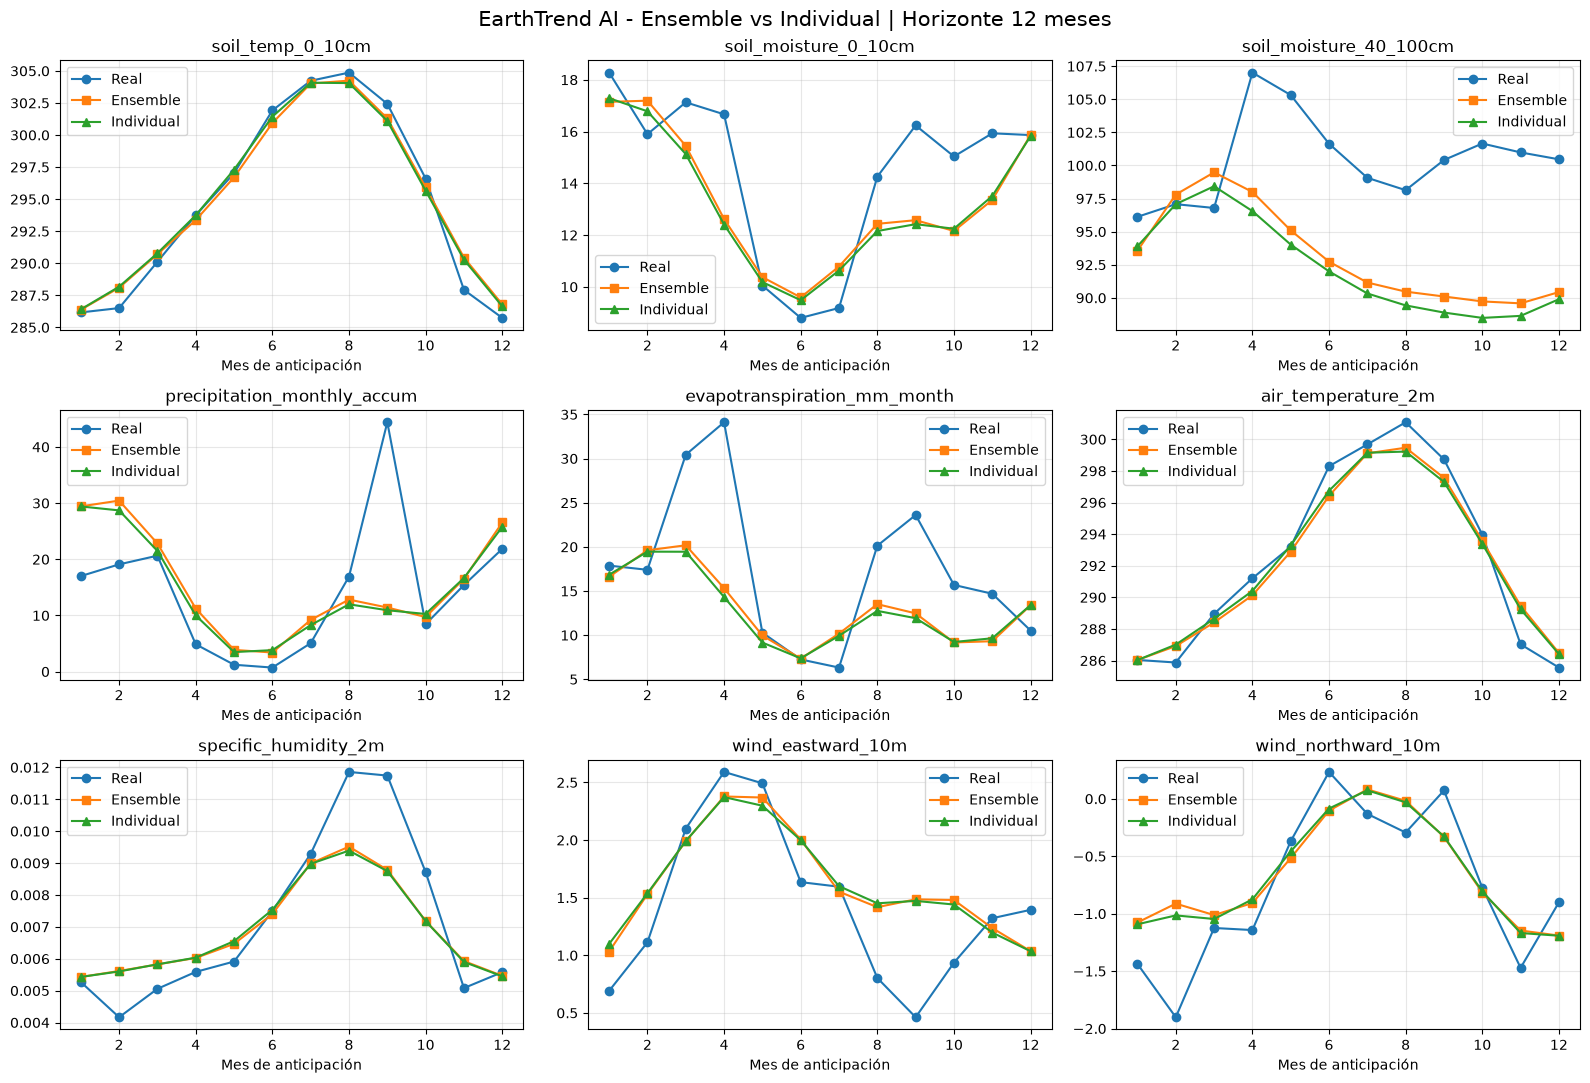

In [53]:

# ============================================================
# PASO 4: COMPARACIÓN ENSEMBLE VS MODELO INDIVIDUAL
# ============================================================

import matplotlib.pyplot as plt

for horizon in [1, 12]:

    real_scaled = final_datasets[horizon]["test"]["Y"].numpy()

    n, h, f = real_scaled.shape

    real_original = final_scaler.inverse_transform(
        real_scaled.reshape(-1, f)
    ).reshape(n, h, f)

    ensemble = ensemble_predictions[horizon]
    individual = individual_predictions[horizon]

    fig, axes = plt.subplots(
        3, 3,
        figsize=(16, 11)
    )

    for j, ax in enumerate(axes.flat):

        # Mostrar la primera muestra de test
        ax.plot(
            range(1, horizon + 1),
            real_original[0, :, j],
            marker="o",
            label="Real"
        )

        ax.plot(
            range(1, horizon + 1),
            ensemble[0, :, j],
            marker="s",
            label="Ensemble"
        )

        ax.plot(
            range(1, horizon + 1),
            individual[0, :, j],
            marker="^",
            label="Individual"
        )

        ax.set_title(FEATURES[j])
        ax.set_xlabel("Mes de anticipación")
        ax.grid(alpha=0.3)
        ax.legend()

    plt.suptitle(
        f"EarthTrend AI - Ensemble vs Individual | "
        f"Horizonte {horizon} meses",
        fontsize=15
    )

    plt.tight_layout()
    plt.show()


In [54]:
print("MODELOS DISPONIBLES:")
print(type(trained_models))
print(trained_models.keys())

print("\nOBJETOS RELACIONADOS CON ENSEMBLE:")
for name in globals():
    if any(word in name.lower() for word in ["ensemble", "final_model", "best_model"]):
        print(name, type(globals()[name]))

print("\nESCALADOR:")
print(type(final_scaler))

print("\nDATASETS:")
for h in [1, 12]:
    print(f"\nHorizonte {h}")
    print("X test:", final_datasets[h]["test"]["X"].shape)
    print("Y test:", final_datasets[h]["test"]["Y"].shape)
    print("Fechas:", len(final_datasets[h]["test"]["dates"]))

MODELOS DISPONIBLES:
<class 'dict'>
dict_keys([1, 12])

OBJETOS RELACIONADOS CON ENSEMBLE:
ensemble_predictions <class 'dict'>
ensemble_scaled <class 'numpy.ndarray'>
ensemble_original <class 'numpy.ndarray'>
ensemble <class 'numpy.ndarray'>

ESCALADOR:
<class 'sklearn.preprocessing._data.StandardScaler'>

DATASETS:

Horizonte 1
X test: torch.Size([45, 9, 36])
Y test: torch.Size([45, 1, 9])
Fechas: 45

Horizonte 12
X test: torch.Size([34, 9, 24])
Y test: torch.Size([34, 12, 9])
Fechas: 34


In [55]:
# ============================================
# EARTH TREND AI - INSPECCIÓN DEL ENSEMBLE
# ============================================

for name in ["ensemble_predictions", "ensemble_scaled",
             "ensemble_original", "ensemble"]:

    obj = globals()[name]

    print("\n" + "=" * 55)
    print(name)
    print("=" * 55)

    if isinstance(obj, dict):

        for key, value in obj.items():

            print(f"\nHorizonte: {key}")

            if hasattr(value, "shape"):
                print("Shape:", value.shape)
            else:
                print("Tipo:", type(value))

    elif hasattr(obj, "shape"):

        print("Shape:", obj.shape)

    else:
        print("Tipo:", type(obj))


print("\n" + "=" * 55)
print("FECHAS Y VALORES REALES")
print("=" * 55)

for h in [1, 12]:

    test = final_datasets[h]["test"]

    print(f"\nHorizonte {h}")

    print("Fechas iniciales:", test["dates"][:3])
    print("Fechas finales:", test["dates"][-3:])

    print("Y:", test["Y"].shape)
    print("X:", test["X"].shape)

print("\nVariables:")
print(FEATURES)


ensemble_predictions

Horizonte: 1
Shape: (45, 1, 9)

Horizonte: 12
Shape: (34, 12, 9)

ensemble_scaled
Shape: (34, 12, 9)

ensemble_original
Shape: (34, 12, 9)

ensemble
Shape: (34, 12, 9)

FECHAS Y VALORES REALES

Horizonte 1
Fechas iniciales: [DatetimeIndex(['2022-01-01'], dtype='datetime64[us]', freq=None), DatetimeIndex(['2022-02-01'], dtype='datetime64[us]', freq=None), DatetimeIndex(['2022-03-01'], dtype='datetime64[us]', freq=None)]
Fechas finales: [DatetimeIndex(['2025-07-01'], dtype='datetime64[us]', freq=None), DatetimeIndex(['2025-08-01'], dtype='datetime64[us]', freq=None), DatetimeIndex(['2025-09-01'], dtype='datetime64[us]', freq=None)]
Y: torch.Size([45, 1, 9])
X: torch.Size([45, 9, 36])

Horizonte 12
Fechas iniciales: [DatetimeIndex(['2022-01-01', '2022-02-01', '2022-03-01', '2022-04-01',
               '2022-05-01', '2022-06-01', '2022-07-01', '2022-08-01',
               '2022-09-01', '2022-10-01', '2022-11-01', '2022-12-01'],
              dtype='datetime64[us]', f

Variables: ['soil_temp_0_10cm', 'soil_moisture_0_10cm', 'soil_moisture_40_100cm', 'precipitation_monthly_accum', 'evapotranspiration_mm_month', 'air_temperature_2m', 'specific_humidity_2m', 'wind_eastward_10m', 'wind_northward_10m']
Número de variables: 9

EVALUACIÓN FINAL - HORIZONTE 1 MES
Y real: (45, 1, 9)
Predicción: (45, 1, 9)


,Variable,MAE,RMSE,R2
0,soil_temp_0_10cm,2087.06445,2087.38820,-86368.98438
1,soil_moisture_0_10cm,42.94379,43.21960,-159.66460
2,soil_moisture_40_100cm,953.12219,954.17379,-17283.71680
3,precipitation_monthly_accum,243.41141,277.30421,-476.66010
4,evapotranspiration_mm_month,86.17902,88.34634,-126.46469
5,air_temperature_2m,1603.71753,1603.85863,-80756.50000
6,specific_humidity_2m,0.00160,0.00197,-0.00270
7,wind_eastward_10m,0.89679,1.01960,-1.03786
8,wind_northward_10m,0.48169,0.55850,-0.04551



EVALUACIÓN FINAL - HORIZONTE 12 MESES
Y real: (34, 12, 9)
Predicción: (34, 12, 9)


,Variable,MAE,RMSE,R2
0,soil_temp_0_10cm,2086.70239,2087.05762,-85122.23438
1,soil_moisture_0_10cm,42.88033,43.16060,-149.87540
2,soil_moisture_40_100cm,926.75397,928.08189,-19104.21289
3,precipitation_monthly_accum,242.19371,273.81954,-413.43613
4,evapotranspiration_mm_month,83.06338,85.14516,-116.88937
5,air_temperature_2m,1603.98547,1604.13146,-79405.92188
6,specific_humidity_2m,0.00150,0.00186,-0.00204
7,wind_eastward_10m,0.87337,1.00183,-0.94381
8,wind_northward_10m,0.46984,0.54195,-0.11288


,Lead_month,Variable,MAE,RMSE,R2
0,1,soil_temp_0_10cm,2087.63403,2087.96157,-84492.32812
1,1,soil_moisture_0_10cm,42.97557,43.28387,-138.62611
2,1,soil_moisture_40_100cm,954.96814,956.68163,-21280.45508
3,1,precipitation_monthly_accum,247.02956,281.23914,-426.28732
4,1,evapotranspiration_mm_month,87.04620,89.80757,-112.83428
...,...,...,...,...,...
103,12,evapotranspiration_mm_month,84.71407,86.53989,-132.05408
104,12,air_temperature_2m,1603.69348,1603.84172,-79402.46094
105,12,specific_humidity_2m,0.00138,0.00169,0.00186
106,12,wind_eastward_10m,0.79129,0.89936,-0.74829



Fechas reconstruidas: 45
Fechas únicas: 45


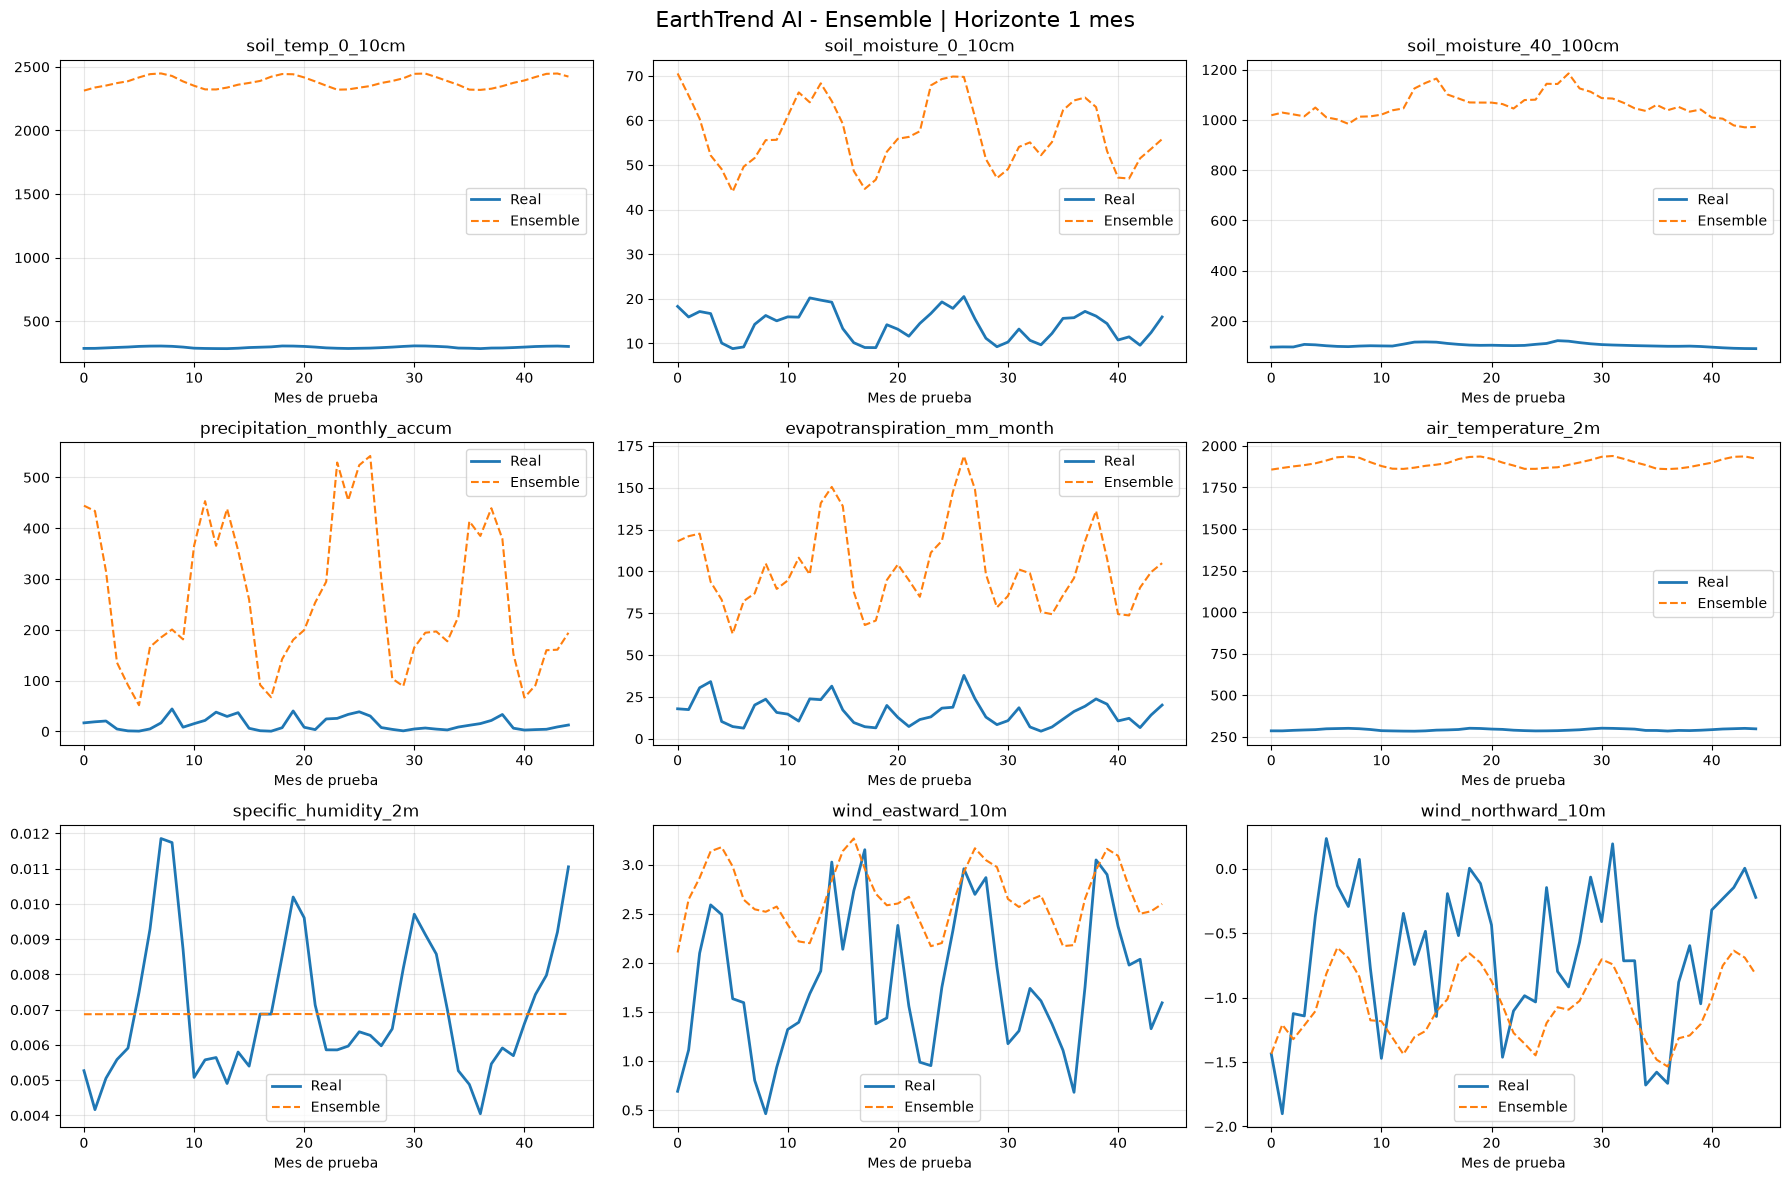

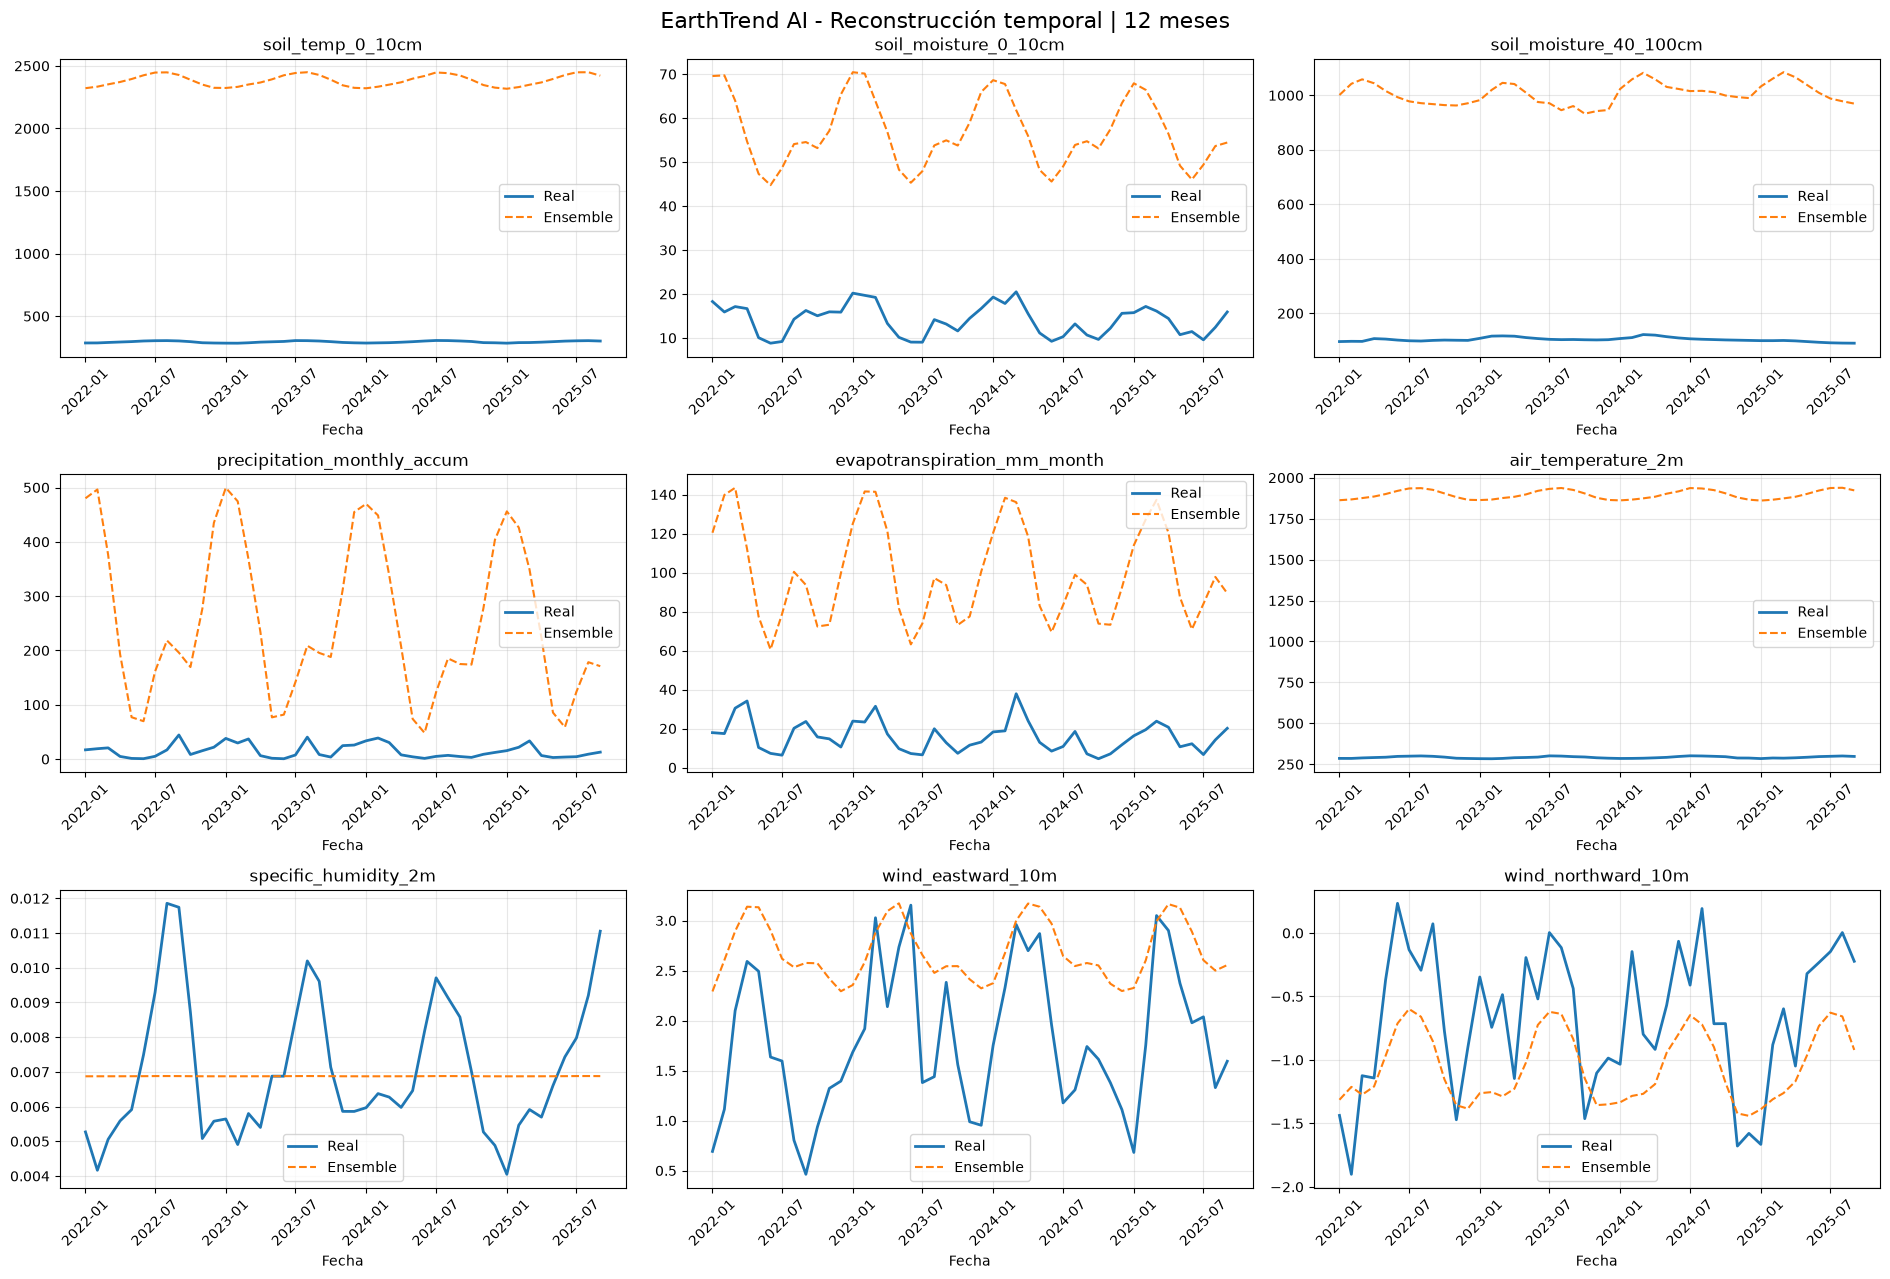

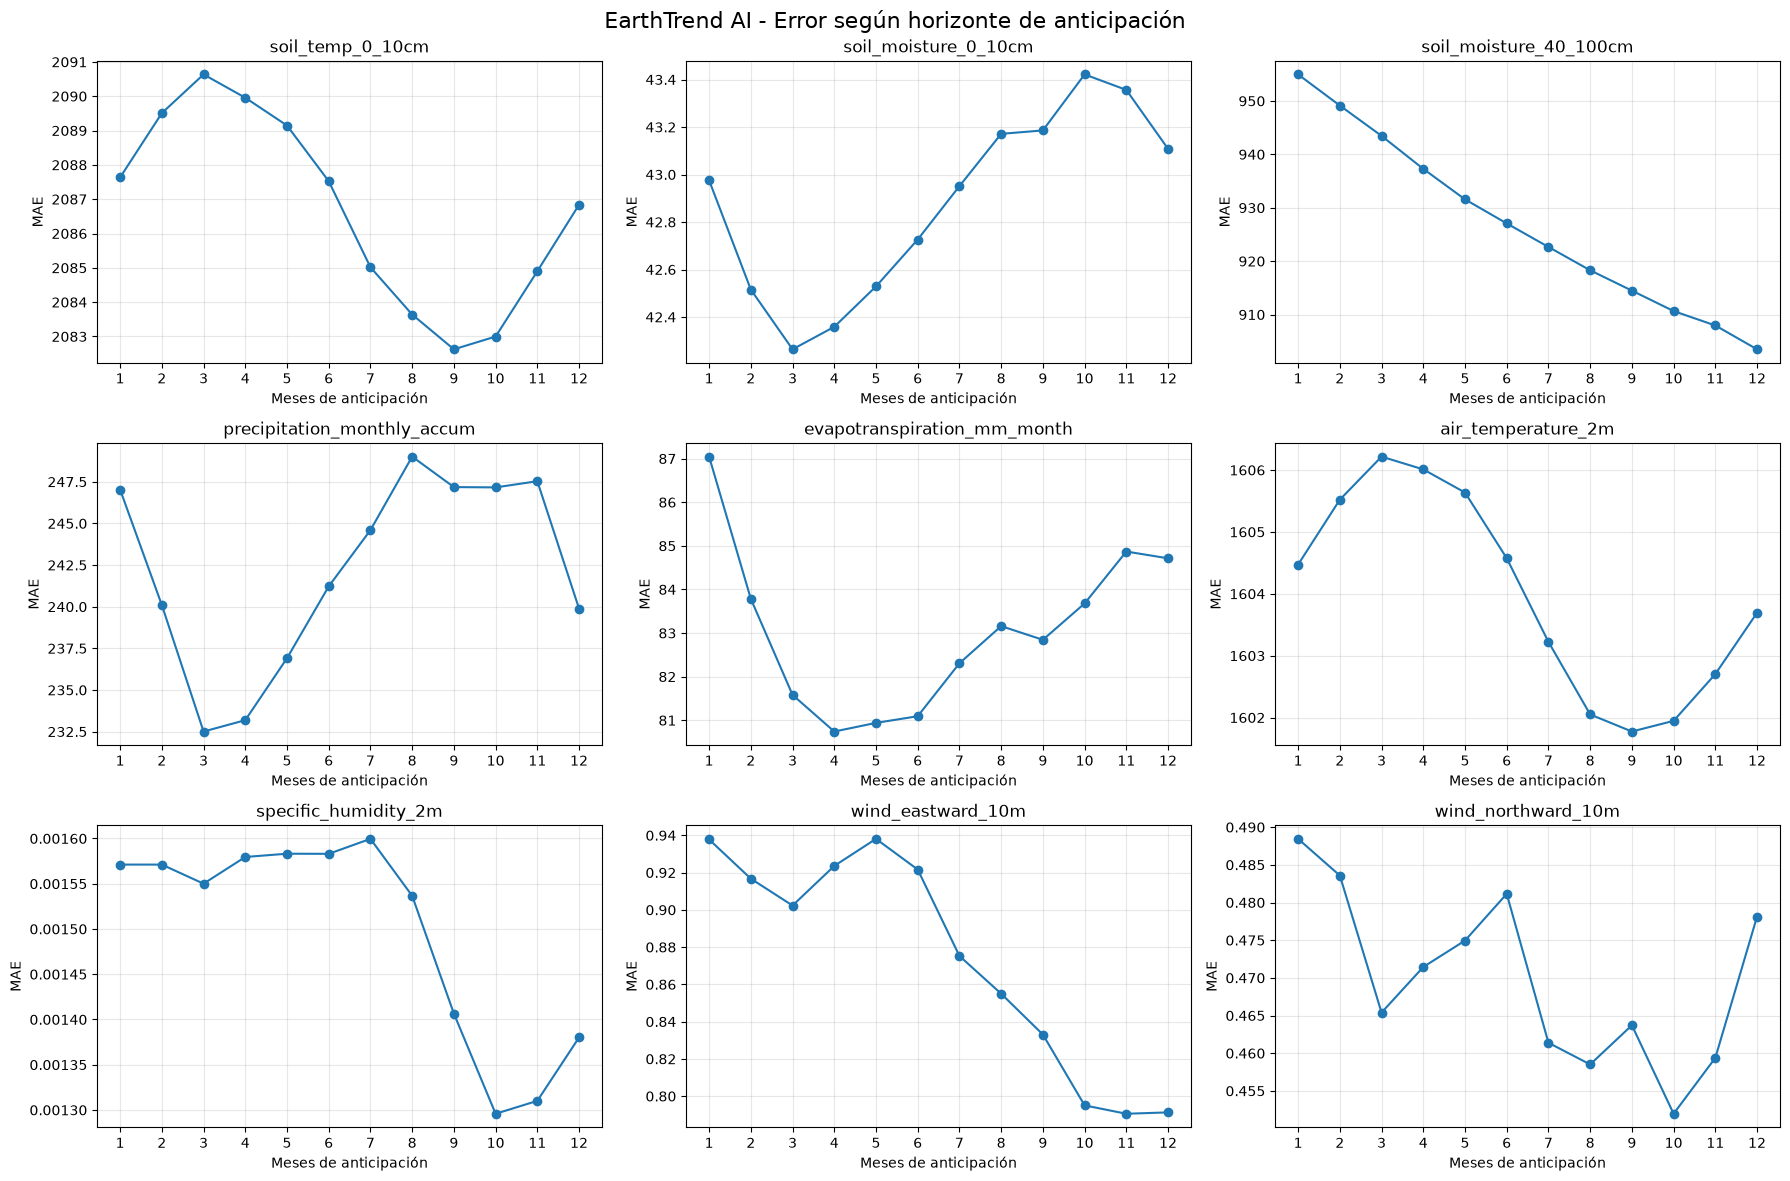


EVALUACIÓN FINAL COMPLETADA
Resultados guardados en: C:\Users\Roberto Garcés\PythonProjects\EarthTrend_AI_Final_Evaluation

Archivos:
- ensemble_horizon_1.png
- ensemble_horizon_12_temporal.png
- error_by_lead_month.png
- metrics_by_lead_month.csv
- metrics_horizon_1.csv
- metrics_horizon_12.csv
- temporal_reconstruction_horizon_12.csv


In [56]:

# ============================================================
# EARTH TREND AI
# EVALUACIÓN FINAL DEL ENSEMBLE
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from pathlib import Path

# ------------------------------------------------------------
# 1. CONFIGURACIÓN
# ------------------------------------------------------------

RESULTS_DIR = Path("EarthTrend_AI_Final_Evaluation")
RESULTS_DIR.mkdir(exist_ok=True)

N_FEATURES = len(FEATURES)

# Seleccionamos las predicciones originales ya calculadas.
# No volvemos a entrenar ni a calcular el ensemble.

predictions = {
    1: ensemble_original[1] if isinstance(ensemble_original, dict)
       else ensemble_original,
    12: ensemble_original[12] if isinstance(ensemble_original, dict)
        else ensemble_original
}

# Si ensemble_original no es un diccionario, se debe sustituir
# por el objeto que contiene las predicciones de ambos horizontes.
# La siguiente comprobación evita utilizar accidentalmente
# el mismo arreglo para ambos horizontes.

print("Variables:", FEATURES)
print("Número de variables:", N_FEATURES)

# ------------------------------------------------------------
# 2. FUNCIONES AUXILIARES
# ------------------------------------------------------------

def to_numpy(x):
    if hasattr(x, "detach"):
        return x.detach().cpu().numpy()
    return np.asarray(x)


def inverse_scale(array):
    """
    Convierte datos normalizados a unidades originales.
    Acepta arrays de dimensiones:
    (muestras, variables)
    (muestras, horizonte, variables)
    """

    array = to_numpy(array)

    original_shape = array.shape

    restored = final_scaler.inverse_transform(
        array.reshape(-1, N_FEATURES)
    )

    return restored.reshape(original_shape)


def calculate_metrics(y_true, y_pred):

    results = []

    for j, variable in enumerate(FEATURES):

        true_values = y_true[..., j].reshape(-1)
        pred_values = y_pred[..., j].reshape(-1)

        mae = mean_absolute_error(true_values, pred_values)

        rmse = np.sqrt(
            mean_squared_error(true_values, pred_values)
        )

        r2 = r2_score(true_values, pred_values)

        results.append({
            "Variable": variable,
            "MAE": mae,
            "RMSE": rmse,
            "R2": r2
        })

    return pd.DataFrame(results)


# ------------------------------------------------------------
# 3. EVALUACIÓN DEL HORIZONTE DE 1 MES
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("EVALUACIÓN FINAL - HORIZONTE 1 MES")
print("=" * 65)

y1_scaled = to_numpy(
    final_datasets[1]["test"]["Y"]
)

pred1_scaled = to_numpy(
    ensemble_predictions[1]
    if isinstance(ensemble_predictions, dict)
    else ensemble_predictions
)

print("Y real:", y1_scaled.shape)
print("Predicción:", pred1_scaled.shape)

# Ambas deben tener forma (45, 1, 9).
assert y1_scaled.shape == pred1_scaled.shape, (
    "Las dimensiones del horizonte 1 no coinciden."
)

y1_original = inverse_scale(y1_scaled)
pred1_original = inverse_scale(pred1_scaled)

metrics_1 = calculate_metrics(
    y1_original,
    pred1_original
)

display(metrics_1.round(5))

metrics_1.to_csv(
    RESULTS_DIR / "metrics_horizon_1.csv",
    index=False
)


# ------------------------------------------------------------
# 4. EVALUACIÓN DEL HORIZONTE DE 12 MESES
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("EVALUACIÓN FINAL - HORIZONTE 12 MESES")
print("=" * 65)

y12_scaled = to_numpy(
    final_datasets[12]["test"]["Y"]
)

pred12_scaled = to_numpy(
    ensemble_predictions[12]
    if isinstance(ensemble_predictions, dict)
    else ensemble_predictions
)

print("Y real:", y12_scaled.shape)
print("Predicción:", pred12_scaled.shape)

# Ambas deben tener forma (34, 12, 9).
assert y12_scaled.shape == pred12_scaled.shape, (
    "Las dimensiones del horizonte 12 no coinciden."
)

y12_original = inverse_scale(y12_scaled)
pred12_original = inverse_scale(pred12_scaled)

metrics_12 = calculate_metrics(
    y12_original,
    pred12_original
)

display(metrics_12.round(5))

metrics_12.to_csv(
    RESULTS_DIR / "metrics_horizon_12.csv",
    index=False
)


# ------------------------------------------------------------
# 5. ERROR SEGÚN EL MES DE ANTICIPACIÓN
# ------------------------------------------------------------

lead_results = []

for lead in range(12):

    y_true = y12_original[:, lead, :]
    y_pred = pred12_original[:, lead, :]

    for j, variable in enumerate(FEATURES):

        mae = mean_absolute_error(
            y_true[:, j],
            y_pred[:, j]
        )

        rmse = np.sqrt(
            mean_squared_error(
                y_true[:, j],
                y_pred[:, j]
            )
        )

        r2 = r2_score(
            y_true[:, j],
            y_pred[:, j]
        )

        lead_results.append({
            "Lead_month": lead + 1,
            "Variable": variable,
            "MAE": mae,
            "RMSE": rmse,
            "R2": r2
        })

lead_df = pd.DataFrame(lead_results)

display(lead_df.round(5))

lead_df.to_csv(
    RESULTS_DIR / "metrics_by_lead_month.csv",
    index=False
)


# ------------------------------------------------------------
# 6. RECONSTRUCCIÓN TEMPORAL SIN DUPLICAR FECHAS
# ------------------------------------------------------------

# Para cada fecha objetivo, utilizamos la primera predicción
# disponible. Así evitamos contar repetidamente los meses
# debido a las ventanas de 12 meses que se superponen.

dates_12 = final_datasets[12]["test"]["dates"]

records = []

for i in range(len(dates_12)):

    date_window = dates_12[i]

    # Cada ventana contiene 12 fechas objetivo.
    if isinstance(date_window, pd.DatetimeIndex):
        window_dates = date_window
    else:
        window_dates = pd.DatetimeIndex(date_window)

    for lead, date in enumerate(window_dates):

        records.append({
            "origin": i,
            "lead": lead + 1,
            "date": pd.Timestamp(date),
            "actual": y12_original[i, lead, :],
            "prediction": pred12_original[i, lead, :]
        })

# Ordenamos por fecha y origen.
reconstruction = pd.DataFrame(records)

# Primera predicción disponible para cada fecha.
first_forecast = (
    reconstruction
    .sort_values(["date", "origin"])
    .drop_duplicates(subset="date", keep="first")
    .sort_values("date")
    .reset_index(drop=True)
)

print("\nFechas reconstruidas:", len(first_forecast))
print("Fechas únicas:", first_forecast["date"].nunique())

# Convertimos los vectores a columnas individuales.
for j, variable in enumerate(FEATURES):

    first_forecast[f"{variable}_actual"] = (
        first_forecast["actual"].apply(lambda x: x[j])
    )

    first_forecast[f"{variable}_predicted"] = (
        first_forecast["prediction"].apply(lambda x: x[j])
    )

# ------------------------------------------------------------
# 7. GRÁFICAS: HORIZONTE 1 MES
# ------------------------------------------------------------

fig, axes = plt.subplots(
    3, 3,
    figsize=(18, 12)
)

for j, ax in enumerate(axes.flat):

    ax.plot(
        y1_original[:, 0, j],
        label="Real",
        linewidth=2
    )

    ax.plot(
        pred1_original[:, 0, j],
        label="Ensemble",
        linestyle="--"
    )

    ax.set_title(FEATURES[j])
    ax.set_xlabel("Mes de prueba")
    ax.grid(alpha=0.3)
    ax.legend()

fig.suptitle(
    "EarthTrend AI - Ensemble | Horizonte 1 mes",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "ensemble_horizon_1.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 8. GRÁFICAS: RECONSTRUCCIÓN TEMPORAL 12 MESES
# ------------------------------------------------------------

fig, axes = plt.subplots(
    3, 3,
    figsize=(19, 13)
)

for j, ax in enumerate(axes.flat):

    ax.plot(
        first_forecast["date"],
        first_forecast[f"{FEATURES[j]}_actual"],
        label="Real",
        linewidth=2
    )

    ax.plot(
        first_forecast["date"],
        first_forecast[f"{FEATURES[j]}_predicted"],
        label="Ensemble",
        linestyle="--"
    )

    ax.set_title(FEATURES[j])
    ax.set_xlabel("Fecha")
    ax.tick_params(axis="x", rotation=45)
    ax.grid(alpha=0.3)
    ax.legend()

fig.suptitle(
    "EarthTrend AI - Reconstrucción temporal | 12 meses",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "ensemble_horizon_12_temporal.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 9. GRÁFICAS DEL ERROR POR ANTICIPACIÓN
# ------------------------------------------------------------

fig, axes = plt.subplots(
    3, 3,
    figsize=(18, 12)
)

for j, ax in enumerate(axes.flat):

    variable_data = lead_df[
        lead_df["Variable"] == FEATURES[j]
    ]

    ax.plot(
        variable_data["Lead_month"],
        variable_data["MAE"],
        marker="o"
    )

    ax.set_title(FEATURES[j])
    ax.set_xlabel("Meses de anticipación")
    ax.set_ylabel("MAE")
    ax.set_xticks(range(1, 13))
    ax.grid(alpha=0.3)

fig.suptitle(
    "EarthTrend AI - Error según horizonte de anticipación",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "error_by_lead_month.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 10. EXPORTAR RECONSTRUCCIÓN Y RESUMEN
# ------------------------------------------------------------

first_forecast.to_csv(
    RESULTS_DIR / "temporal_reconstruction_horizon_12.csv",
    index=False
)

print("\n" + "=" * 65)
print("EVALUACIÓN FINAL COMPLETADA")
print("=" * 65)

print("Resultados guardados en:", RESULTS_DIR.resolve())

print("\nArchivos:")
for file in sorted(RESULTS_DIR.iterdir()):
    print("-", file.name)


In [57]:

# ============================================================
# EARTH TREND AI - DIAGNÓSTICO DE ESCALADO
# ============================================================

def inspect_array(name, obj):

    print("\n" + "=" * 55)
    print(name)
    print("=" * 55)

    if isinstance(obj, dict):

        for key, value in obj.items():

            arr = (
                value.detach().cpu().numpy()
                if hasattr(value, "detach")
                else np.asarray(value)
            )

            print(f"\nHorizonte: {key}")
            print("Shape:", arr.shape)
            print("Mínimo:", np.nanmin(arr))
            print("Máximo:", np.nanmax(arr))
            print("Media:", np.nanmean(arr))

    else:

        arr = (
            obj.detach().cpu().numpy()
            if hasattr(obj, "detach")
            else np.asarray(obj)
        )

        print("Shape:", arr.shape)
        print("Mínimo:", np.nanmin(arr))
        print("Máximo:", np.nanmax(arr))
        print("Media:", np.nanmean(arr))


inspect_array("Y REAL NORMALIZADO - H1", final_datasets[1]["test"]["Y"])
inspect_array("PREDICCIONES - ENSEMBLE PREDICTIONS", ensemble_predictions)
inspect_array("PREDICCIONES - ENSEMBLE ORIGINAL", ensemble_original)
inspect_array("PREDICCIONES - ENSEMBLE", ensemble)

print("\nMedias y desviaciones del scaler:")
print("Media:", final_scaler.mean_)
print("Desviación:", final_scaler.scale_)



Y REAL NORMALIZADO - H1
Shape: (45, 1, 9)
Mínimo: -2.0276554
Máximo: 3.838711
Media: 0.22014241

PREDICCIONES - ENSEMBLE PREDICTIONS

Horizonte: 1
Shape: (45, 1, 9)
Mínimo: -1.4348962
Máximo: 304.2569
Media: 81.08255

Horizonte: 12
Shape: (34, 12, 9)
Mínimo: -1.3787317
Máximo: 305.03668
Media: 80.728386

PREDICCIONES - ENSEMBLE ORIGINAL
Shape: (34, 12, 9)
Mínimo: -1.3787317
Máximo: 305.03668
Media: 80.728386

PREDICCIONES - ENSEMBLE
Shape: (34, 12, 9)
Mínimo: -1.3787317
Máximo: 305.03668
Media: 80.728386

Medias y desviaciones del scaler:
Media: [ 2.94769377e+02  1.32303754e+01  9.37718212e+01  1.60504330e+01
  1.30304003e+01  2.92229029e+02  6.86430508e-03  1.64046869e+00
 -6.48936533e-01]
Desviación: [7.07818483e+00 3.28587500e+00 9.69865920e+00 1.57772198e+01
 6.46278014e+00 5.48977766e+00 1.71244937e-03 6.29752354e-01
 6.17525023e-01]


In [59]:

# ============================================================
# DIAGNÓSTICO DETALLADO DEL ENSEMBLE
# ============================================================

import numpy as np
import pandas as pd

for h in [1, 12]:

    print("\n" + "=" * 75)
    print(f"HORIZONTE {h}")
    print("=" * 75)

    pred = ensemble_predictions[h]

    if hasattr(pred, "detach"):
        pred = pred.detach().cpu().numpy()

    pred = np.asarray(pred)

    real = final_datasets[h]["test"]["Y"]

    if hasattr(real, "detach"):
        real = real.detach().cpu().numpy()

    real = np.asarray(real)

    print("\nVARIABLE | REAL NORMALIZADO | PREDICCIÓN")

    for j, variable in enumerate(FEATURES):

        print(
            f"\n{variable}"
            f"\n  Real: min={real[..., j].min():.4f}, "
            f"max={real[..., j].max():.4f}, "
            f"mean={real[..., j].mean():.4f}"
            f"\n  Pred: min={pred[..., j].min():.4f}, "
            f"max={pred[..., j].max():.4f}, "
            f"mean={pred[..., j].mean():.4f}"
        )


print("\n" + "=" * 75)
print("VERIFICACIÓN DEL ESCALADOR")
print("=" * 75)

print("Número de variables:", len(FEATURES))
print("Número de medias:", len(final_scaler.mean_))
print("Número de desviaciones:", len(final_scaler.scale_))

print("\nMedias:")
print(final_scaler.mean_)

print("\nDesviaciones:")
print(final_scaler.scale_)



HORIZONTE 1

VARIABLE | REAL NORMALIZADO | PREDICCIÓN

soil_temp_0_10cm
  Real: min=-1.4715, max=1.5860, mean=0.0113
  Pred: min=285.1817, max=304.2569, mean=294.8700

soil_moisture_0_10cm
  Real: min=-1.3481, max=2.2082, mean=0.2514
  Pred: min=9.3728, max=17.4452, mean=13.3206

soil_moisture_40_100cm
  Real: min=-0.3695, max=2.8956, mean=1.0087
  Pred: min=90.3995, max=112.5036, mean=99.2823

precipitation_monthly_accum
  Real: min=-0.9781, max=1.7963, mean=-0.0792
  Pred: min=2.2620, max=33.3433, mean=15.3488

evapotranspiration_mm_month
  Real: min=-1.3201, max=3.8387, mean=0.4431
  Pred: min=7.6768, max=24.1236, mean=13.7778

air_temperature_2m
  Real: min=-1.5167, max=1.7505, mean=0.0423
  Pred: min=285.0883, max=300.0182, mean=292.1703

specific_humidity_2m
  Real: min=-1.6435, max=2.9155, mean=0.0877
  Pred: min=0.0047, max=0.0095, mean=0.0068

wind_eastward_10m
  Real: min=-1.8701, max=2.4027, mean=0.2562
  Pred: min=0.7396, max=2.5836, mean=1.6436

wind_northward_10m
  Real:

In [60]:

# ============================================================
# EARTH TREND AI - CORRECCIÓN DE ESCALAS DEL ENSEMBLE
# ============================================================

import numpy as np
import torch

ensemble_physical = {}
real_physical = {}

for h in [1, 12]:

    # Predicciones del ensemble: ya están en unidades físicas
    pred = ensemble_predictions[h]

    if torch.is_tensor(pred):
        pred = pred.detach().cpu().numpy()

    pred = np.asarray(pred)

    # Valores reales: todavía están normalizados
    real = final_datasets[h]["test"]["Y"]

    if torch.is_tensor(real):
        real = real.detach().cpu().numpy()

    real = np.asarray(real)

    # Desnormalizar exclusivamente los valores reales
    n, steps, features = real.shape

    real_original = final_scaler.inverse_transform(
        real.reshape(-1, features)
    ).reshape(n, steps, features)

    ensemble_physical[h] = pred
    real_physical[h] = real_original

    print(f"\nHORIZONTE {h}")

    for j, variable in enumerate(FEATURES):

        print(
            f"{variable}: "
            f"Real={real_original[..., j].mean():.3f} | "
            f"Predicción={pred[..., j].mean():.3f}"
        )

print("\nComparación corregida.")



HORIZONTE 1
soil_temp_0_10cm: Real=294.849 | Predicción=294.870
soil_moisture_0_10cm: Real=14.056 | Predicción=13.321
soil_moisture_40_100cm: Real=103.554 | Predicción=99.282
precipitation_monthly_accum: Real=14.801 | Predicción=15.349
evapotranspiration_mm_month: Real=15.894 | Predicción=13.778
air_temperature_2m: Real=292.461 | Predicción=292.170
specific_humidity_2m: Real=0.007 | Predicción=0.007
wind_eastward_10m: Real=1.802 | Predicción=1.644
wind_northward_10m: Real=-0.674 | Predicción=-0.677

HORIZONTE 12
soil_temp_0_10cm: Real=294.537 | Predicción=294.775
soil_moisture_0_10cm: Real=14.078 | Predicción=13.308
soil_moisture_40_100cm: Real=105.611 | Predicción=96.776
precipitation_monthly_accum: Real=15.748 | Predicción=15.332
evapotranspiration_mm_month: Real=15.507 | Predicción=13.236
air_temperature_2m: Real=292.220 | Predicción=292.175
specific_humidity_2m: Real=0.007 | Predicción=0.007
wind_eastward_10m: Real=1.825 | Predicción=1.638
wind_northward_10m: Real=-0.670 | Predicc

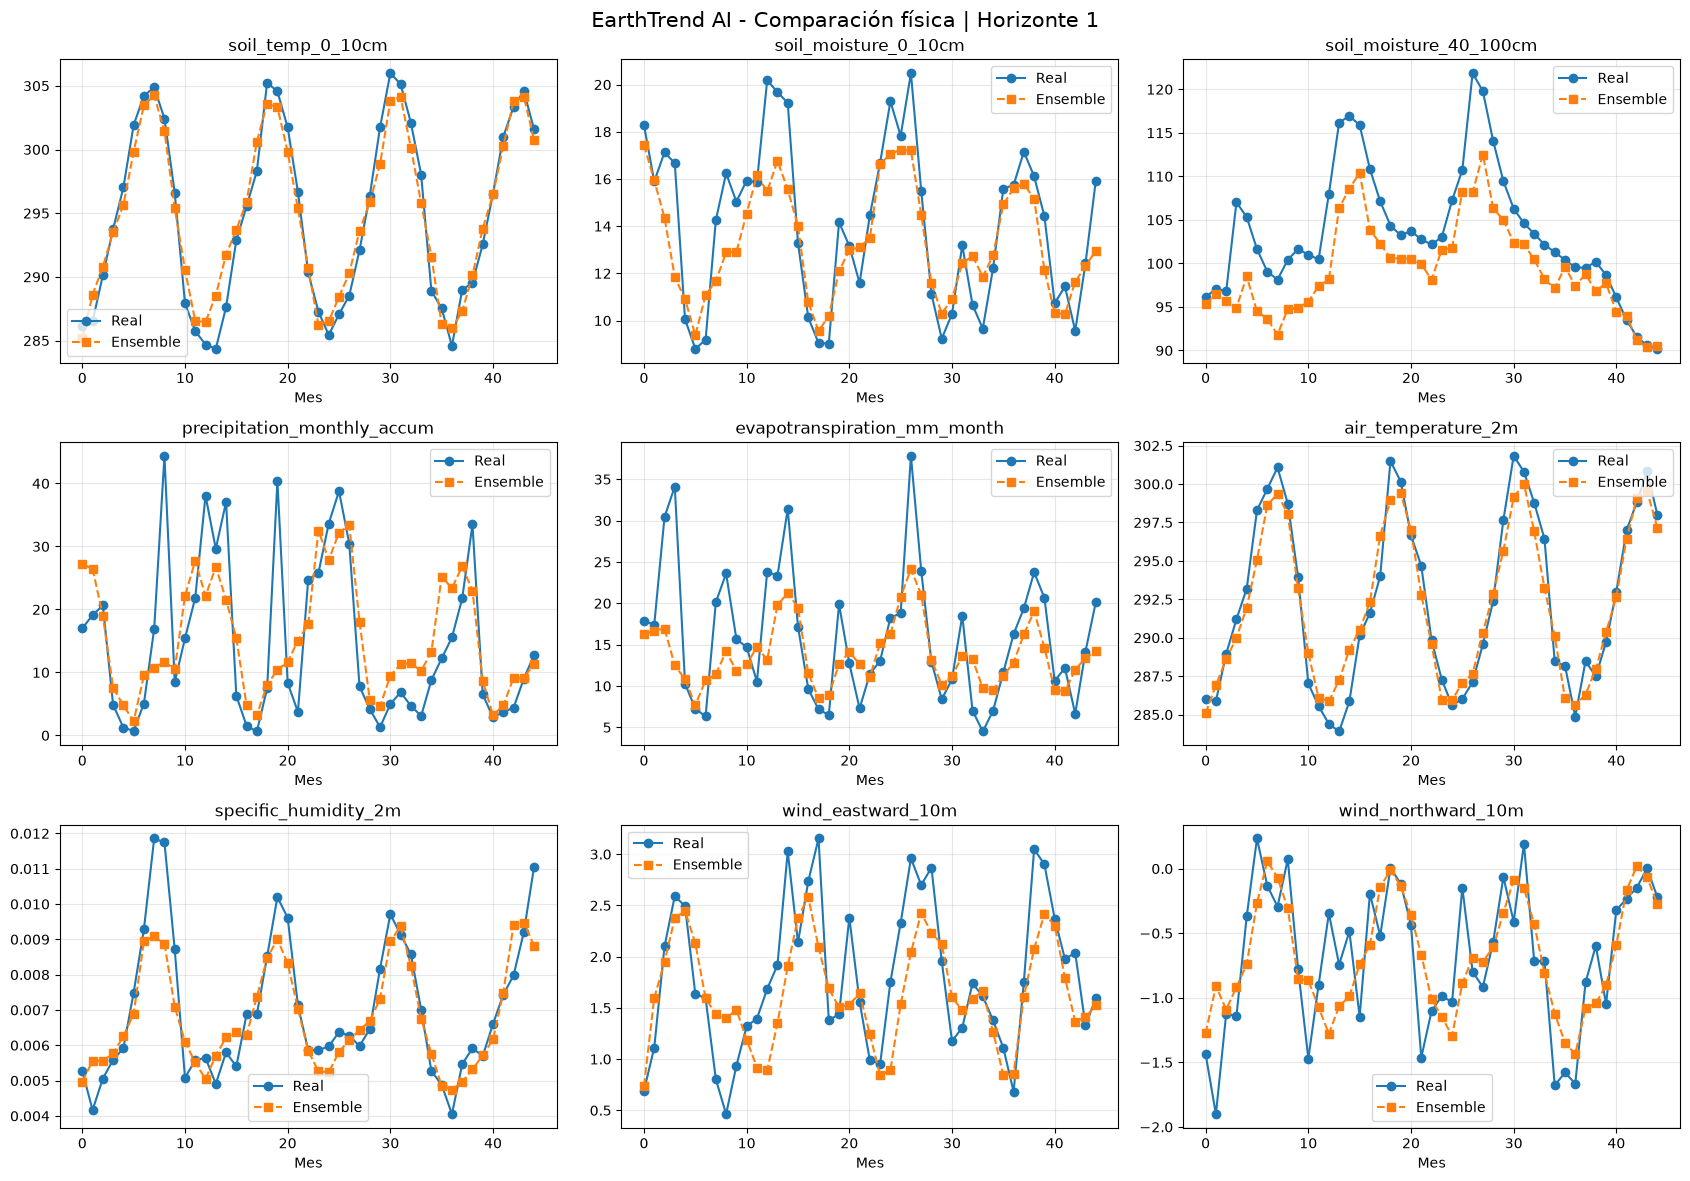

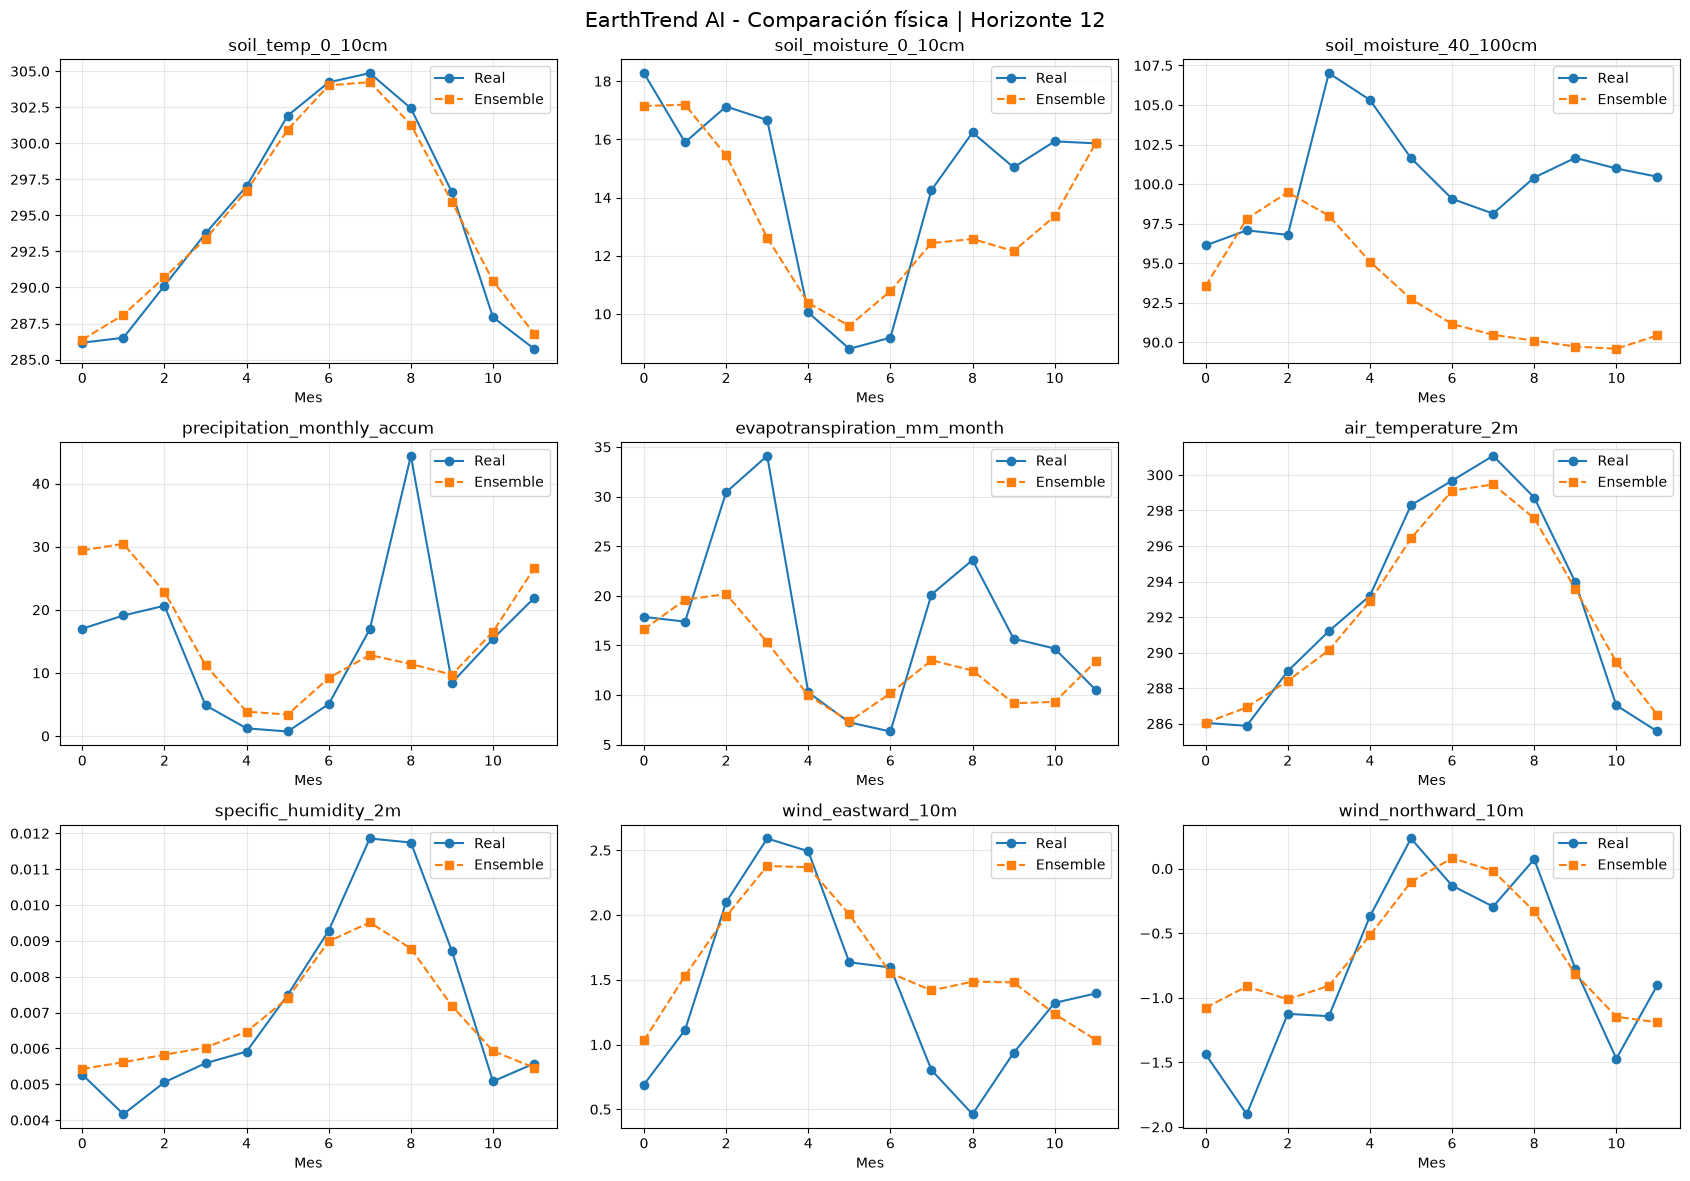

In [61]:

import matplotlib.pyplot as plt

for h in [1, 12]:

    real = real_physical[h]
    pred = ensemble_physical[h]

    # Para horizonte 12, mostramos la primera trayectoria
    if h == 1:
        real_plot = real[:, 0, :]
        pred_plot = pred[:, 0, :]
    else:
        real_plot = real[0, :, :]
        pred_plot = pred[0, :, :]

    fig, axes = plt.subplots(3, 3, figsize=(17, 12))

    for j, ax in enumerate(axes.flat):

        ax.plot(
            real_plot[:, j],
            marker="o",
            label="Real"
        )

        ax.plot(
            pred_plot[:, j],
            marker="s",
            linestyle="--",
            label="Ensemble"
        )

        ax.set_title(FEATURES[j])
        ax.set_xlabel("Mes")
        ax.grid(alpha=0.3)
        ax.legend()

    fig.suptitle(
        f"EarthTrend AI - Comparación física | Horizonte {h}",
        fontsize=15
    )

    plt.tight_layout()
    plt.show()


In [62]:

# ============================================================
# EARTH TREND AI - EVALUACION FINAL
# PASO 1: VERIFICACION DE ESTRUCTURAS
# ============================================================

import numpy as np
import torch
import pandas as pd

print("VARIABLES Y CONFIGURACION")
print("=" * 65)

print("FEATURES:", FEATURES)

for h in [1, 12]:

    print(f"\nHORIZONTE {h}")

    real = final_datasets[h]["test"]["Y"]
    pred = ensemble_predictions[h]

    if torch.is_tensor(real):
        real = real.detach().cpu().numpy()

    if torch.is_tensor(pred):
        pred = pred.detach().cpu().numpy()

    print("Real:", real.shape)
    print("Predicción:", pred.shape)

    print("Fechas disponibles:",
          len(final_datasets[h]["test"]["dates"]))

    print("Rango real normalizado:",
          np.nanmin(real), np.nanmax(real))

    print("Rango predicción:",
          np.nanmin(pred), np.nanmax(pred))

print("\nEscalador:")
print(type(final_scaler))
print("Medias:", final_scaler.mean_)
print("Desviaciones:", final_scaler.scale_)


VARIABLES Y CONFIGURACION
FEATURES: ['soil_temp_0_10cm', 'soil_moisture_0_10cm', 'soil_moisture_40_100cm', 'precipitation_monthly_accum', 'evapotranspiration_mm_month', 'air_temperature_2m', 'specific_humidity_2m', 'wind_eastward_10m', 'wind_northward_10m']

HORIZONTE 1
Real: (45, 1, 9)
Predicción: (45, 1, 9)
Fechas disponibles: 45
Rango real normalizado: -2.0276554 3.838711
Rango predicción: -1.4348962 304.2569

HORIZONTE 12
Real: (34, 12, 9)
Predicción: (34, 12, 9)
Fechas disponibles: 34
Rango real normalizado: -2.0276554 3.838711
Rango predicción: -1.3787317 305.03668

Escalador:
<class 'sklearn.preprocessing._data.StandardScaler'>
Medias: [ 2.94769377e+02  1.32303754e+01  9.37718212e+01  1.60504330e+01
  1.30304003e+01  2.92229029e+02  6.86430508e-03  1.64046869e+00
 -6.48936533e-01]
Desviaciones: [7.07818483e+00 3.28587500e+00 9.69865920e+00 1.57772198e+01
 6.46278014e+00 5.48977766e+00 1.71244937e-03 6.29752354e-01
 6.17525023e-01]


In [63]:

# ============================================================
# EARTH TREND AI - EVALUACION FISICA DEL ENSEMBLE
# PASO 2: METRICAS DEFINITIVAS
# ============================================================

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

evaluation_results = []

real_physical = {}
pred_physical = {}

for h in [1, 12]:

    # Valores reales normalizados
    y_real = final_datasets[h]["test"]["Y"]

    if torch.is_tensor(y_real):
        y_real = y_real.detach().cpu().numpy()

    y_real = np.asarray(y_real)

    # Predicciones del ensemble en unidades físicas
    y_pred = ensemble_predictions[h]

    if torch.is_tensor(y_pred):
        y_pred = y_pred.detach().cpu().numpy()

    y_pred = np.asarray(y_pred)

    n, steps, n_features = y_real.shape

    # Desnormalizar solamente los valores reales
    y_real = final_scaler.inverse_transform(
        y_real.reshape(-1, n_features)
    ).reshape(n, steps, n_features)

    real_physical[h] = y_real
    pred_physical[h] = y_pred

    # Comparación global de todas las muestras y meses
    for j, variable in enumerate(FEATURES):

        real_values = y_real[..., j].ravel()
        pred_values = y_pred[..., j].ravel()

        valid = (
            np.isfinite(real_values) &
            np.isfinite(pred_values)
        )

        real_values = real_values[valid]
        pred_values = pred_values[valid]

        mae = mean_absolute_error(real_values, pred_values)
        rmse = np.sqrt(mean_squared_error(real_values, pred_values))

        if len(real_values) > 1 and np.var(real_values) > 0:
            r2 = r2_score(real_values, pred_values)
        else:
            r2 = np.nan

        bias = np.mean(pred_values - real_values)

        evaluation_results.append({
            "Horizon": h,
            "Variable": variable,
            "N": len(real_values),
            "MAE": mae,
            "RMSE": rmse,
            "R2": r2,
            "Bias": bias
        })

evaluation_df = pd.DataFrame(evaluation_results)

print("EVALUACION FISICA DEL ENSEMBLE")
display(
    evaluation_df.round(5)
)

print("\nEvaluación terminada.")


EVALUACION FISICA DEL ENSEMBLE


,Horizon,Variable,N,MAE,RMSE,R2,Bias
0,1,soil_temp_0_10cm,45,1.40802,1.67644,0.94429,0.02091
1,1,soil_moisture_0_10cm,45,1.50335,1.92518,0.68121,-0.73578
2,1,soil_moisture_40_100cm,45,4.30903,5.36267,0.45403,-4.27216
3,1,precipitation_monthly_accum,45,6.60419,9.29446,0.46340,0.54799
4,1,evapotranspiration_mm_month,45,4.33953,6.08012,0.39628,-2.11625
5,1,air_temperature_2m,45,1.29922,1.58576,0.92106,-0.29095
6,1,specific_humidity_2m,45,0.00068,0.00094,0.76936,-0.00023
7,1,wind_eastward_10m,45,0.38781,0.50505,0.49998,-0.15814
8,1,wind_northward_10m,45,0.29192,0.37414,0.53081,-0.00350
9,12,soil_temp_0_10cm,408,1.22010,1.52182,0.95474,0.23814



Evaluación terminada.


In [65]:

# ============================================================
# EARTH TREND AI - INSPECCION DE DATASETS
# ============================================================

for h in [1, 12]:

    print("\n" + "=" * 60)
    print(f"HORIZONTE {h}")
    print("=" * 60)

    print("Claves principales:")
    print(final_datasets[h].keys())

    for key, value in final_datasets[h].items():

        print(f"\nClave: {key}")
        print("Tipo:", type(value))

        if isinstance(value, dict):

            print("Subclaves:", value.keys())

            if "dates" in value:
                print("Primeras fechas:", value["dates"][:3])
                print("Últimas fechas:", value["dates"][-3:])

        elif isinstance(value, (list, tuple)):
            print("Longitud:", len(value))

    print("\nFechas de prueba:")
    print(final_datasets[h]["test"]["dates"][:3])
    print(final_datasets[h]["test"]["dates"][-3:])



HORIZONTE 1
Claves principales:
dict_keys(['trainval', 'test'])

Clave: trainval
Tipo: <class 'dict'>
Subclaves: dict_keys(['X', 'Y'])

Clave: test
Tipo: <class 'dict'>
Subclaves: dict_keys(['X', 'Y', 'dates'])
Primeras fechas: [DatetimeIndex(['2022-01-01'], dtype='datetime64[us]', freq=None), DatetimeIndex(['2022-02-01'], dtype='datetime64[us]', freq=None), DatetimeIndex(['2022-03-01'], dtype='datetime64[us]', freq=None)]
Últimas fechas: [DatetimeIndex(['2025-07-01'], dtype='datetime64[us]', freq=None), DatetimeIndex(['2025-08-01'], dtype='datetime64[us]', freq=None), DatetimeIndex(['2025-09-01'], dtype='datetime64[us]', freq=None)]

Fechas de prueba:
[DatetimeIndex(['2022-01-01'], dtype='datetime64[us]', freq=None), DatetimeIndex(['2022-02-01'], dtype='datetime64[us]', freq=None), DatetimeIndex(['2022-03-01'], dtype='datetime64[us]', freq=None)]
[DatetimeIndex(['2025-07-01'], dtype='datetime64[us]', freq=None), DatetimeIndex(['2025-08-01'], dtype='datetime64[us]', freq=None), Dateti

In [66]:

import pandas as pd

print("DATAFRAMES DISPONIBLES")
print("=" * 65)

for name, obj in globals().copy().items():

    if isinstance(obj, pd.DataFrame):

        print(f"\nNombre: {name}")
        print("Shape:", obj.shape)
        print("Columnas:", list(obj.columns))

        if "date" in obj.columns:
            print("Primera fecha:", obj["date"].min())
            print("Última fecha:", obj["date"].max())

        elif isinstance(obj.index, pd.DatetimeIndex):
            print("Primera fecha:", obj.index.min())
            print("Última fecha:", obj.index.max())


DATAFRAMES DISPONIBLES

Nombre: df
Shape: (300, 10)
Columnas: ['date', 'soil_temp_0_10cm', 'soil_moisture_0_10cm', 'soil_moisture_40_100cm', 'precipitation_monthly_accum', 'air_temperature_2m', 'specific_humidity_2m', 'wind_eastward_10m', 'wind_northward_10m', 'evapotranspiration_mm_month']
Primera fecha: 2001-01-01 00:00:00
Última fecha: 2025-12-01 00:00:00

Nombre: metrics
Shape: (9, 4)
Columnas: ['Variable', 'MAE', 'RMSE', 'R2']

Nombre: summary_A_df
Shape: (6, 5)
Columnas: ['Lookback', 'Horizon', 'Best validation loss', 'Best epoch', 'Epochs trained']

Nombre: test_A_df
Shape: (54, 6)
Columnas: ['Lookback', 'Horizon', 'Variable', 'MAE', 'RMSE', 'R2']

Nombre: summary_B_df
Shape: (6, 6)
Columnas: ['Group', 'Horizon', 'Lookback', 'Input variables', 'Best validation loss', 'Best epoch']

Nombre: results_B_df
Shape: (54, 6)
Columnas: ['Group', 'Horizon', 'Variable', 'MAE', 'RMSE', 'R2']

Nombre: summary_C_df
Shape: (12, 7)
Columnas: ['Configuration', 'Horizon', 'Lookback', 'Filters', '

In [68]:
DATAFRAMES DISPONIBLES
=================================================================

Nombre: df
Shape: (300, 10)
Columnas: ['date', 'soil_temp_0_10cm', 'soil_moisture_0_10cm', 'soil_moisture_40_100cm', 'precipitation_monthly_accum', 'air_temperature_2m', 'specific_humidity_2m', 'wind_eastward_10m', 'wind_northward_10m', 'evapotranspiration_mm_month']
Primera fecha: 2001-01-01 00:00:00
Última fecha: 2025-12-01 00:00:00

Nombre: metrics
Shape: (9, 4)
Columnas: ['Variable', 'MAE', 'RMSE', 'R2']

Nombre: summary_A_df
Shape: (6, 5)
Columnas: ['Lookback', 'Horizon', 'Best validation loss', 'Best epoch', 'Epochs trained']

Nombre: test_A_df
Shape: (54, 6)
Columnas: ['Lookback', 'Horizon', 'Variable', 'MAE', 'RMSE', 'R2']

Nombre: summary_B_df
Shape: (6, 6)
Columnas: ['Group', 'Horizon', 'Lookback', 'Input variables', 'Best validation loss', 'Best epoch']

Nombre: results_B_df
Shape: (54, 6)
Columnas: ['Group', 'Horizon', 'Variable', 'MAE', 'RMSE', 'R2']

Nombre: summary_C_df
Shape: (12, 7)
Columnas: ['Configuration', 'Horizon', 'Lookback', 'Filters', 'Dropout', 'Kernel', 'Best validation loss']

Nombre: best_C
Shape: (2, 7)
Columnas: ['Horizon', 'Configuration', 'Lookback', 'Filters', 'Dropout', 'Kernel', 'Best validation loss']

Nombre: summary_D_df
Shape: (10, 6)
Columnas: ['Configuration', 'Horizon', 'Lookback', 'Seed', 'Best validation loss', 'Best epoch']

Nombre: stability_D
Shape: (2, 7)
Columnas: ['Configuration', 'Horizon', 'Mean', 'Std', 'Minimum', 'Maximum', 'CV_percent']

Nombre: subset
Shape: (5, 6)
Columnas: ['Configuration', 'Horizon', 'Lookback', 'Seed', 'Best validation loss', 'Best epoch']

Nombre: selected
Shape: (1, 6)
Columnas: ['Configuration', 'Horizon', 'Lookback', 'Seed', 'Best validation loss', 'Best epoch']

Nombre: final_training_summary
Shape: (10, 4)
Columnas: ['Horizon', 'Seed', 'Epochs', 'Final training loss']

Nombre: final_metrics_df
Shape: (36, 6)
Columnas: ['Horizon', 'Variable', 'Model', 'MAE', 'RMSE', 'R2']

Nombre: metrics_1
Shape: (9, 4)
Columnas: ['Variable', 'MAE', 'RMSE', 'R2']

Nombre: metrics_12
Shape: (9, 4)
Columnas: ['Variable', 'MAE', 'RMSE', 'R2']

Nombre: lead_df
Shape: (108, 5)
Columnas: ['Lead_month', 'Variable', 'MAE', 'RMSE', 'R2']

Nombre: reconstruction
Shape: (408, 5)
Columnas: ['origin', 'lead', 'date', 'actual', 'prediction']
Primera fecha: 2022-01-01 00:00:00
Última fecha: 2025-09-01 00:00:00

Nombre: first_forecast
Shape: (45, 23)
Columnas: ['origin', 'lead', 'date', 'actual', 'prediction', 'soil_temp_0_10cm_actual', 'soil_temp_0_10cm_predicted', 'soil_moisture_0_10cm_actual', 'soil_moisture_0_10cm_predicted', 'soil_moisture_40_100cm_actual', 'soil_moisture_40_100cm_predicted', 'precipitation_monthly_accum_actual', 'precipitation_monthly_accum_predicted', 'evapotranspiration_mm_month_actual', 'evapotranspiration_mm_month_predicted', 'air_temperature_2m_actual', 'air_temperature_2m_predicted', 'specific_humidity_2m_actual', 'specific_humidity_2m_predicted', 'wind_eastward_10m_actual', 'wind_eastward_10m_predicted', 'wind_northward_10m_actual', 'wind_northward_10m_predicted']
Primera fecha: 2022-01-01 00:00:00
Última fecha: 2025-09-01 00:00:00

Nombre: variable_data
Shape: (12, 5)
Columnas: ['Lead_month', 'Variable', 'MAE', 'RMSE', 'R2']

Nombre: evaluation_df
Shape: (18, 7)
Columnas: ['Horizon', 'Variable', 'N', 'MAE', 'RMSE', 'R2', 'Bias']

SyntaxError: leading zeros in decimal integer literals are not permitted; use an 0o prefix for octal integers (2484008930.py, line 7)

In [69]:

print("ENSEMBLE ORIGINAL")
print("Shape:", ensemble_original.shape)
print("Tipo:", type(ensemble_original))

print("\nESCALADOR")
print("Tipo:", type(final_scaler))

for h in [1, 12]:
    print(f"\nHORIZONTE {h}")
    print("Y test:", final_datasets[h]["test"]["Y"].shape)
    print("Fechas:", len(final_datasets[h]["test"]["dates"]))


ENSEMBLE ORIGINAL
Shape: (34, 12, 9)
Tipo: <class 'numpy.ndarray'>

ESCALADOR
Tipo: <class 'sklearn.preprocessing._data.StandardScaler'>

HORIZONTE 1
Y test: torch.Size([45, 1, 9])
Fechas: 45

HORIZONTE 12
Y test: torch.Size([34, 12, 9])
Fechas: 34


In [70]:

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

FEATURES = [
    'soil_temp_0_10cm',
    'soil_moisture_0_10cm',
    'soil_moisture_40_100cm',
    'precipitation_monthly_accum',
    'evapotranspiration_mm_month',
    'air_temperature_2m',
    'specific_humidity_2m',
    'wind_eastward_10m',
    'wind_northward_10m'
]

# ============================================================
# 1. DATOS Y CLIMATOLOGÍA
# ============================================================

df_eval = df.copy()
df_eval["date"] = pd.to_datetime(df_eval["date"])
df_eval = df_eval.sort_values("date").reset_index(drop=True)

train_df = df_eval[df_eval["date"] < "2022-01-01"].copy()

climatology = (
    train_df.assign(month=train_df["date"].dt.month)
    .groupby("month")[FEATURES]
    .mean()
)

# ============================================================
# 2. MÉTRICAS
# ============================================================

def get_metrics(y, pred):
    y = np.asarray(y, dtype=float).reshape(-1)
    pred = np.asarray(pred, dtype=float).reshape(-1)

    mask = np.isfinite(y) & np.isfinite(pred)
    y, pred = y[mask], pred[mask]

    return {
        "N": len(y),
        "MAE": mean_absolute_error(y, pred),
        "RMSE": np.sqrt(mean_squared_error(y, pred)),
        "R2": r2_score(y, pred),
        "Bias": np.mean(pred - y)
    }

# ============================================================
# 3. CONVERTIR PREDICCIONES TCN A UNIDADES FÍSICAS
# ============================================================

def inverse_predictions(arr):
    arr = np.asarray(arr)

    original_shape = arr.shape

    return final_scaler.inverse_transform(
        arr.reshape(-1, len(FEATURES))
    ).reshape(original_shape)


# ============================================================
# 4. EVALUACIÓN
# ============================================================

results = []

for horizon in [1, 12]:

    # Valores reales normalizados
    y_scaled = (
        final_datasets[horizon]["test"]["Y"]
        .detach().cpu().numpy()
    )

    # Predicciones del ensemble normalizadas
    if horizon == 1:
        pred_scaled = ensemble_predictions[1]
    else:
        pred_scaled = ensemble_original

    y_real = inverse_predictions(y_scaled)
    y_tcn = inverse_predictions(pred_scaled)

    dates = final_datasets[horizon]["test"]["dates"]

    print(f"\nEvaluando horizonte {horizon}")
    print("Real:", y_real.shape)
    print("TCN:", y_tcn.shape)

    for lead in range(horizon):

        for j, variable in enumerate(FEATURES):

            actual = y_real[:, lead, j]
            tcn = y_tcn[:, lead, j]

            climate = []
            persistence = []

            for i in range(len(dates)):

                # Fecha objetivo correspondiente a este lead
                date = pd.Timestamp(dates[i][lead])

                climate.append(
                    climatology.loc[date.month, variable]
                )

                # Último dato observado antes del origen
                origin = pd.Timestamp(dates[i][0])

                previous = df_eval.loc[
                    df_eval["date"] < origin, variable
                ]

                persistence.append(previous.iloc[-1])

            models = {
                "TCN Ensemble": tcn,
                "Climatology": climate,
                "Persistence": persistence
            }

            for model_name, prediction in models.items():

                metrics_result = get_metrics(
                    actual,
                    prediction
                )

                results.append({
                    "Horizon": horizon,
                    "Lead": lead + 1,
                    "Variable": variable,
                    "Model": model_name,
                    **metrics_result
                })

baseline_comparison = pd.DataFrame(results)

print("\nEvaluación completada.")
display(baseline_comparison.head(20))



Evaluando horizonte 1
Real: (45, 1, 9)
TCN: (45, 1, 9)

Evaluando horizonte 12
Real: (34, 12, 9)
TCN: (34, 12, 9)

Evaluación completada.


,Horizon,Lead,Variable,Model,N,MAE,RMSE,R2,Bias
0,1,1,soil_temp_0_10cm,TCN Ensemble,45,2087.064473,2087.388286,-86368.986013,2087.064473
1,1,1,soil_temp_0_10cm,Climatology,45,0.827435,1.125099,0.974908,0.190496
2,1,1,soil_temp_0_10cm,Persistence,45,3.226170,3.829562,0.709294,-0.336212
3,1,1,soil_moisture_0_10cm,TCN Ensemble,45,42.943786,43.219597,-159.664585,42.943786
4,1,1,soil_moisture_0_10cm,Climatology,45,1.443595,1.889004,0.693081,-0.869932
5,1,1,soil_moisture_0_10cm,Persistence,45,2.186761,2.731436,0.358287,0.046948
6,1,1,soil_moisture_40_100cm,TCN Ensemble,45,953.122196,954.173833,-17283.719697,953.122196
7,1,1,soil_moisture_40_100cm,Climatology,45,9.893381,11.524269,-1.521355,-9.521146
8,1,1,soil_moisture_40_100cm,Persistence,45,2.596160,3.684403,0.742284,-0.021143
9,1,1,precipitation_monthly_accum,TCN Ensemble,45,243.411445,277.304213,-476.660092,243.411445


In [71]:

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

FEATURES = [
    'soil_temp_0_10cm',
    'soil_moisture_0_10cm',
    'soil_moisture_40_100cm',
    'precipitation_monthly_accum',
    'evapotranspiration_mm_month',
    'air_temperature_2m',
    'specific_humidity_2m',
    'wind_eastward_10m',
    'wind_northward_10m'
]

# ============================================================
# 1. PREPARACIÓN
# ============================================================

df_eval = df.copy()
df_eval["date"] = pd.to_datetime(df_eval["date"])
df_eval = df_eval.sort_values("date").reset_index(drop=True)

train_df = df_eval[df_eval["date"] < "2022-01-01"].copy()

climatology = (
    train_df.assign(month=train_df["date"].dt.month)
    .groupby("month")[FEATURES]
    .mean()
)

def calculate_metrics(y, pred):

    y = np.asarray(y, dtype=float)
    pred = np.asarray(pred, dtype=float)

    mask = np.isfinite(y) & np.isfinite(pred)
    y, pred = y[mask], pred[mask]

    return {
        "N": len(y),
        "MAE": mean_absolute_error(y, pred),
        "RMSE": np.sqrt(mean_squared_error(y, pred)),
        "R2": r2_score(y, pred),
        "Bias": np.mean(pred - y)
    }

def inverse_real(arr):

    arr = np.asarray(arr)
    shape = arr.shape

    return final_scaler.inverse_transform(
        arr.reshape(-1, len(FEATURES))
    ).reshape(shape)


# ============================================================
# 2. EVALUACIÓN
# ============================================================

results = []

for horizon in [1, 12]:

    # Valores reales: siguen normalizados
    y_scaled = (
        final_datasets[horizon]["test"]["Y"]
        .detach().cpu().numpy()
    )

    y_real = inverse_real(y_scaled)

    dates = final_datasets[horizon]["test"]["dates"]

    # IMPORTANTE:
    # Estas predicciones YA están en unidades físicas.
    if horizon == 1:

        pred_physical = np.column_stack([
            first_forecast[f"{v}_predicted"].values
            for v in FEATURES
        ]).reshape(-1, 1, len(FEATURES))

    else:

        pred_physical = np.asarray(ensemble_original)

    print(f"\nHORIZONTE {horizon}")
    print("Real:", y_real.shape)
    print("Predicción física:", pred_physical.shape)

    # Verificación de dimensiones
    assert y_real.shape == pred_physical.shape

    for lead in range(horizon):

        for j, variable in enumerate(FEATURES):

            actual = y_real[:, lead, j]
            tcn = pred_physical[:, lead, j]

            climate = []
            persistence = []

            for i in range(len(dates)):

                target_date = pd.Timestamp(dates[i][lead])
                origin_date = pd.Timestamp(dates[i][0])

                climate.append(
                    climatology.loc[target_date.month, variable]
                )

                previous = df_eval.loc[
                    df_eval["date"] < origin_date,
                    variable
                ]

                persistence.append(previous.iloc[-1])

            models = {
                "TCN Ensemble": tcn,
                "Climatology": climate,
                "Persistence": persistence
            }

            for model_name, prediction in models.items():

                metric = calculate_metrics(actual, prediction)

                results.append({
                    "Horizon": horizon,
                    "Lead": lead + 1,
                    "Variable": variable,
                    "Model": model_name,
                    **metric
                })

baseline_comparison = pd.DataFrame(results)

print("\nEVALUACIÓN COMPLETADA")
display(baseline_comparison.head(30))



HORIZONTE 1
Real: (45, 1, 9)
Predicción física: (45, 1, 9)

HORIZONTE 12
Real: (34, 12, 9)
Predicción física: (34, 12, 9)

EVALUACIÓN COMPLETADA


,Horizon,Lead,Variable,Model,N,MAE,RMSE,R2,Bias
0,1,1,soil_temp_0_10cm,TCN Ensemble,45,2088.056552,2088.404315,-86453.087036,2088.056552
1,1,1,soil_temp_0_10cm,Climatology,45,0.827435,1.125099,0.974908,0.190496
2,1,1,soil_temp_0_10cm,Persistence,45,3.226170,3.829562,0.709294,-0.336212
3,1,1,soil_moisture_0_10cm,TCN Ensemble,45,42.797570,43.097580,-158.758690,42.797570
4,1,1,soil_moisture_0_10cm,Climatology,45,1.443595,1.889004,0.693081,-0.869932
5,1,1,soil_moisture_0_10cm,Persistence,45,2.186761,2.731436,0.358287,0.046948
6,1,1,soil_moisture_40_100cm,TCN Ensemble,45,902.528258,903.295750,-15489.565405,902.528258
7,1,1,soil_moisture_40_100cm,Climatology,45,9.893381,11.524269,-1.521355,-9.521146
8,1,1,soil_moisture_40_100cm,Persistence,45,2.596160,3.684403,0.742284,-0.021143
9,1,1,precipitation_monthly_accum,TCN Ensemble,45,238.151581,272.677839,-460.855066,238.151581


In [72]:

# Comparación del horizonte 1
display(
    baseline_comparison[
        baseline_comparison["Horizon"] == 1
    ].pivot(
        index="Variable",
        columns="Model",
        values="RMSE"
    ).round(4)
)

# Comparación del horizonte 12: promedio de métricas por lead
summary_baselines = (
    baseline_comparison[
        baseline_comparison["Horizon"] == 12
    ]
    .groupby(["Variable", "Model"])
    [["MAE", "RMSE", "R2"]]
    .mean()
    .reset_index()
)

display(summary_baselines.round(4))


Model,Climatology,Persistence,TCN Ensemble
Variable,,,
air_temperature_2m,1.2606,3.2404,1604.4336
evapotranspiration_mm_month,5.5889,8.2653,85.5729
precipitation_monthly_accum,9.3902,14.1249,272.6778
soil_moisture_0_10cm,1.8890,2.7314,43.0976
soil_moisture_40_100cm,11.5243,3.6844,903.2957
soil_temp_0_10cm,1.1251,3.8296,2088.4043
specific_humidity_2m,0.0008,0.0013,0.0020
wind_eastward_10m,0.4966,0.6609,1.0287
wind_northward_10m,0.3679,0.5604,0.5391


,Variable,Model,MAE,RMSE,R2
0,air_temperature_2m,Climatology,1.0483,1.3586,0.9427
1,air_temperature_2m,Persistence,6.6592,7.4984,-1.0480
2,air_temperature_2m,TCN Ensemble,1.2410,1.5234,0.9280
3,evapotranspiration_mm_month,Climatology,3.8580,5.3210,0.5379
4,evapotranspiration_mm_month,Persistence,8.9491,11.1384,-1.1080
5,evapotranspiration_mm_month,TCN Ensemble,4.0511,5.7502,0.4601
6,precipitation_monthly_accum,Climatology,6.5402,9.4950,0.4997
7,precipitation_monthly_accum,Persistence,15.4832,19.4174,-1.1319
8,precipitation_monthly_accum,TCN Ensemble,6.4175,9.2440,0.5254
9,soil_moisture_0_10cm,Climatology,1.4484,1.8832,0.7116


In [73]:

# ============================================================
# DIAGNÓSTICO DE PREDICCIONES HORIZONTE 1
# ============================================================

for variable in [
    "soil_temp_0_10cm",
    "soil_moisture_0_10cm",
    "air_temperature_2m",
    "precipitation_monthly_accum"
]:

    print("\n" + "=" * 65)
    print(variable)
    print("=" * 65)

    col_actual = f"{variable}_actual"
    col_pred = f"{variable}_predicted"

    diagnostic = first_forecast[
        ["date", col_actual, col_pred]
    ].copy()

    diagnostic["date"] = pd.to_datetime(diagnostic["date"])

    diagnostic = diagnostic.merge(
        df_eval[["date", variable]],
        on="date",
        how="left"
    )

    diagnostic.rename(
        columns={variable: "Original_df"},
        inplace=True
    )

    print("\nPrimeras cinco observaciones:")
    display(diagnostic.head().round(4))

    print("\nEstadísticas:")
    print(
        diagnostic[
            [col_actual, col_pred, "Original_df"]
        ].describe().round(4)
    )



soil_temp_0_10cm

Primeras cinco observaciones:


C:\Users\Roberto Garcés\AppData\Local\Temp\ipykernel_36884\2057139821.py:31: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  diagnostic.rename(
C:\Users\Roberto Garcés\AppData\Local\Temp\ipykernel_36884\2057139821.py:37: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(diagnostic.head().round(4))


,date,soil_temp_0_10cm_actual,soil_temp_0_10cm_predicted,Original_df
0,2022-01-01,286.170197,2321.801025,286.1703
1,2022-02-01,286.509308,2333.984375,286.5093
2,2022-03-01,290.119507,2352.424561,290.1195
3,2022-04-01,293.750214,2371.282471,293.7502
4,2022-05-01,297.019989,2394.898193,297.0201



Estadísticas:
       soil_temp_0_10cm_actual  soil_temp_0_10cm_predicted  Original_df
count                  45.0000                     45.0000      45.0000
mean                  294.8491                   2382.9053     294.8491
std                     7.1829                     45.6098       7.1829
min                   284.3538                   2317.2126     284.3538
25%                   287.9305                   2344.9265     287.9304
50%                   295.5435                   2389.3855     295.5435
75%                   301.7435                   2424.8867     301.7435
max                   305.9954                   2449.3394     305.9954

soil_moisture_0_10cm

Primeras cinco observaciones:


C:\Users\Roberto Garcés\AppData\Local\Temp\ipykernel_36884\2057139821.py:31: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  diagnostic.rename(
C:\Users\Roberto Garcés\AppData\Local\Temp\ipykernel_36884\2057139821.py:37: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(diagnostic.head().round(4))


,date,soil_moisture_0_10cm_actual,soil_moisture_0_10cm_predicted,Original_df
0,2022-01-01,18.277201,69.573303,18.2772
1,2022-02-01,15.898700,69.722397,15.8987
2,2022-03-01,17.129499,63.988800,17.1295
3,2022-04-01,16.665600,54.700802,16.6656
4,2022-05-01,10.051800,47.323700,10.0518


... (3 outputs left out)


Estadísticas:
       air_temperature_2m_actual  air_temperature_2m_predicted  Original_df
count                    45.0000                       45.0000      45.0000
mean                    292.4612                     1896.7513     292.4612
std                       5.7076                       27.2270       5.7076
min                     283.9029                     1860.2826     283.9029
25%                     287.2735                     1873.4813     287.2735
50%                     291.6083                     1897.7815     291.6083
75%                     297.9849                     1922.6156     297.9849
max                     301.8388                     1938.4153     301.8388

precipitation_monthly_accum

Primeras cinco observaciones:


C:\Users\Roberto Garcés\AppData\Local\Temp\ipykernel_36884\2057139821.py:31: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  diagnostic.rename(
C:\Users\Roberto Garcés\AppData\Local\Temp\ipykernel_36884\2057139821.py:37: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(diagnostic.head().round(4))


,date,precipitation_monthly_accum_actual,precipitation_monthly_accum_predicted,Original_df
0,2022-01-01,17.007099,480.152496,17.0071
1,2022-02-01,19.094900,496.373596,19.0949
2,2022-03-01,20.638901,376.005402,20.6389
3,2022-04-01,4.866100,193.311600,4.8661
4,2022-05-01,1.224400,77.074303,1.2244



Estadísticas:
       precipitation_monthly_accum_actual  \
count                             45.0000   
mean                              14.8008   
std                               12.8315   
min                                0.6194   
25%                                4.6943   
50%                                8.7878   
75%                               21.8523   
max                               44.3911   

       precipitation_monthly_accum_predicted  Original_df  
count                                45.0000      45.0000  
mean                                252.9524      14.8008  
std                                 142.9690      12.8315  
min                                  48.2142       0.6194  
25%                                 161.2672       4.6943  
50%                                 207.3993       8.7878  
75%                                 376.0053      21.8523  
max                                 499.5281      44.3911  


In [74]:

# ============================================================
# RASTREO DE PREDICCIONES HORIZONTE 1
# ============================================================

variables_check = [
    "soil_temp_0_10cm",
    "soil_moisture_0_10cm",
    "air_temperature_2m",
    "precipitation_monthly_accum"
]

print("FORMAS DE LOS ARREGLOS")
print("=" * 60)

for name in [
    "ensemble",
    "ensemble_scaled",
    "ensemble_original",
    "ensemble_predictions"
]:
    if name in globals():
        obj = globals()[name]
        print(name, type(obj), np.asarray(obj).shape)

print("\nESTADÍSTICAS DE LAS PREDICCIONES")
print("=" * 60)

for variable in variables_check:

    print(f"\n{variable}")

    for suffix in ["actual", "predicted"]:

        col = f"{variable}_{suffix}"

        values = first_forecast[col].to_numpy()

        print(
            col,
            "| min:", np.nanmin(values),
            "| max:", np.nanmax(values),
            "| mean:", np.nanmean(values)
        )

print("\nESTADÍSTICAS DE LOS DATOS ORIGINALES")
print("=" * 60)

for variable in variables_check:

    values = df_eval[variable].to_numpy()

    print(
        variable,
        "| min:", np.nanmin(values),
        "| max:", np.nanmax(values),
        "| mean:", np.nanmean(values)
    )


FORMAS DE LOS ARREGLOS
ensemble <class 'numpy.ndarray'> (34, 12, 9)
ensemble_scaled <class 'numpy.ndarray'> (34, 12, 9)
ensemble_original <class 'numpy.ndarray'> (34, 12, 9)
ensemble_predictions <class 'dict'> ()

ESTADÍSTICAS DE LAS PREDICCIONES

soil_temp_0_10cm
soil_temp_0_10cm_actual | min: 284.35376 | max: 305.99542 | mean: 294.84906
soil_temp_0_10cm_predicted | min: 2317.2126 | max: 2449.3394 | mean: 2382.9053

soil_moisture_0_10cm
soil_moisture_0_10cm_actual | min: 8.800765 | max: 20.486355 | mean: 14.056361
soil_moisture_0_10cm_predicted | min: 44.74952 | max: 70.44019 | mean: 56.853928

air_temperature_2m
air_temperature_2m_actual | min: 283.90292 | max: 301.8388 | mean: 292.46124
air_temperature_2m_predicted | min: 1860.2826 | max: 1938.4153 | mean: 1896.7513

precipitation_monthly_accum
precipitation_monthly_accum_actual | min: 0.6193857 | max: 44.391098 | mean: 14.800837
precipitation_monthly_accum_predicted | min: 48.214203 | max: 499.52814 | mean: 252.9524

ESTADÍSTICAS D

In [75]:

print("COMPARACIÓN DE ESCALAS")
print("=" * 60)

# Tomamos las predicciones normalizadas del horizonte 1
candidate = np.asarray(ensemble)

print("Ensemble:")
print("Shape:", candidate.shape)
print("Min:", candidate.min())
print("Max:", candidate.max())
print("Mean:", candidate.mean())

# Invertimos el escalador una sola vez
candidate_physical = final_scaler.inverse_transform(
    candidate.reshape(-1, len(FEATURES))
).reshape(candidate.shape)

print("\nEnsemble después de inverse_transform:")
print("Min:", candidate_physical.min())
print("Max:", candidate_physical.max())
print("Mean:", candidate_physical.mean())

print("\nPrimeros valores de temperatura:")
j = FEATURES.index("soil_temp_0_10cm")

print("Original:", df_eval["soil_temp_0_10cm"].iloc[-45:].head().values)
print("Predicción guardada:", first_forecast["soil_temp_0_10cm_predicted"].head().values)
print("Candidato:", candidate_physical[:5, 0, j])


COMPARACIÓN DE ESCALAS
Ensemble:
Shape: (34, 12, 9)
Min: -1.3787317
Max: 305.03668
Mean: 80.728386

Ensemble después de inverse_transform:
Min: -1.5003378
Max: 2453.8752
Mean: 636.09827

Primeros valores de temperatura:
Original: [293.750153 297.02005  301.918518 304.231171 304.867828]
Predicción guardada: [2321.801  2333.9844 2352.4246 2371.2825 2394.8982]
Candidato: [2321.801 2336.05  2351.562 2372.729 2389.601]


In [76]:
# ============================================================
# EARTH TREND AI - DIAGNÓSTICO DEL PIPELINE DE PREDICCIONES
# ============================================================

import numpy as np

print("=" * 65)
print("DIAGNÓSTICO DE ESCALAS")
print("=" * 65)

arrays = {
    "ensemble": ensemble,
    "ensemble_scaled": ensemble_scaled,
    "ensemble_original": ensemble_original,
}

for name, arr in arrays.items():
    arr = np.asarray(arr)

    print(f"\n{name}")
    print("Shape:", arr.shape)
    print("Min:", np.nanmin(arr))
    print("Max:", np.nanmax(arr))
    print("Mean:", np.nanmean(arr))
    print("Std:", np.nanstd(arr))

print("\n" + "=" * 65)
print("ESCALADOR")
print("=" * 65)

print("Mean:", final_scaler.mean_)
print("Scale:", final_scaler.scale_)

print("\n" + "=" * 65)
print("DATOS REALES")
print("=" * 65)

for h in [1, 12]:

    real = final_datasets[h]["test"]["Y"].cpu().numpy()

    print(f"\nHorizonte {h}")
    print("Shape:", real.shape)

    for j, feature in enumerate(FEATURES):
        values = real[:, :, j]

        print(
            f"{feature:35s} "
            f"min={values.min():.4f} "
            f"max={values.max():.4f} "
            f"mean={values.mean():.4f}"
        )

DIAGNÓSTICO DE ESCALAS

ensemble
Shape: (34, 12, 9)
Min: -1.3787317
Max: 305.03668
Mean: 80.728386
Std: 117.26109

ensemble_scaled
Shape: (34, 12, 9)
Min: -1.3489592
Max: 2.0006788
Mean: 0.021340298
Std: 0.7429716

ensemble_original
Shape: (34, 12, 9)
Min: -1.3787317
Max: 305.03668
Mean: 80.728386
Std: 117.26109

ESCALADOR
Mean: [ 2.94769377e+02  1.32303754e+01  9.37718212e+01  1.60504330e+01
  1.30304003e+01  2.92229029e+02  6.86430508e-03  1.64046869e+00
 -6.48936533e-01]
Scale: [7.07818483e+00 3.28587500e+00 9.69865920e+00 1.57772198e+01
 6.46278014e+00 5.48977766e+00 1.71244937e-03 6.29752354e-01
 6.17525023e-01]

DATOS REALES

Horizonte 1
Shape: (45, 1, 9)
soil_temp_0_10cm                    min=-1.4715 max=1.5860 mean=0.0113
soil_moisture_0_10cm                min=-1.3481 max=2.2082 mean=0.2514
soil_moisture_40_100cm              min=-0.3695 max=2.8956 mean=1.0087
precipitation_monthly_accum         min=-0.9781 max=1.7963 mean=-0.0792
evapotranspiration_mm_month         min=-1.32

In [77]:
# ============================================================
# EARTH TREND AI - CORRECCIÓN DE ESCALAS DEL ENSEMBLE
# ============================================================

import numpy as np
import pandas as pd

# Predicciones normalizadas
ensemble_scaled_corrected = np.asarray(
    ensemble_scaled,
    dtype=np.float64
)

# Verificar dimensiones
assert ensemble_scaled_corrected.shape == (34, 12, 9)
assert ensemble_scaled_corrected.shape[-1] == len(FEATURES)

# Inversión de escala: UNA SOLA VEZ
ensemble_physical_corrected = final_scaler.inverse_transform(
    ensemble_scaled_corrected.reshape(-1, len(FEATURES))
).reshape(ensemble_scaled_corrected.shape)

print("=" * 65)
print("ENSEMBLE CORREGIDO")
print("=" * 65)

for j, feature in enumerate(FEATURES):

    values = ensemble_physical_corrected[:, :, j]

    print(
        f"{feature:35s} "
        f"min={values.min():.4f} | "
        f"max={values.max():.4f} | "
        f"mean={values.mean():.4f}"
    )

# Guardar con un nombre nuevo para evitar confusiones
ensemble_physical = ensemble_physical_corrected.copy()

print("\nReconstrucción física terminada.")

ENSEMBLE CORREGIDO
soil_temp_0_10cm                    min=285.2212 | max=305.0367 | mean=294.7747
soil_moisture_0_10cm                min=9.0731 | max=18.1160 | mean=13.3078
soil_moisture_40_100cm              min=86.0116 | max=113.1757 | mean=96.7756
precipitation_monthly_accum         min=2.0386 | max=34.2381 | mean=15.3317
evapotranspiration_mm_month         min=6.0680 | max=23.6361 | mean=13.2358
air_temperature_2m                  min=285.2409 | max=300.4283 | mean=292.1751
specific_humidity_2m                min=0.0049 | max=0.0097 | mean=0.0068
wind_eastward_10m                   min=0.8925 | max=2.5174 | mean=1.6379
wind_northward_10m                  min=-1.3787 | max=0.1802 | mean=-0.6900

Reconstrucción física terminada.


In [78]:
# ============================================================
# COMPARACIÓN DE PREDICCIONES Y DATOS REALES
# ============================================================

real_12 = final_datasets[12]["test"]["Y"].cpu().numpy()

print("=" * 65)
print("VERIFICACIÓN DE PREDICCIONES FÍSICAS")
print("=" * 65)

for j, feature in enumerate(FEATURES):

    real = final_scaler.inverse_transform(
        real_12.reshape(-1, len(FEATURES))
    ).reshape(real_12.shape)[:, :, j]

    pred = ensemble_physical[:, :, j]

    print(f"\n{feature}")

    print(
        f"Real:       min={real.min():.4f}, "
        f"max={real.max():.4f}, "
        f"mean={real.mean():.4f}"
    )

    print(
        f"Predicción: min={pred.min():.4f}, "
        f"max={pred.max():.4f}, "
        f"mean={pred.mean():.4f}"
    )

VERIFICACIÓN DE PREDICCIONES FÍSICAS

soil_temp_0_10cm
Real:       min=284.3538, max=305.9954, mean=294.5365
Predicción: min=285.2212, max=305.0367, mean=294.7747

soil_moisture_0_10cm
Real:       min=8.8008, max=20.4864, mean=14.0779
Predicción: min=9.0731, max=18.1160, mean=13.3078

soil_moisture_40_100cm
Real:       min=90.1882, max=121.8554, mean=105.6115
Predicción: min=86.0116, max=113.1757, mean=96.7756

precipitation_monthly_accum
Real:       min=0.6194, max=44.3911, mean=15.7483
Predicción: min=2.0386, max=34.2381, mean=15.3317

evapotranspiration_mm_month
Real:       min=4.4988, max=37.8391, mean=15.5072
Predicción: min=6.0680, max=23.6361, mean=13.2358

air_temperature_2m
Real:       min=283.9029, max=301.8388, mean=292.2200
Predicción: min=285.2409, max=300.4283, mean=292.1751

specific_humidity_2m
Real:       min=0.0040, max=0.0119, mean=0.0070
Predicción: min=0.0049, max=0.0097, mean=0.0068

wind_eastward_10m
Real:       min=0.4628, max=3.1536, mean=1.8252
Predicción: min

In [79]:
# ============================================================
# EARTH TREND AI - LOCALIZAR PREDICCIONES DE AMBOS HORIZONTES
# ============================================================

import numpy as np

print("OBJETOS DE PREDICCIÓN DISPONIBLES")
print("=" * 65)

keywords = [
    "ensemble", "prediction", "forecast",
    "pred", "final_dataset", "final_model"
]

for name, obj in list(globals().items()):

    if any(k in name.lower() for k in keywords):

        if isinstance(obj, np.ndarray):
            print(
                f"{name:35s} "
                f"shape={obj.shape} "
                f"min={np.nanmin(obj):.4f} "
                f"max={np.nanmax(obj):.4f}"
            )

        elif isinstance(obj, dict):
            print(f"\n{name}: dict")

            for key, value in obj.items():

                if isinstance(value, np.ndarray):
                    print(f"  {key}: {value.shape}")

                elif isinstance(value, dict):
                    print(f"  {key}: dict")

                    for subkey, subvalue in value.items():
                        if hasattr(subvalue, "shape"):
                            print(
                                f"      {subkey}: "
                                f"{subvalue.shape}"
                            )

                else:
                    print(f"  {key}: {type(value)}")

OBJETOS DE PREDICCIÓN DISPONIBLES

predictions_original: dict
  1: dict
      real: (45, 1, 9)
      pred: (45, 1, 9)
  12: dict
      real: (34, 12, 9)
      pred: (34, 12, 9)
Y_pred                              shape=(34, 12, 9) min=-1.4709 max=1.7955
Y_pred_original                     shape=(34, 12, 9) min=-1.3800 max=305.7609
pred                                shape=(34, 12) min=-1.3787 max=0.1802
pred_tcn                            shape=(34, 12, 9) min=-1.3800 max=305.7609
y_pred                              shape=(34, 12, 9) min=-1.3787 max=305.0367
pred_original                       shape=(34, 12, 9) min=-1.3990 max=306.4224

final_datasets: dict
  1: dict
  12: dict

ensemble_predictions: dict
  1: (45, 1, 9)
  12: (34, 12, 9)

individual_predictions: dict
  1: (45, 1, 9)
  12: (34, 12, 9)

predictions_scaled: dict
  21: (34, 12, 9)
  42: (34, 12, 9)
  63: (34, 12, 9)
  84: (34, 12, 9)
  105: (34, 12, 9)
ensemble_scaled                     shape=(34, 12, 9) min=-1.3490 max=

In [80]:
# ============================================================
# EARTH TREND AI - VERIFICACIÓN DE PREDICCIONES DEFINITIVAS
# ============================================================

for h in [1, 12]:

    real = np.asarray(predictions_original[h]["real"])
    prediction = np.asarray(predictions_original[h]["pred"])

    print("\n" + "=" * 65)
    print(f"HORIZONTE {h}")
    print("=" * 65)

    print("Real:", real.shape)
    print("Predicción:", prediction.shape)

    for j, feature in enumerate(FEATURES):

        r = real[:, :, j]
        p = prediction[:, :, j]

        print(f"\n{feature}")
        print(
            f"Real: min={r.min():.4f}, "
            f"max={r.max():.4f}, mean={r.mean():.4f}"
        )
        print(
            f"Pred: min={p.min():.4f}, "
            f"max={p.max():.4f}, mean={p.mean():.4f}"
        )


HORIZONTE 1
Real: (45, 1, 9)
Predicción: (45, 1, 9)

soil_temp_0_10cm
Real: min=284.3538, max=305.9954, mean=294.8491
Pred: min=283.7657, max=306.0842, mean=294.7557

soil_moisture_0_10cm
Real: min=8.8008, max=20.4864, mean=14.0564
Pred: min=9.4383, max=18.3984, mean=13.6631

soil_moisture_40_100cm
Real: min=90.1882, max=121.8554, mean=103.5544
Pred: min=88.6175, max=114.0796, mean=97.7949

precipitation_monthly_accum
Real: min=0.6194, max=44.3911, mean=14.8008
Pred: min=2.3723, max=34.3871, mean=16.7725

evapotranspiration_mm_month
Real: min=4.4988, max=37.8391, mean=15.8940
Pred: min=7.4664, max=25.0242, mean=14.5197

air_temperature_2m
Real: min=283.9029, max=301.8388, mean=292.4612
Pred: min=284.5508, max=300.3307, mean=292.2801

specific_humidity_2m
Real: min=0.0040, max=0.0119, mean=0.0070
Pred: min=0.0049, max=0.0102, mean=0.0070

wind_eastward_10m
Real: min=0.4628, max=3.1536, mean=1.8018
Pred: min=0.8131, max=2.6547, mean=1.6012

wind_northward_10m
Real: min=-1.9011, max=0.23

In [81]:

# ============================================================
# EARTH TREND AI - EVALUACIÓN COMPARATIVA DEFINITIVA
# TCN vs CLIMATOLOGÍA vs PERSISTENCIA
# ============================================================

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

FEATURES = [
    'soil_temp_0_10cm',
    'soil_moisture_0_10cm',
    'soil_moisture_40_100cm',
    'precipitation_monthly_accum',
    'evapotranspiration_mm_month',
    'air_temperature_2m',
    'specific_humidity_2m',
    'wind_eastward_10m',
    'wind_northward_10m'
]

# ------------------------------------------------------------
# 1. DATOS HISTÓRICOS Y CLIMATOLOGÍA
# ------------------------------------------------------------

df_eval = df.copy()
df_eval["date"] = pd.to_datetime(df_eval["date"])
df_eval = df_eval.sort_values("date").reset_index(drop=True)

train_df = df_eval[
    df_eval["date"] < "2022-01-01"
].copy()

climatology = (
    train_df.assign(month=train_df["date"].dt.month)
    .groupby("month")[FEATURES]
    .mean()
)

# ------------------------------------------------------------
# 2. FUNCIÓN DE MÉTRICAS
# ------------------------------------------------------------

def evaluate_metrics(y, prediction):

    y = np.asarray(y, dtype=float).ravel()
    prediction = np.asarray(prediction, dtype=float).ravel()

    valid = np.isfinite(y) & np.isfinite(prediction)

    y = y[valid]
    prediction = prediction[valid]

    return {
        "N": len(y),
        "MAE": mean_absolute_error(y, prediction),
        "RMSE": np.sqrt(mean_squared_error(y, prediction)),
        "R2": r2_score(y, prediction),
        "Bias": np.mean(prediction - y)
    }


# ------------------------------------------------------------
# 3. EVALUAR AMBOS HORIZONTES
# ------------------------------------------------------------

results = []

for horizon in [1, 12]:

    real = np.asarray(
        predictions_original[horizon]["real"]
    )

    tcn = np.asarray(
        predictions_original[horizon]["pred"]
    )

    dates = final_datasets[horizon]["test"]["dates"]

    assert real.shape == tcn.shape

    print(f"\nEvaluando horizonte: {horizon} meses")
    print("Dimensiones:", real.shape)

    for lead in range(horizon):

        for j, variable in enumerate(FEATURES):

            actual = real[:, lead, j]
            tcn_pred = tcn[:, lead, j]

            climate_pred = []
            persistence_pred = []

            for i in range(len(dates)):

                target_date = pd.Timestamp(dates[i][lead])
                origin_date = pd.Timestamp(dates[i][0])

                # Baseline climatológico
                climate_pred.append(
                    climatology.loc[
                        target_date.month, variable
                    ]
                )

                # Última observación disponible en el origen
                previous = df_eval.loc[
                    df_eval["date"] < origin_date,
                    variable
                ]

                persistence_pred.append(previous.iloc[-1])

            models = {
                "TCN Ensemble": tcn_pred,
                "Climatology": climate_pred,
                "Persistence": persistence_pred
            }

            for model_name, prediction in models.items():

                metrics = evaluate_metrics(
                    actual,
                    prediction
                )

                results.append({
                    "Horizon": horizon,
                    "Lead": lead + 1,
                    "Variable": variable,
                    "Model": model_name,
                    **metrics
                })


baseline_comparison = pd.DataFrame(results)

print("\nEVALUACIÓN COMPLETADA")

display(
    baseline_comparison[
        baseline_comparison["Lead"] == 1
    ].round(5)
)

# Guardar
baseline_comparison.to_csv(
    "EarthTrend_AI_baseline_comparison.csv",
    index=False
)



Evaluando horizonte: 1 meses
Dimensiones: (45, 1, 9)

Evaluando horizonte: 12 meses
Dimensiones: (34, 12, 9)

EVALUACIÓN COMPLETADA


,Horizon,Lead,Variable,Model,N,MAE,RMSE,R2,Bias
0,1,1,soil_temp_0_10cm,TCN Ensemble,45,1.22462,1.77119,0.93781,-0.09338
1,1,1,soil_temp_0_10cm,Climatology,45,0.82744,1.12510,0.97491,0.19050
2,1,1,soil_temp_0_10cm,Persistence,45,3.22617,3.82956,0.70929,-0.33621
3,1,1,soil_moisture_0_10cm,TCN Ensemble,45,1.41972,1.80595,0.71948,-0.39330
4,1,1,soil_moisture_0_10cm,Climatology,45,1.44359,1.88900,0.69308,-0.86993
5,1,1,soil_moisture_0_10cm,Persistence,45,2.18676,2.73144,0.35829,0.04695
6,1,1,soil_moisture_40_100cm,TCN Ensemble,45,6.13172,7.28479,-0.00749,-5.75955
7,1,1,soil_moisture_40_100cm,Climatology,45,9.89338,11.52427,-1.52136,-9.52115
8,1,1,soil_moisture_40_100cm,Persistence,45,2.59616,3.68440,0.74228,-0.02114
9,1,1,precipitation_monthly_accum,TCN Ensemble,45,7.38532,9.55509,0.43288,1.97167


In [82]:

# ============================================================
# RESUMEN DE DESEMPEÑO
# ============================================================

for horizon in [1, 12]:

    print("\n" + "=" * 70)
    print(f"HORIZONTE {horizon} MESES")
    print("=" * 70)

    subset = baseline_comparison[
        baseline_comparison["Horizon"] == horizon
    ]

    summary = (
        subset.groupby(["Variable", "Model"])
        [["MAE", "RMSE", "R2", "Bias"]]
        .mean()
        .reset_index()
    )

    display(
        summary.round(5)
    )

    # Comparación del RMSE del TCN contra climatología
    pivot = summary.pivot(
        index="Variable",
        columns="Model",
        values="RMSE"
    )

    pivot["TCN_skill_vs_climatology"] = (
        1 - pivot["TCN Ensemble"] / pivot["Climatology"]
    )

    pivot["TCN_skill_vs_persistence"] = (
        1 - pivot["TCN Ensemble"] / pivot["Persistence"]
    )

    print("\nSkill score:")
    display(pivot.round(4))



HORIZONTE 1 MESES


,Variable,Model,MAE,RMSE,R2,Bias
0,air_temperature_2m,Climatology,0.96291,1.26063,0.95011,-0.05598
1,air_temperature_2m,Persistence,2.67118,3.24043,0.67035,-0.26102
2,air_temperature_2m,TCN Ensemble,1.26001,1.58725,0.92091,-0.18108
3,evapotranspiration_mm_month,Climatology,3.89504,5.58888,0.48989,-2.70129
4,evapotranspiration_mm_month,Persistence,6.34005,8.26533,-0.11566,-0.05448
5,evapotranspiration_mm_month,TCN Ensemble,3.99480,5.57886,0.49172,-1.37427
6,precipitation_monthly_accum,Climatology,6.48248,9.39017,0.45229,1.03735
7,precipitation_monthly_accum,Persistence,9.79774,14.12493,-0.23931,0.68317
8,precipitation_monthly_accum,TCN Ensemble,7.38532,9.55509,0.43288,1.97167
9,soil_moisture_0_10cm,Climatology,1.44359,1.88900,0.69308,-0.86993



Skill score:


Model,Climatology,Persistence,TCN Ensemble,TCN_skill_vs_climatology,TCN_skill_vs_persistence
Variable,,,,,
air_temperature_2m,1.2606,3.2404,1.5872,-0.2591,0.5102
evapotranspiration_mm_month,5.5889,8.2653,5.5789,0.0018,0.3250
precipitation_monthly_accum,9.3902,14.1249,9.5551,-0.0176,0.3235
soil_moisture_0_10cm,1.8890,2.7314,1.8059,0.0440,0.3388
soil_moisture_40_100cm,11.5243,3.6844,7.2848,0.3679,-0.9772
soil_temp_0_10cm,1.1251,3.8296,1.7712,-0.5743,0.5375
specific_humidity_2m,0.0008,0.0013,0.0009,-0.0090,0.3456
wind_eastward_10m,0.4966,0.6609,0.5013,-0.0094,0.2416
wind_northward_10m,0.3679,0.5604,0.3755,-0.0208,0.3299



HORIZONTE 12 MESES


,Variable,Model,MAE,RMSE,R2,Bias
0,air_temperature_2m,Climatology,1.04827,1.35858,0.94268,0.00904
1,air_temperature_2m,Persistence,6.65924,7.49838,-1.04801,0.00644
2,air_temperature_2m,TCN Ensemble,1.39829,1.70744,0.90940,-0.25935
3,evapotranspiration_mm_month,Climatology,3.85797,5.32095,0.53786,-2.47683
4,evapotranspiration_mm_month,Persistence,8.94915,11.13842,-1.10796,1.13712
5,evapotranspiration_mm_month,TCN Ensemble,4.24701,5.95629,0.42068,-2.31435
6,precipitation_monthly_accum,Climatology,6.54019,9.49496,0.49975,0.30218
7,precipitation_monthly_accum,Persistence,15.48316,19.41742,-1.13191,1.17597
8,precipitation_monthly_accum,TCN Ensemble,6.71051,9.34505,0.51496,0.16746
9,soil_moisture_0_10cm,Climatology,1.44843,1.88324,0.71158,-0.84754



Skill score:


Model,Climatology,Persistence,TCN Ensemble,TCN_skill_vs_climatology,TCN_skill_vs_persistence
Variable,,,,,
air_temperature_2m,1.3586,7.4984,1.7074,-0.2568,0.7723
evapotranspiration_mm_month,5.3210,11.1384,5.9563,-0.1194,0.4652
precipitation_monthly_accum,9.4950,19.4174,9.3450,0.0158,0.5187
soil_moisture_0_10cm,1.8832,4.8831,2.0161,-0.0705,0.5871
soil_moisture_40_100cm,12.9391,9.3389,11.6217,0.1018,-0.2444
soil_temp_0_10cm,1.2196,9.3088,1.6954,-0.3901,0.8179
specific_humidity_2m,0.0008,0.0026,0.0008,-0.0636,0.6802
wind_eastward_10m,0.5276,0.9988,0.5232,0.0083,0.4762
wind_northward_10m,0.3670,0.7386,0.3629,0.0110,0.5086


In [83]:
from pathlib import Path
import torch

# Carpeta de los checkpoints finales
CHECKPOINT_DIR = Path.home() / "Downloads" / (
    "EarthTrend_AI_audit_and_candidate_v1_0"
) / "EarthTrend_AI_Final_Ensemble"

print("=" * 65)
print("DIAGNÓSTICO DE RECUPERACIÓN — EARTHTREND AI")
print("=" * 65)

# 1. Comprobar objetos que podrían seguir en memoria
variables = [
    "ensemble_predictions",
    "individual_predictions",
    "models_final",
    "final_datasets",
    "final_scaler",
    "SEEDS_FINAL",
    "DEVICE",
    "TCN",
    "TemporalConvNet",
]

print("\n1. OBJETOS DISPONIBLES EN EL NOTEBOOK")
for name in variables:
    if name in globals():
        obj = globals()[name]
        print(f"  ✓ {name}: {type(obj).__name__}")
    else:
        print(f"  ✗ {name}: no encontrado")

# 2. Revisar los diez checkpoints
print("\n2. CHECKPOINTS DEL ENSAMBLE FINAL")

for horizon in [1, 12]:
    print(f"\nHorizonte: {horizon} meses")

    for seed in [21, 42, 63, 84, 105]:
        path = CHECKPOINT_DIR / f"TCN_h{horizon}_seed{seed}.pth"

        if path.exists():
            checkpoint = torch.load(
                path,
                map_location="cpu",
                weights_only=True
            )

            print(f"  ✓ seed {seed}: {path.stat().st_size / 1024:.1f} KB")
            print(f"      Tipo: {type(checkpoint).__name__}")

            if isinstance(checkpoint, dict):
                print(f"      Claves: {list(checkpoint.keys())[:8]}")
        else:
            print(f"  ✗ No encontrado: {path.name}")

print("\n" + "=" * 65)
print("DIAGNÓSTICO TERMINADO")
print("=" * 65)

DIAGNÓSTICO DE RECUPERACIÓN — EARTHTREND AI

1. OBJETOS DISPONIBLES EN EL NOTEBOOK
  ✓ ensemble_predictions: dict
  ✓ individual_predictions: dict
  ✓ models_final: dict
  ✓ final_datasets: dict
  ✓ final_scaler: StandardScaler
  ✓ SEEDS_FINAL: list
  ✓ DEVICE: device
  ✗ TCN: no encontrado
  ✗ TemporalConvNet: no encontrado

2. CHECKPOINTS DEL ENSAMBLE FINAL

Horizonte: 1 meses


UnpicklingError: Weights only load failed. This file can still be loaded, to do so you have two options, [1mdo those steps only if you trust the source of the checkpoint[0m. 
	(1) In PyTorch 2.6, we changed the default value of the `weights_only` argument in `torch.load` from `False` to `True`. Re-running `torch.load` with `weights_only` set to `False` will likely succeed, but it can result in arbitrary code execution. Do it only if you got the file from a trusted source.
	(2) Alternatively, to load with `weights_only=True` please check the recommended steps in the following error message.
	WeightsUnpickler error: Unsupported global: GLOBAL numpy._core.multiarray._reconstruct was not an allowed global by default. Please use `torch.serialization.add_safe_globals([numpy._core.multiarray._reconstruct])` or the `torch.serialization.safe_globals([numpy._core.multiarray._reconstruct])` context manager to allowlist this global if you trust this class/function.

Check the documentation of to

In [84]:
import numpy as np

print("=" * 70)
print("INSPECCIÓN DE PREDICCIONES — EARTHTREND AI")
print("=" * 70)

def inspect_object(name, obj):
    print(f"\n{name}: {type(obj).__name__}")

    if isinstance(obj, dict):
        for key, value in obj.items():
            print(f"  Clave: {key} | Tipo: {type(value).__name__}")

            if isinstance(value, dict):
                for subkey, subvalue in value.items():
                    if hasattr(subvalue, "shape"):
                        print(
                            f"      {subkey}: shape={subvalue.shape}, "
                            f"dtype={getattr(subvalue, 'dtype', 'N/A')}"
                        )
                    else:
                        print(f"      {subkey}: {type(subvalue).__name__}")

            elif hasattr(value, "shape"):
                print(f"      shape={value.shape}")

            else:
                print(f"      Valor: {value}")

    else:
        print(obj)


inspect_object("ENSEMBLE_PREDICTIONS", ensemble_predictions)
inspect_object("INDIVIDUAL_PREDICTIONS", individual_predictions)
inspect_object("FINAL_DATASETS", final_datasets)

print("\n" + "=" * 70)
print("SEMILLAS:", SEEDS_FINAL)
print("SCALER:", type(final_scaler).__name__)
print("=" * 70)

INSPECCIÓN DE PREDICCIONES — EARTHTREND AI

ENSEMBLE_PREDICTIONS: dict
  Clave: 1 | Tipo: ndarray
      shape=(45, 1, 9)
  Clave: 12 | Tipo: ndarray
      shape=(34, 12, 9)

INDIVIDUAL_PREDICTIONS: dict
  Clave: 1 | Tipo: ndarray
      shape=(45, 1, 9)
  Clave: 12 | Tipo: ndarray
      shape=(34, 12, 9)

FINAL_DATASETS: dict
  Clave: 1 | Tipo: dict
      trainval: dict
      test: dict
  Clave: 12 | Tipo: dict
      trainval: dict
      test: dict

SEMILLAS: [21, 42, 63, 84, 105]
SCALER: StandardScaler


In [85]:
import numpy as np

print("=" * 75)
print("AUDITORÍA DE ESCALA Y ESTRUCTURA — EARTHTREND AI")
print("=" * 75)

for h in [1, 12]:

    print(f"\n{'='*25} HORIZONTE {h} {'='*25}")

    pred = np.asarray(ensemble_predictions[h])
    individual = np.asarray(individual_predictions[h])

    print("\n1. PREDICCIONES")
    print("Shape:", pred.shape)
    print("Min:", np.nanmin(pred))
    print("Max:", np.nanmax(pred))
    print("Media:", np.nanmean(pred))
    print("Desviación:", np.nanstd(pred))

    print("\n2. PREDICCIONES INDIVIDUALES")
    print("Shape:", individual.shape)
    print("Min:", np.nanmin(individual))
    print("Max:", np.nanmax(individual))
    print("Media:", np.nanmean(individual))

    print("\n3. CONJUNTO DE PRUEBA")
    test = final_datasets[h]["test"]

    print("Claves:", list(test.keys()))

    for key, value in test.items():
        if hasattr(value, "shape"):
            arr = np.asarray(value)
            print(
                f"{key}: shape={arr.shape}, "
                f"min={np.nanmin(arr):.6g}, "
                f"max={np.nanmax(arr):.6g}, "
                f"mean={np.nanmean(arr):.6g}"
            )
        else:
            print(f"{key}: {type(value).__name__}")

print("\n" + "=" * 75)
print("4. INFORMACIÓN DEL SCALER")
print("=" * 75)

print("Número de variables:", len(final_scaler.mean_))
print("Medias:")
print(final_scaler.mean_)
print("\nDesviaciones:")
print(final_scaler.scale_)

print("\n" + "=" * 75)

AUDITORÍA DE ESCALA Y ESTRUCTURA — EARTHTREND AI

========================= HORIZONTE 1 =========================

1. PREDICCIONES
Shape: (45, 1, 9)
Min: -1.4348962
Max: 304.2569
Media: 81.08255
Desviación: 117.28177

2. PREDICCIONES INDIVIDUALES
Shape: (45, 1, 9)
Min: -1.2687418
Max: 304.48676
Media: 81.119774

3. CONJUNTO DE PRUEBA
Claves: ['X', 'Y', 'dates']
X: shape=(45, 9, 36), min=-2.02766, max=3.83871, mean=0.168816
Y: shape=(45, 1, 9), min=-2.02766, max=3.83871, mean=0.220142
dates: list

========================= HORIZONTE 12 =========================

1. PREDICCIONES
Shape: (34, 12, 9)
Min: -1.3787317
Max: 305.03668
Media: 80.728386
Desviación: 117.26109

2. PREDICCIONES INDIVIDUALES
Shape: (34, 12, 9)
Min: -1.4233894
Max: 305.44656
Media: 80.61428

3. CONJUNTO DE PRUEBA
Claves: ['X', 'Y', 'dates']
X: shape=(34, 9, 24), min=-2.02766, max=3.83871, mean=0.170286
Y: shape=(34, 12, 9), min=-2.02766, max=3.83871, mean=0.238514
dates: list

4. INFORMACIÓN DEL SCALER
Número de varia

In [86]:
import numpy as np
import pandas as pd

print("=" * 75)
print("RECONSTRUCCIÓN DE VALORES REALES — EARTHTREND AI")
print("=" * 75)

# Orden de las nueve variables
variables = [
    "soil_temp_0_10cm",
    "soil_moisture_0_10cm",
    "soil_moisture_40_100cm",
    "precipitation_monthly_accum",
    "evapotranspiration_mm_month",
    "air_temperature_2m",
    "specific_humidity_2m",
    "wind_eastward_10m",
    "wind_northward_10m"
]

# Diccionarios para guardar los resultados
y_true_original = {}
y_pred_original = {}

for h in [1, 12]:

    # Predicciones: aparentemente ya están en unidades físicas
    y_pred = np.asarray(ensemble_predictions[h])

    # Valores reales: todavía normalizados
    y_test_scaled = np.asarray(final_datasets[h]["test"]["Y"])

    # Invertir normalización únicamente de Y
    original_shape = y_test_scaled.shape

    y_test_original = final_scaler.inverse_transform(
        y_test_scaled.reshape(-1, len(variables))
    ).reshape(original_shape)

    y_true_original[h] = y_test_original
    y_pred_original[h] = y_pred

    print(f"\nHORIZONTE {h} MESES")
    print("-" * 60)

    print("Shape real:", y_test_original.shape)
    print("Shape predicción:", y_pred.shape)

    print("\nComparación de rangos:")

    for j, var in enumerate(variables):

        real_min = np.nanmin(y_test_original[:, :, j])
        real_max = np.nanmax(y_test_original[:, :, j])

        pred_min = np.nanmin(y_pred[:, :, j])
        pred_max = np.nanmax(y_pred[:, :, j])

        print(
            f"{var:35s} | "
            f"Real: [{real_min:10.4f}, {real_max:10.4f}] | "
            f"Pred: [{pred_min:10.4f}, {pred_max:10.4f}]"
        )

print("\n" + "=" * 75)
print("RECONSTRUCCIÓN COMPLETADA")
print("=" * 75)

RECONSTRUCCIÓN DE VALORES REALES — EARTHTREND AI

HORIZONTE 1 MESES
------------------------------------------------------------
Shape real: (45, 1, 9)
Shape predicción: (45, 1, 9)

Comparación de rangos:
soil_temp_0_10cm                    | Real: [  284.3538,   305.9954] | Pred: [  285.1817,   304.2569]
soil_moisture_0_10cm                | Real: [    8.8008,    20.4864] | Pred: [    9.3728,    17.4452]
soil_moisture_40_100cm              | Real: [   90.1882,   121.8554] | Pred: [   90.3995,   112.5036]
precipitation_monthly_accum         | Real: [    0.6194,    44.3911] | Pred: [    2.2620,    33.3433]
evapotranspiration_mm_month         | Real: [    4.4988,    37.8391] | Pred: [    7.6768,    24.1236]
air_temperature_2m                  | Real: [  283.9029,   301.8388] | Pred: [  285.0883,   300.0182]
specific_humidity_2m                | Real: [    0.0040,     0.0119] | Pred: [    0.0047,     0.0095]
wind_eastward_10m                   | Real: [    0.4628,     3.1536] | Pred: [   

In [88]:
import numpy as np

print("=" * 70)
print("AUDITORÍA TEMPORAL — EARTHTREND AI")
print("=" * 70)

for h in [1, 12]:

    print(f"\n{'='*20} HORIZONTE {h} MESES {'='*20}")

    trainval = final_datasets[h]["trainval"]
    test = final_datasets[h]["test"]

    for name, dataset in [
        ("TRAIN + VALIDATION", trainval),
        ("TEST", test)
    ]:

        print(f"\n{name}")
        print("-" * 50)

        print("Claves:", list(dataset.keys()))

        for key, value in dataset.items():

            if hasattr(value, "shape"):
                arr = np.asarray(value)
                print(
                    f"{key}: shape={arr.shape}, "
                    f"min={np.nanmin(arr):.5f}, "
                    f"max={np.nanmax(arr):.5f}"
                )

            elif key == "dates":
                print("Fechas:", len(value))
                print("Primeras:", value[:5])
                print("Últimas:", value[-5:])

            else:
                print(f"{key}: {type(value).__name__}")

print("\n" + "=" * 70)

AUDITORÍA TEMPORAL — EARTHTREND AI

==================== HORIZONTE 1 MESES ====================

TRAIN + VALIDATION
--------------------------------------------------
Claves: ['X', 'Y']
X: shape=(216, 9, 36), min=-2.49154, max=4.51849
Y: shape=(216, 1, 9), min=-2.49154, max=4.51849

TEST
--------------------------------------------------
Claves: ['X', 'Y', 'dates']
X: shape=(45, 9, 36), min=-2.02766, max=3.83871
Y: shape=(45, 1, 9), min=-2.02766, max=3.83871
Fechas: 45
Primeras: [DatetimeIndex(['2022-01-01'], dtype='datetime64[us]', freq=None), DatetimeIndex(['2022-02-01'], dtype='datetime64[us]', freq=None), DatetimeIndex(['2022-03-01'], dtype='datetime64[us]', freq=None), DatetimeIndex(['2022-04-01'], dtype='datetime64[us]', freq=None), DatetimeIndex(['2022-05-01'], dtype='datetime64[us]', freq=None)]
Últimas: [DatetimeIndex(['2025-05-01'], dtype='datetime64[us]', freq=None), DatetimeIndex(['2025-06-01'], dtype='datetime64[us]', freq=None), DatetimeIndex(['2025-07-01'], dtype='dateti

In [89]:
import numpy as np
import pandas as pd

variables = [
    "soil_temp_0_10cm",
    "soil_moisture_0_10cm",
    "soil_moisture_40_100cm",
    "precipitation_monthly_accum",
    "evapotranspiration_mm_month",
    "air_temperature_2m",
    "specific_humidity_2m",
    "wind_eastward_10m",
    "wind_northward_10m"
]

print("=" * 75)
print("RECONSTRUCCIÓN TEMPORAL Y CONSISTENCIA DE VENTANAS")
print("=" * 75)

for h in [1, 12]:

    trainval = final_datasets[h]["trainval"]
    Y_scaled = np.asarray(trainval["Y"])

    n_windows, horizon, n_vars = Y_scaled.shape

    # Reconstruir fechas tomando enero de 2022
    # como primer mes del conjunto de prueba.
    test_dates = pd.DatetimeIndex(
        final_datasets[h]["test"]["dates"][0]
    )

    first_train_target = test_dates[0] - pd.DateOffset(
        months=n_windows if h == 1 else n_windows + h - 1
    )

    print(f"\nHORIZONTE: {h}")
    print("Ventanas trainval:", n_windows)
    print("Primer objetivo reconstruido:", first_train_target)
    print("Primer objetivo de prueba:", test_dates[0])

    # Convertir Y de trainval a unidades físicas
    Y_physical = final_scaler.inverse_transform(
        Y_scaled.reshape(-1, n_vars)
    ).reshape(Y_scaled.shape)

    # Reconstruir una serie mensual única
    monthly_values = {}
    discrepancies = []

    for i in range(n_windows):
        for j in range(h):
            date = first_train_target + pd.DateOffset(months=i+j)
            row = Y_physical[i, j, :]

            if date in monthly_values:
                difference = np.max(
                    np.abs(monthly_values[date] - row)
                )
                discrepancies.append(difference)
            else:
                monthly_values[date] = row.copy()

    series = pd.DataFrame.from_dict(
        monthly_values,
        orient="index",
        columns=variables
    ).sort_index()

    print("Meses únicos reconstruidos:", len(series))
    print("Periodo:", series.index.min(), "a", series.index.max())

    if discrepancies:
        print(
            "Máxima diferencia entre ventanas compartidas:",
            np.max(discrepancies)
        )
    else:
        print("No hubo meses compartidos para comparar.")

    print("¿Calendario mensual continuo?:",
          series.index.equals(
              pd.date_range(
                  series.index.min(),
                  series.index.max(),
                  freq="MS"
              )
          ))

    print("Valores faltantes por variable:")
    print(series.isna().sum())

print("\n" + "=" * 75)

RECONSTRUCCIÓN TEMPORAL Y CONSISTENCIA DE VENTANAS

HORIZONTE: 1
Ventanas trainval: 216
Primer objetivo reconstruido: 2004-01-01 00:00:00
Primer objetivo de prueba: 2022-01-01 00:00:00
Meses únicos reconstruidos: 216
Periodo: 2004-01-01 00:00:00 a 2021-12-01 00:00:00
No hubo meses compartidos para comparar.
¿Calendario mensual continuo?: True
Valores faltantes por variable:
soil_temp_0_10cm               0
soil_moisture_0_10cm           0
soil_moisture_40_100cm         0
precipitation_monthly_accum    0
evapotranspiration_mm_month    0
air_temperature_2m             0
specific_humidity_2m           0
wind_eastward_10m              0
wind_northward_10m             0
dtype: int64

HORIZONTE: 12
Ventanas trainval: 217
Primer objetivo reconstruido: 2003-01-01 00:00:00
Primer objetivo de prueba: 2022-01-01 00:00:00
Meses únicos reconstruidos: 228
Periodo: 2003-01-01 00:00:00 a 2021-12-01 00:00:00
Máxima diferencia entre ventanas compartidas: 0.0
¿Calendario mensual continuo?: True
Valores f

In [90]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Variables en el orden original del modelo
variables = [
    "soil_temp_0_10cm",
    "soil_moisture_0_10cm",
    "soil_moisture_40_100cm",
    "precipitation_monthly_accum",
    "evapotranspiration_mm_month",
    "air_temperature_2m",
    "specific_humidity_2m",
    "wind_eastward_10m",
    "wind_northward_10m"
]

n_vars = len(variables)
results = []
predictions_baselines = {}

print("=" * 75)
print("EVALUACIÓN COMPARATIVA — EARTHTREND AI")
print("=" * 75)

for h in [1, 12]:

    print(f"\nPreparando horizonte de {h} mes(es)...")

    trainval = final_datasets[h]["trainval"]
    test = final_datasets[h]["test"]

    Y_train_scaled = np.asarray(trainval["Y"])
    X_test_scaled = np.asarray(test["X"])

    # Reconstruir serie mensual de entrenamiento en unidades físicas
    n_windows = len(Y_train_scaled)

    first_date = pd.DatetimeIndex(test["dates"][0])[0]

    first_train_date = first_date - pd.DateOffset(
        months=n_windows if h == 1 else n_windows + h - 1
    )

    Y_train_physical = final_scaler.inverse_transform(
        Y_train_scaled.reshape(-1, n_vars)
    ).reshape(Y_train_scaled.shape)

    train_series = {}

    for i in range(n_windows):
        for j in range(h):

            date = first_train_date + pd.DateOffset(months=i+j)

            if date not in train_series:
                train_series[date] = Y_train_physical[i, j, :].copy()

    train_df = pd.DataFrame.from_dict(
        train_series,
        orient="index",
        columns=variables
    ).sort_index()

    # Valores reales y predicciones TCN
    y_true = y_true_original[h]
    y_tcn = y_pred_original[h]

    n_samples, horizon, _ = y_true.shape

    # Convertir última observación de entrada a unidades físicas
    last_input_scaled = X_test_scaled[:, :, -1]

    persistence_values = final_scaler.inverse_transform(
        last_input_scaled
    )

    y_persistence = np.repeat(
        persistence_values[:, np.newaxis, :],
        horizon,
        axis=1
    )

    # Fechas objetivo de cada ventana
    test_dates = test["dates"]

    # Climatología mensual calculada solo con trainval
    monthly_climatology = train_df.groupby(
        train_df.index.month
    ).mean()

    y_climatology = np.empty_like(y_true, dtype=float)

    for i in range(n_samples):

        dates_i = pd.DatetimeIndex(test_dates[i])

        for j, date in enumerate(dates_i):
            y_climatology[i, j, :] = monthly_climatology.loc[
                date.month
            ].values

    predictions_baselines[h] = {
        "TCN": y_tcn,
        "Persistence": y_persistence,
        "Climatology": y_climatology
    }

    # Métricas por lead time y variable
    for lead in range(horizon):

        for k, variable in enumerate(variables):

            actual = y_true[:, lead, k]

            for model_name, prediction in [
                ("TCN Ensemble", y_tcn),
                ("Persistence", y_persistence),
                ("Climatology", y_climatology)
            ]:

                predicted = prediction[:, lead, k]

                valid = (
                    np.isfinite(actual) &
                    np.isfinite(predicted)
                )

                if valid.sum() < 2:
                    continue

                rmse = np.sqrt(
                    mean_squared_error(
                        actual[valid],
                        predicted[valid]
                    )
                )

                mae = mean_absolute_error(
                    actual[valid],
                    predicted[valid]
                )

                r2 = r2_score(
                    actual[valid],
                    predicted[valid]
                )

                results.append({
                    "Horizon": h,
                    "Lead": lead + 1,
                    "Variable": variable,
                    "Model": model_name,
                    "N": valid.sum(),
                    "RMSE": rmse,
                    "MAE": mae,
                    "R2": r2
                })

# Tabla de resultados
metrics_df = pd.DataFrame(results)

print("\n" + "=" * 75)
print("MÉTRICAS POR VARIABLE Y TIEMPO DE ANTICIPACIÓN")
print("=" * 75)

display(
    metrics_df.round(5)
)

# Resumen del primer mes de anticipación
print("\n" + "=" * 75)
print("RESUMEN — PRIMER MES DE ANTICIPACIÓN")
print("=" * 75)

display(
    metrics_df[metrics_df["Lead"] == 1]
    .pivot_table(
        index=["Horizon", "Variable"],
        columns="Model",
        values=["RMSE", "MAE", "R2"]
    )
    .round(5)
)

# Resumen por horizonte y modelo
print("\n" + "=" * 75)
print("EVALUACIÓN COMPLETADA")
print("=" * 75)

print("Registros calculados:", len(metrics_df))
print("Horizontes:", sorted(metrics_df["Horizon"].unique()))
print("Modelos:", metrics_df["Model"].unique())

EVALUACIÓN COMPARATIVA — EARTHTREND AI

Preparando horizonte de 1 mes(es)...

Preparando horizonte de 12 mes(es)...

MÉTRICAS POR VARIABLE Y TIEMPO DE ANTICIPACIÓN


,Horizon,Lead,Variable,Model,N,RMSE,MAE,R2
0,1,1,soil_temp_0_10cm,TCN Ensemble,45,1.67644,1.40802,0.94429
1,1,1,soil_temp_0_10cm,Persistence,45,3.82956,3.22617,0.70929
2,1,1,soil_temp_0_10cm,Climatology,45,1.21790,0.91019,0.97060
3,1,1,soil_moisture_0_10cm,TCN Ensemble,45,1.92518,1.50335,0.68121
4,1,1,soil_moisture_0_10cm,Persistence,45,2.73144,2.18676,0.35829
...,...,...,...,...,...,...,...,...
346,12,12,wind_eastward_10m,Persistence,34,0.66952,0.50217,0.03110
347,12,12,wind_eastward_10m,Climatology,34,0.51801,0.38352,0.42001
348,12,12,wind_northward_10m,TCN Ensemble,34,0.33535,0.27146,0.54099
349,12,12,wind_northward_10m,Persistence,34,0.52388,0.44527,-0.12020



RESUMEN — PRIMER MES DE ANTICIPACIÓN


MAE                           \
Model                               Climatology Persistence TCN Ensemble   
Horizon Variable                                                           
1       air_temperature_2m              0.97177     2.67118      1.29922   
        evapotranspiration_mm_month     3.82135     6.34005      4.33953   
        precipitation_monthly_accum     6.67905     9.79774      6.60419   
        soil_moisture_0_10cm            1.42864     2.18676      1.50335   
        soil_moisture_40_100cm         10.34729     2.59616      4.30903   
        soil_temp_0_10cm                0.91019     3.22617      1.40802   
        specific_humidity_2m            0.00061     0.00101      0.00068   
        wind_eastward_10m               0.37543     0.53544      0.38781   
        wind_northward_10m              0.28688     0.46404      0.29192   
12      air_temperature_2m              0.97030     2.58343      1.25813   
        evapotranspiration_mm_month     4.17908     6.83326      4.52385   
        precipitation_monthly_accum     6.55580    10.88111      6.36014   
        soil_moisture_0_10cm            1.51357     2.22229      1.58957   
        soil_moisture_40_100cm         12.54283     3.04456      6.12959   
        soil_temp_0_10cm                0.81806     3.19703      1.28872   
        specific_humidity_2m            0.00060     0.00103      0.00065   
        wind_eastward_10m               0.40200     0.54979      0.40743   
        wind_northward_10m              0.29732     0.49801      0.29420   

                                             R2                           \
Model                               Climatology Persistence TCN Ensemble   
Horizon Variable                                                           
1       air_temperature_2m              0.94988     0.67035      0.92106   
        evapotranspiration_mm_month     0.50141    -0.11566      0.39628   
        precipitation_monthly_accum     0.42436    -0.23931      0.46340   
        soil_moisture_0_10cm            0.70001     0.35829      0.68121   
        soil_moisture_40_100cm         -1.74309     0.74228      0.45403   
        soil_temp_0_10cm                0.97060     0.70929      0.94429   
        specific_humidity_2m            0.81239     0.55777      0.76936   
        wind_eastward_10m               0.51129     0.14365      0.49998   
        wind_northward_10m              0.55447    -0.05248      0.53081   
12      air_temperature_2m              0.95205     0.70221      0.92567   
        evapotranspiration_mm_month     0.49923    -0.14601      0.43804   
        precipitation_monthly_accum     0.49976    -0.26618      0.51672   
        soil_moisture_0_10cm            0.71521     0.39955      0.70037   
        soil_moisture_40_100cm         -3.11814     0.59813     -0.15506   
        soil_temp_0_10cm                0.97347     0.72339      0.95123   
        specific_humidity_2m            0.82065     0.50497      0.78051   
        wind_eastward_10m               0.46832     0.11964      0.50698   
        wind_northward_10m              0.45050    -0.27630      0.47659   

                                           RMSE                           
Model                               Climatology Persistence TCN Ensemble  
Horizon Variable                                                          
1       air_temperature_2m              1.26349     3.24042      1.58576  
        evapotranspiration_mm_month     5.52542     8.26533      6.08012  
        precipitation_monthly_accum     9.62662    14.12493      9.29446  
        soil_moisture_0_10cm            1.86756     2.73144      1.92518  
        soil_moisture_40_100cm         12.02034     3.68440      5.36267  
        soil_temp_0_10cm                1.21790     3.82956      1.67644  
        specific_humidity_2m            0.00085     0.00131      0.00094  
        wind_eastward_10m               0.49931     0.66095      0.50505  
        wind_northward_10


EVALUACIÓN COMPLETADA
Registros calculados: 351
Horizontes: [np.int64(1), np.int64(12)]
Modelos: <StringArray>
['TCN Ensemble', 'Persistence', 'Climatology']
Length: 3, dtype: str


In [91]:
import pandas as pd
import numpy as np

# Solo horizonte de 12 meses
df12 = metrics_df[metrics_df["Horizon"] == 12].copy()

# Tabla comparativa por variable y lead time
summary12 = df12.pivot_table(
    index=["Lead", "Variable"],
    columns="Model",
    values=["RMSE", "MAE", "R2"]
)

print("=" * 80)
print("COMPORTAMIENTO DEL TCN — HORIZONTE DE 12 MESES")
print("=" * 80)

display(summary12.round(5))

# Comparación de RMSE: TCN vs climatología
rmse = df12.pivot_table(
    index=["Lead", "Variable"],
    columns="Model",
    values="RMSE"
)

rmse["TCN_vs_Climatology_%"] = (
    (rmse["Climatology"] - rmse["TCN Ensemble"])
    / rmse["Climatology"]
) * 100

rmse["TCN_vs_Persistence_%"] = (
    (rmse["Persistence"] - rmse["TCN Ensemble"])
    / rmse["Persistence"]
) * 100

print("\nMEJORA PORCENTUAL DEL TCN")
print("Positivo = TCN mejora al baseline")
print("Negativo = TCN es peor que el baseline")

display(rmse.round(2))

# Conteo de victorias por lead time
print("\nVICTORIAS DEL TCN POR MES DE ANTICIPACIÓN")

for lead in range(1, 13):

    subset = rmse.loc[lead]

    wins_clim = (
        subset["TCN Ensemble"] < subset["Climatology"]
    ).sum()

    wins_persist = (
        subset["TCN Ensemble"] < subset["Persistence"]
    ).sum()

    print(
        f"Lead {lead:02d}: "
        f"vs climatología = {wins_clim}/9 | "
        f"vs persistencia = {wins_persist}/9"
    )

COMPORTAMIENTO DEL TCN — HORIZONTE DE 12 MESES


MAE                           \
Model                            Climatology Persistence TCN Ensemble   
Lead Variable                                                           
1    air_temperature_2m              0.97030     2.58343      1.25813   
     evapotranspiration_mm_month     4.17908     6.83326      4.52385   
     precipitation_monthly_accum     6.55580    10.88111      6.36014   
     soil_moisture_0_10cm            1.51357     2.22229      1.58957   
     soil_moisture_40_100cm         12.54283     3.04456      6.12959   
...                                      ...         ...          ...   
12   soil_moisture_40_100cm         10.97831     7.84213     10.74501   
     soil_temp_0_10cm                0.97602     1.23062      1.14904   
     specific_humidity_2m            0.00050     0.00086      0.00048   
     wind_eastward_10m               0.38352     0.50217      0.37695   
     wind_northward_10m              0.28258     0.44527      0.27146   

                                          R2                           \
Model                            Climatology Persistence TCN Ensemble   
Lead Variable                                                           
1    air_temperature_2m              0.95205     0.70221      0.92567   
     evapotranspiration_mm_month     0.49923    -0.14601      0.43804   
     precipitation_monthly_accum     0.49976    -0.26618      0.51672   
     soil_moisture_0_10cm            0.71521     0.39955      0.70037   
     soil_moisture_40_100cm         -3.11814     0.59813     -0.15506   
...                                      ...         ...          ...   
12   soil_moisture_40_100cm         -1.62418    -0.71984     -1.58526   
     soil_temp_0_10cm                0.96894     0.95426      0.96150   
     specific_humidity_2m            0.84716     0.61126      0.83375   
     wind_eastward_10m               0.42001     0.03110      0.48941   
     wind_northward_10m              0.47536    -0.12020      0.54099   

                                        RMSE                           
Model                            Climatology Persistence TCN Ensemble  
Lead Variable                                                          
1    air_temperature_2m              1.26295     3.14735      1.57238  
     evapotranspiration_mm_month     5.95659     9.01095      6.30999  
     precipitation_monthly_accum     9.62290    15.30961      9.45839  
     soil_moisture_0_10cm            1.95481     2.83845      2.00508  
     soil_moisture_40_100cm         13.30815     4.15727      7.04805  
...                                      ...         ...          ...  
12   soil_moisture_40_100cm         12.74122    10.31473     12.64637  
     soil_temp_0_10cm                1.26382     1.53355      1.40703  
     specific_humidity_2m            0.00066     0.00105      0.00069  
     wind_eastward_10m               0.51801     0.66952      0.48603  
     wind_northward_10m              0.35852     0.52388      0.33535  

[108 rows x 9 columns]


MEJORA PORCENTUAL DEL TCN
Positivo = TCN mejora al baseline
Negativo = TCN es peor que el baseline


Model                             Climatology  Persistence  TCN Ensemble  \
Lead Variable                                                              
1    air_temperature_2m                  1.26         3.15          1.57   
     evapotranspiration_mm_month         5.96         9.01          6.31   
     precipitation_monthly_accum         9.62        15.31          9.46   
     soil_moisture_0_10cm                1.95         2.84          2.01   
     soil_moisture_40_100cm             13.31         4.16          7.05   
...                                       ...          ...           ...   
12   soil_moisture_40_100cm             12.74        10.31         12.65   
     soil_temp_0_10cm                    1.26         1.53          1.41   
     specific_humidity_2m                0.00         0.00          0.00   
     wind_eastward_10m                   0.52         0.67          0.49   
     wind_northward_10m                  0.36         0.52          0.34   

Model                             TCN_vs_Climatology_%  TCN_vs_Persistence_%  
Lead Variable                                                                 
1    air_temperature_2m                         -24.50                 50.04  
     evapotranspiration_mm_month                 -5.93                 29.97  
     precipitation_monthly_accum                  1.71                 38.22  
     soil_moisture_0_10cm                        -2.57                 29.36  
     soil_moisture_40_100cm                      47.04                -69.54  
...                                                ...                   ...  
12   soil_moisture_40_100cm                       0.74                -22.60  
     soil_temp_0_10cm                           -11.33                  8.25  
     specific_humidity_2m                        -4.30                 34.60  
     wind_eastward_10m                            6.17                 27.41  
     wind_northward_10m                           6.46                 35.99  

[108 rows x 5 columns]


VICTORIAS DEL TCN POR MES DE ANTICIPACIÓN
Lead 01: vs climatología = 4/9 | vs persistencia = 8/9
Lead 02: vs climatología = 4/9 | vs persistencia = 8/9
Lead 03: vs climatología = 4/9 | vs persistencia = 8/9
Lead 04: vs climatología = 4/9 | vs persistencia = 8/9
Lead 05: vs climatología = 4/9 | vs persistencia = 8/9
Lead 06: vs climatología = 4/9 | vs persistencia = 8/9
Lead 07: vs climatología = 4/9 | vs persistencia = 8/9
Lead 08: vs climatología = 4/9 | vs persistencia = 8/9
Lead 09: vs climatología = 4/9 | vs persistencia = 8/9
Lead 10: vs climatología = 6/9 | vs persistencia = 8/9
Lead 11: vs climatología = 5/9 | vs persistencia = 8/9
Lead 12: vs climatología = 4/9 | vs persistencia = 8/9


In [92]:
# Auditoría de comparación TCN vs persistencia

print("=" * 75)
print("AUDITORÍA DE BASELINE DE PERSISTENCIA")
print("=" * 75)

for h in [1, 12]:

    print(f"\nHORIZONTE {h}")

    tcn = predictions_baselines[h]["TCN"]
    persistence = predictions_baselines[h]["Persistence"]
    actual = y_true_original[h]

    print("Shapes:")
    print("Real:", actual.shape)
    print("TCN:", tcn.shape)
    print("Persistencia:", persistence.shape)

    print("\nErrores medios absolutos por variable:")

    for j, var in enumerate(variables):

        mae_tcn = np.nanmean(
            np.abs(actual[:, :, j] - tcn[:, :, j])
        )

        mae_persistence = np.nanmean(
            np.abs(actual[:, :, j] - persistence[:, :, j])
        )

        print(
            f"{var:35s} | "
            f"TCN: {mae_tcn:.6f} | "
            f"Persistencia: {mae_persistence:.6f}"
        )

    print("\nÚltimo vector observado de la primera ventana:")

    last_scaled = final_datasets[h]["test"]["X"][0, :, -1]

    last_physical = final_scaler.inverse_transform(
        last_scaled.reshape(1, -1)
    )[0]

    print(dict(zip(variables, last_physical)))

print("\n" + "=" * 75)

AUDITORÍA DE BASELINE DE PERSISTENCIA

HORIZONTE 1
Shapes:
Real: (45, 1, 9)
TCN: (45, 1, 9)
Persistencia: (45, 1, 9)

Errores medios absolutos por variable:
soil_temp_0_10cm                    | TCN: 1.408016 | Persistencia: 3.226170
soil_moisture_0_10cm                | TCN: 1.503351 | Persistencia: 2.186761
soil_moisture_40_100cm              | TCN: 4.309028 | Persistencia: 2.596160
precipitation_monthly_accum         | TCN: 6.604195 | Persistencia: 9.797739
evapotranspiration_mm_month         | TCN: 4.339530 | Persistencia: 6.340055
air_temperature_2m                  | TCN: 1.299219 | Persistencia: 2.671182
specific_humidity_2m                | TCN: 0.000677 | Persistencia: 0.001013
wind_eastward_10m                   | TCN: 0.387811 | Persistencia: 0.535442
wind_northward_10m                  | TCN: 0.291920 | Persistencia: 0.464040

Último vector observado de la primera ventana:
{'soil_temp_0_10cm': np.float64(286.4484556262734), 'soil_moisture_0_10cm': np.float64(18.017707655399

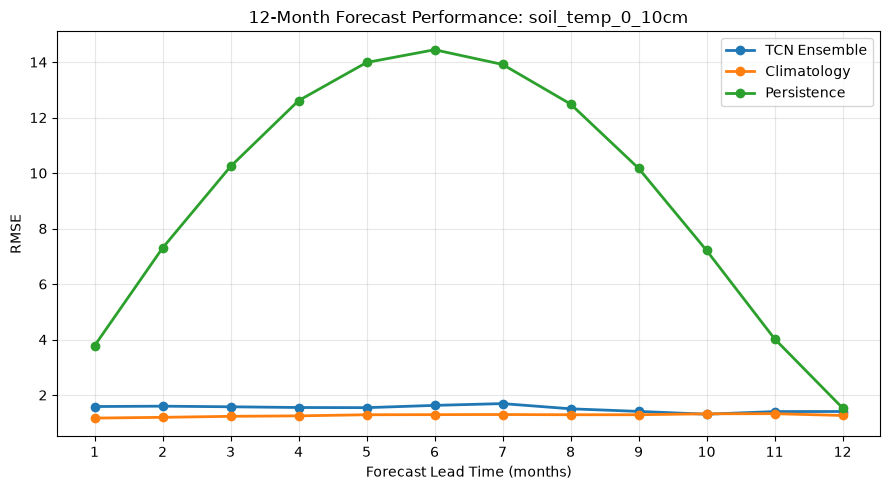

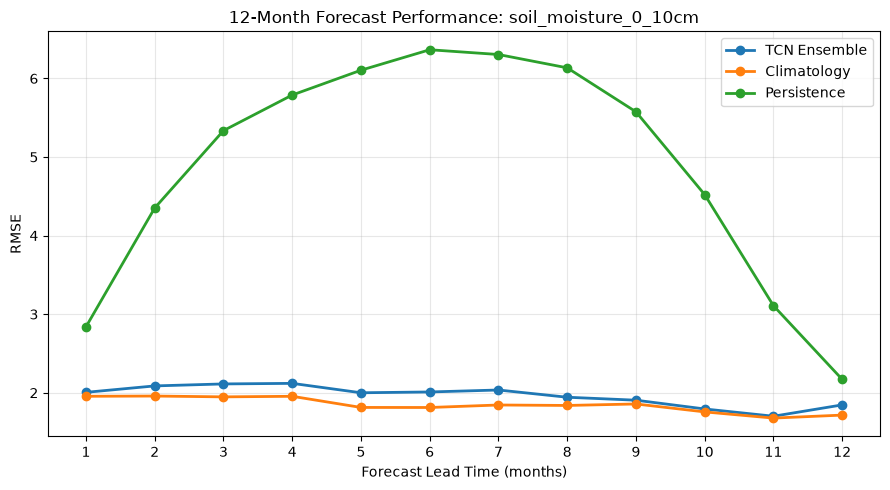

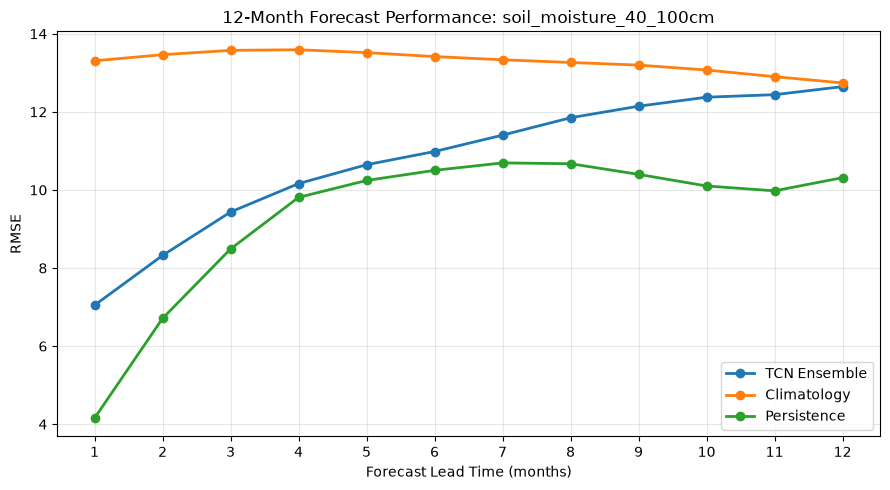

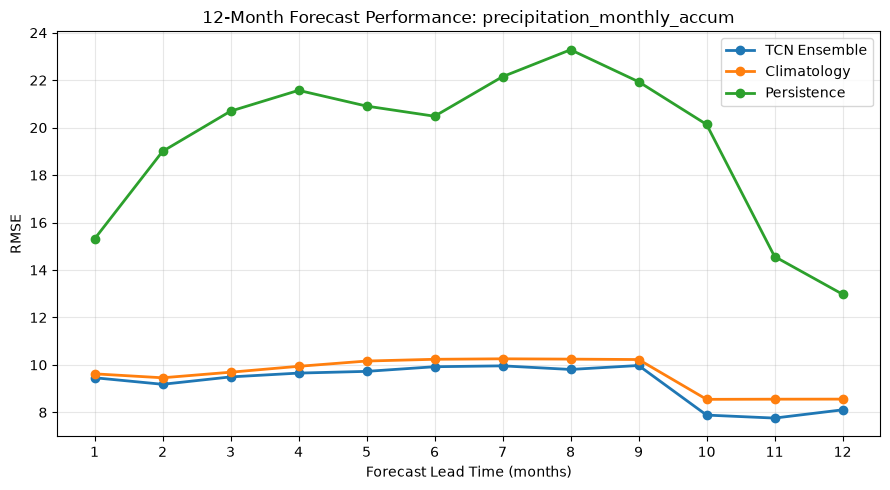

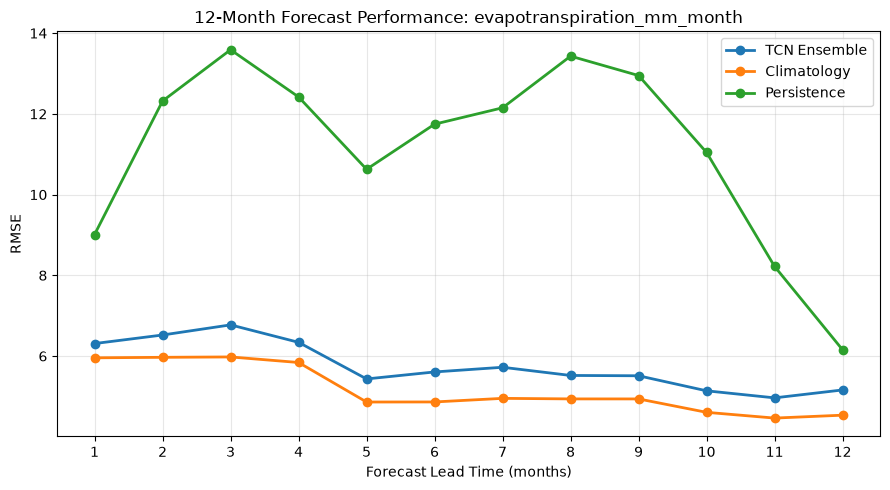

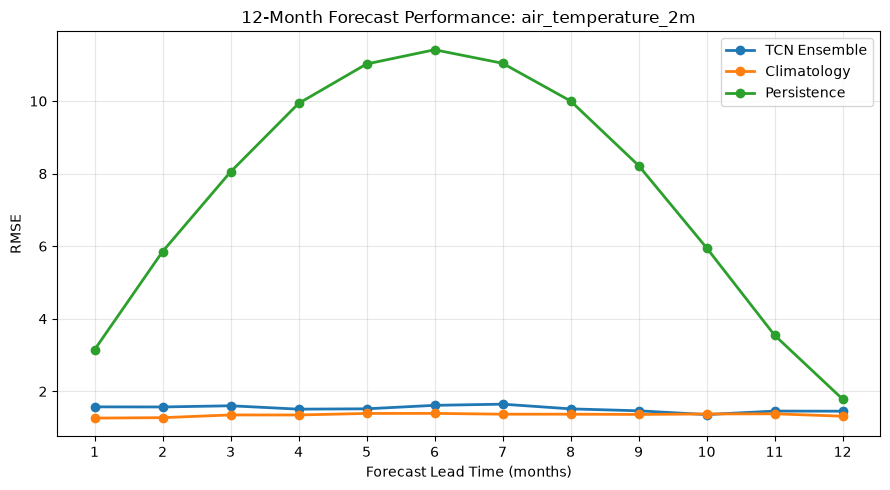

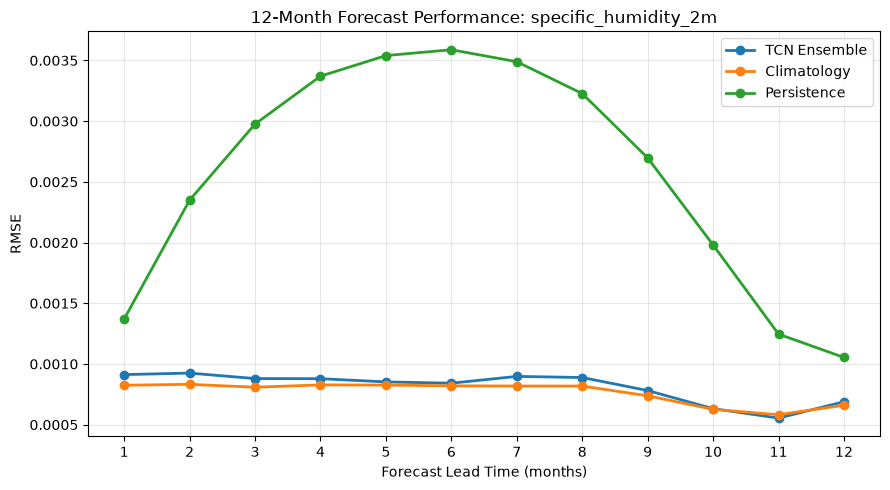

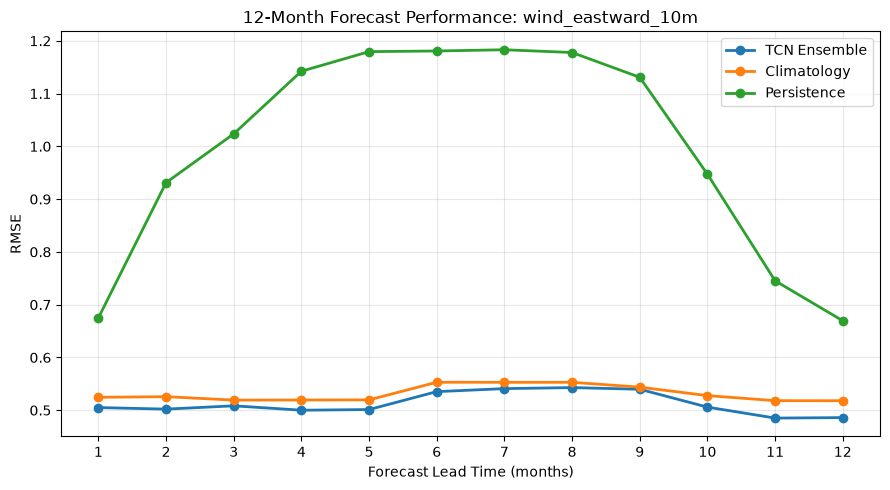

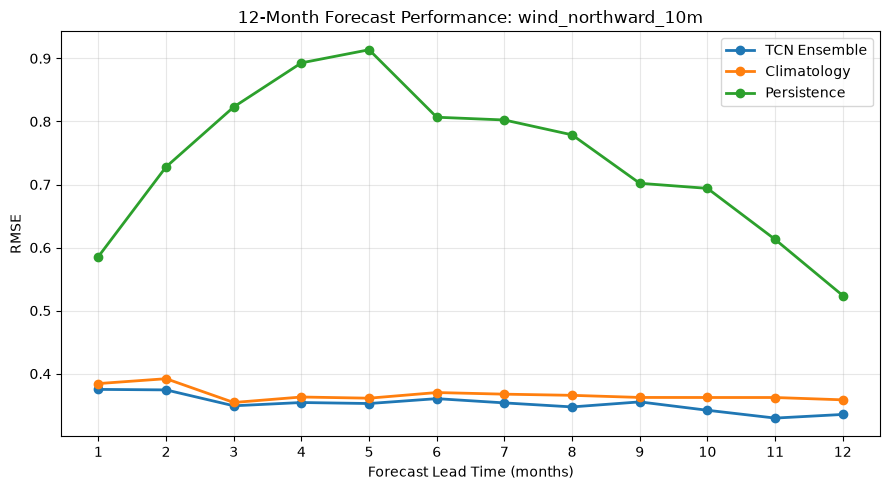


Figuras guardadas en: C:\Users\Roberto Garcés\PythonProjects\EarthTrend_AI_Results


In [93]:
import matplotlib.pyplot as plt
from pathlib import Path

# Carpeta para guardar las figuras
output_dir = Path("EarthTrend_AI_Results")
output_dir.mkdir(exist_ok=True)

# Solo resultados del horizonte de 12 meses
df12 = metrics_df[metrics_df["Horizon"] == 12].copy()

model_order = [
    "TCN Ensemble",
    "Climatology",
    "Persistence"
]

# Gráfica individual por variable
for variable in variables:

    subset = df12[df12["Variable"] == variable]

    plt.figure(figsize=(9, 5))

    for model in model_order:

        model_data = subset[subset["Model"] == model]

        plt.plot(
            model_data["Lead"],
            model_data["RMSE"],
            marker="o",
            linewidth=2,
            label=model
        )

    plt.title(
        f"12-Month Forecast Performance: {variable}",
        fontsize=12
    )

    plt.xlabel("Forecast Lead Time (months)")
    plt.ylabel("RMSE")
    plt.xticks(range(1, 13))
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()

    filename = f"RMSE_{variable}.png"
    plt.savefig(
        output_dir / filename,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

print("\nFiguras guardadas en:", output_dir.resolve())

EARTHTREND AI — EVALUACIÓN FINAL

Generando mapas de calor...


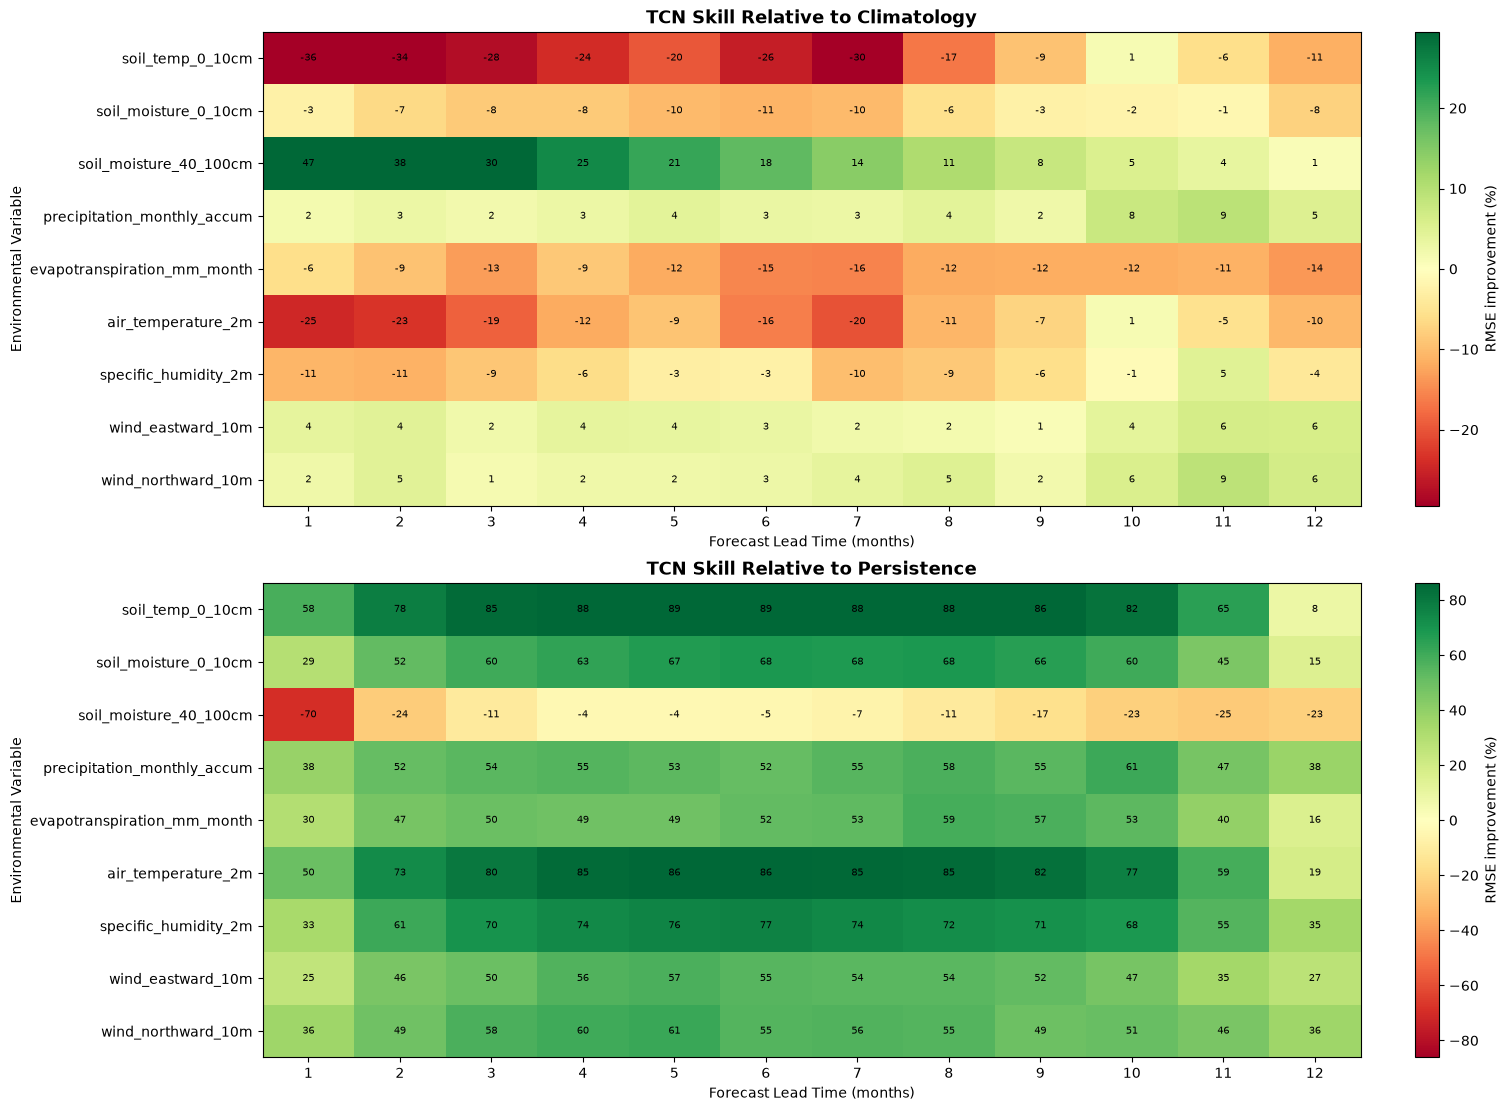


Generando gráficas comparativas...


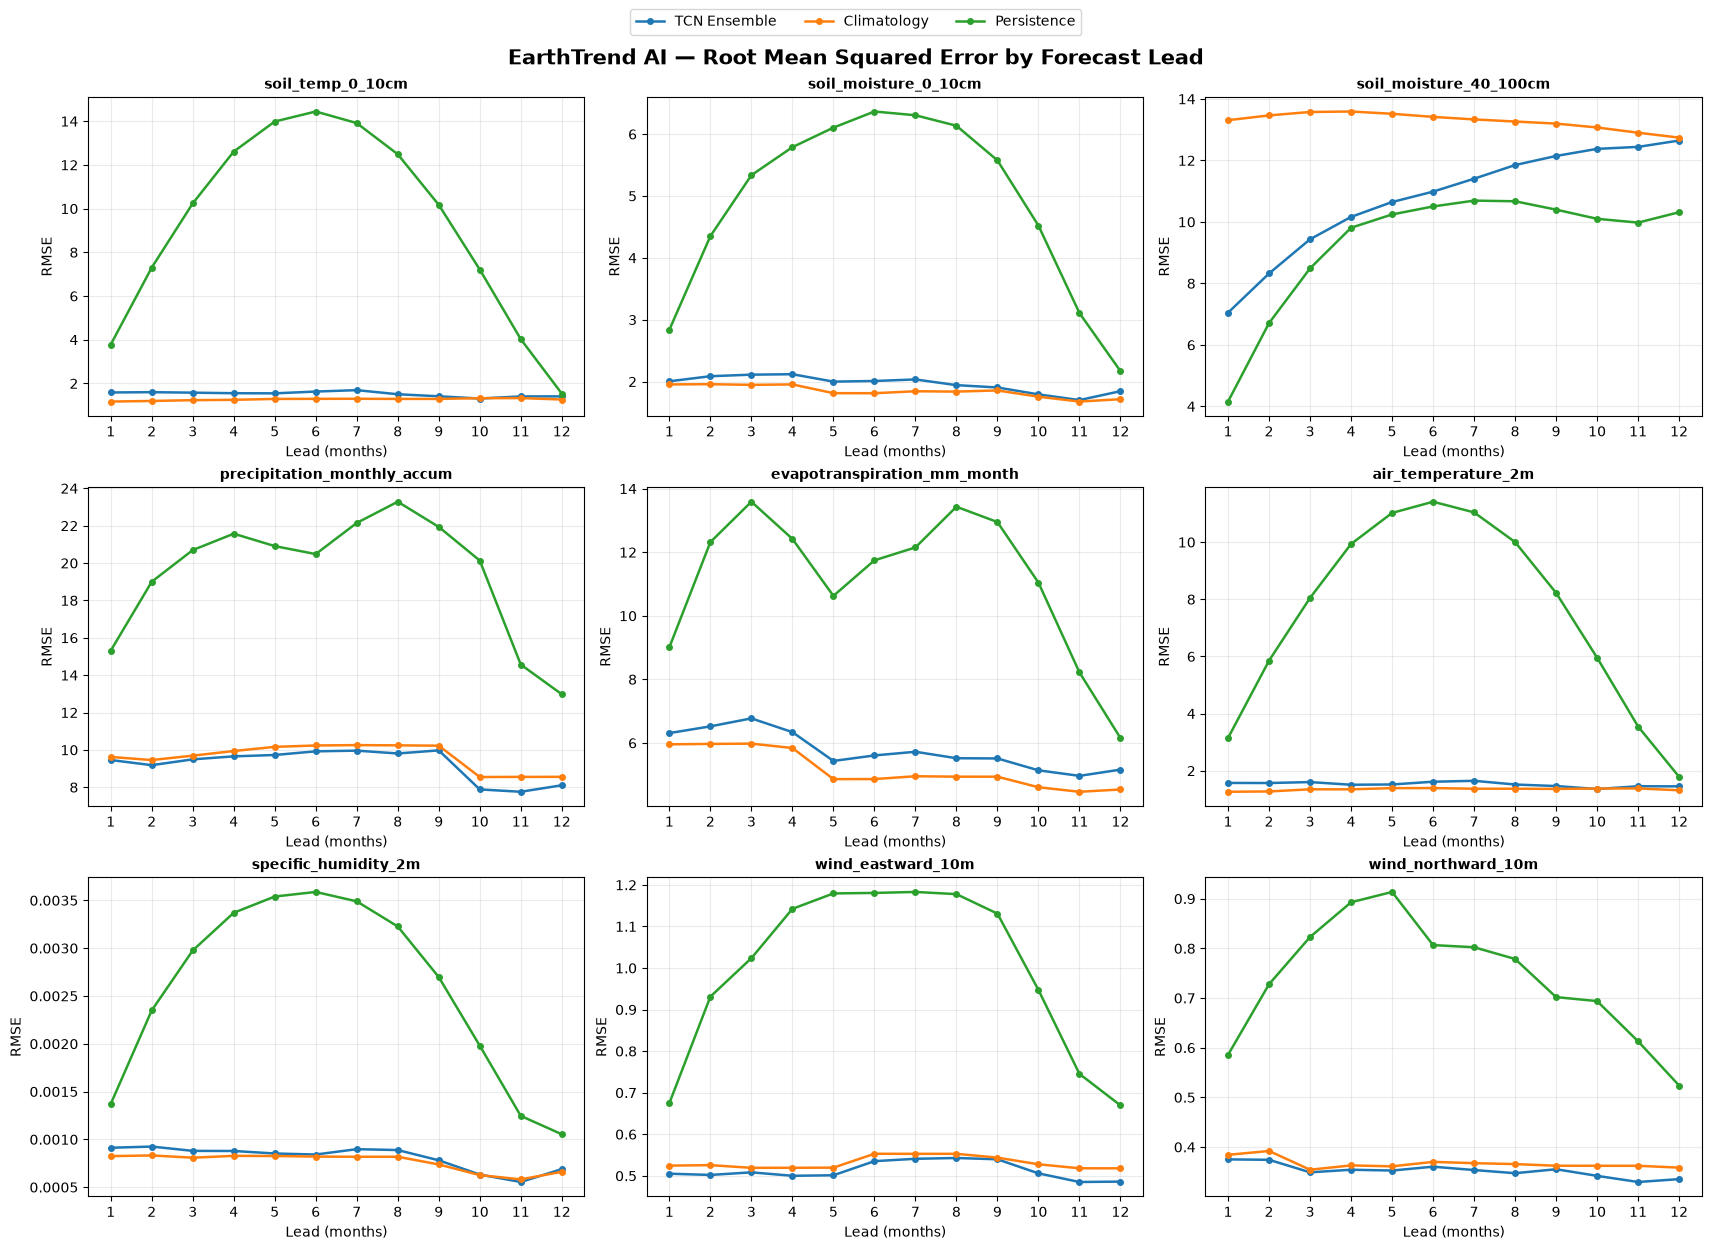

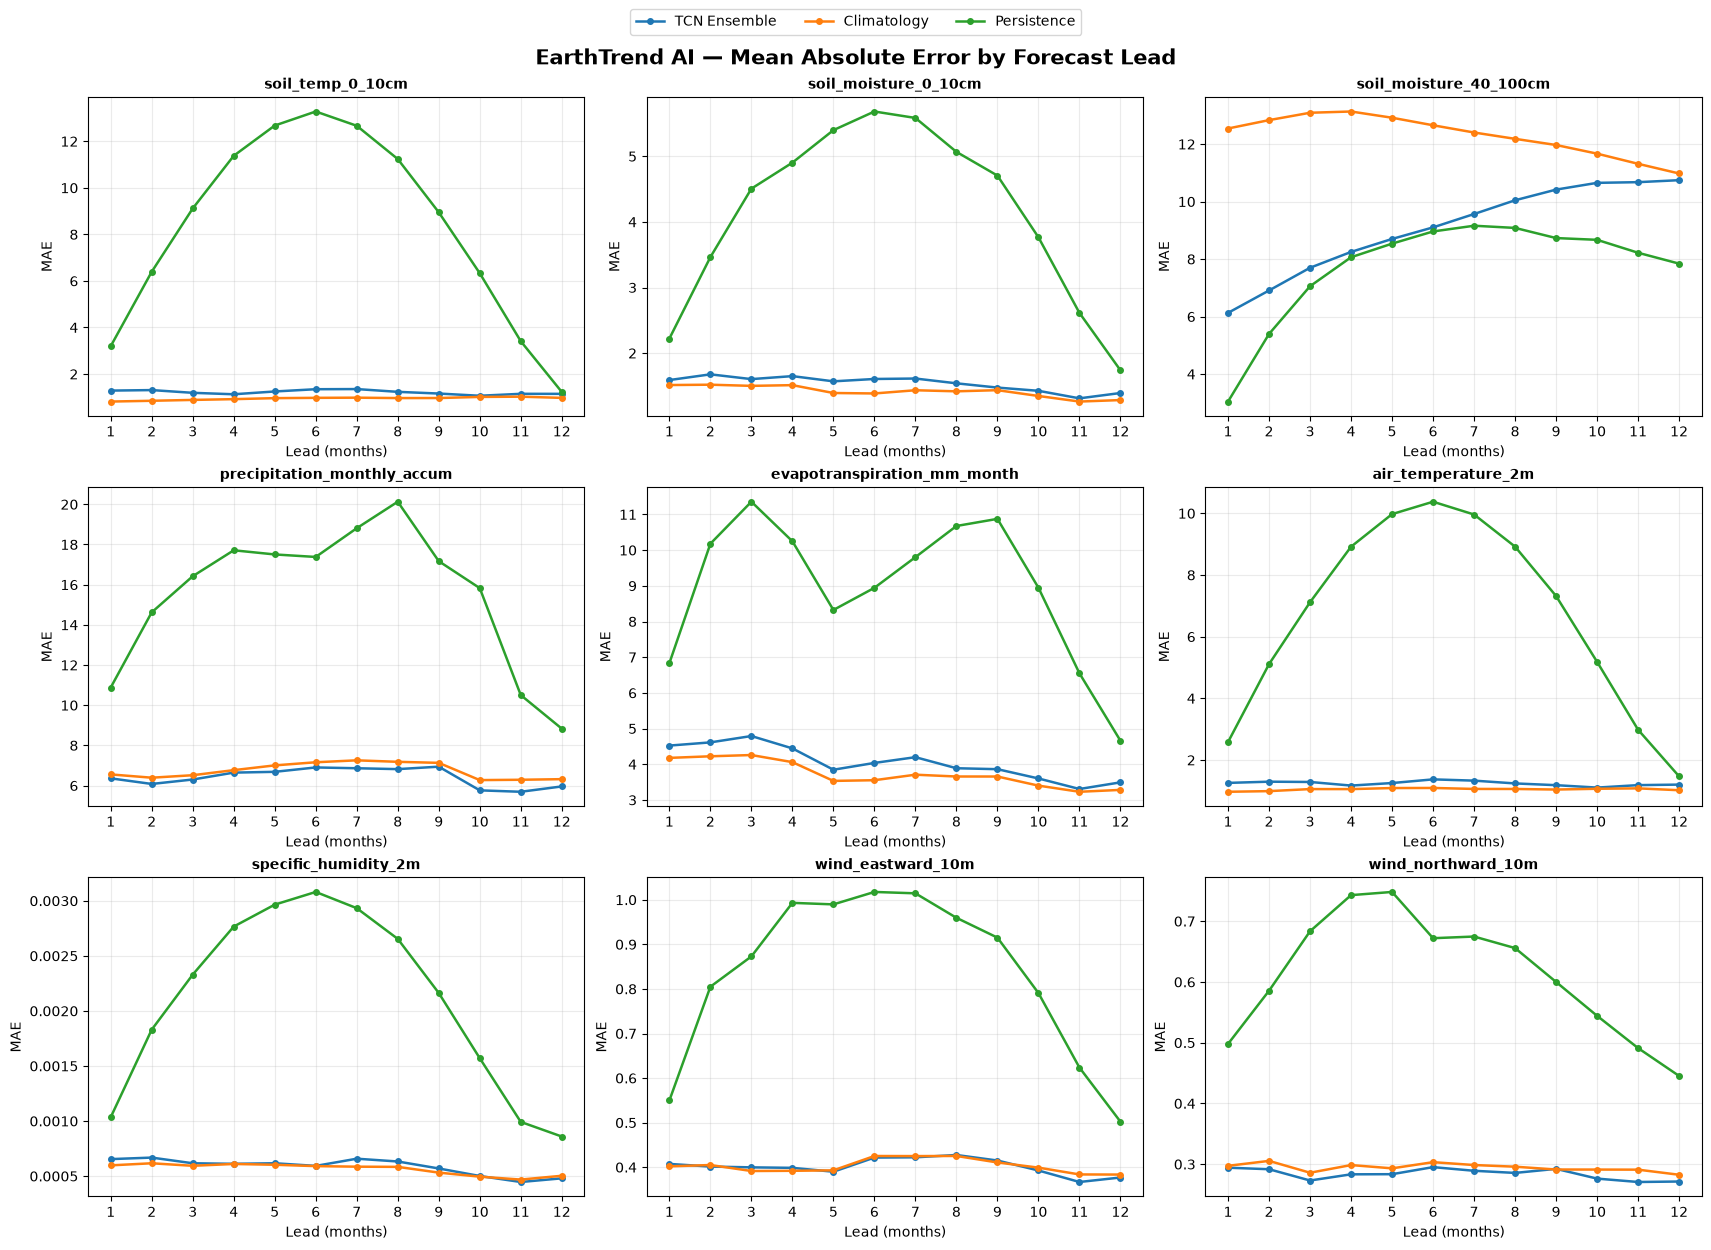

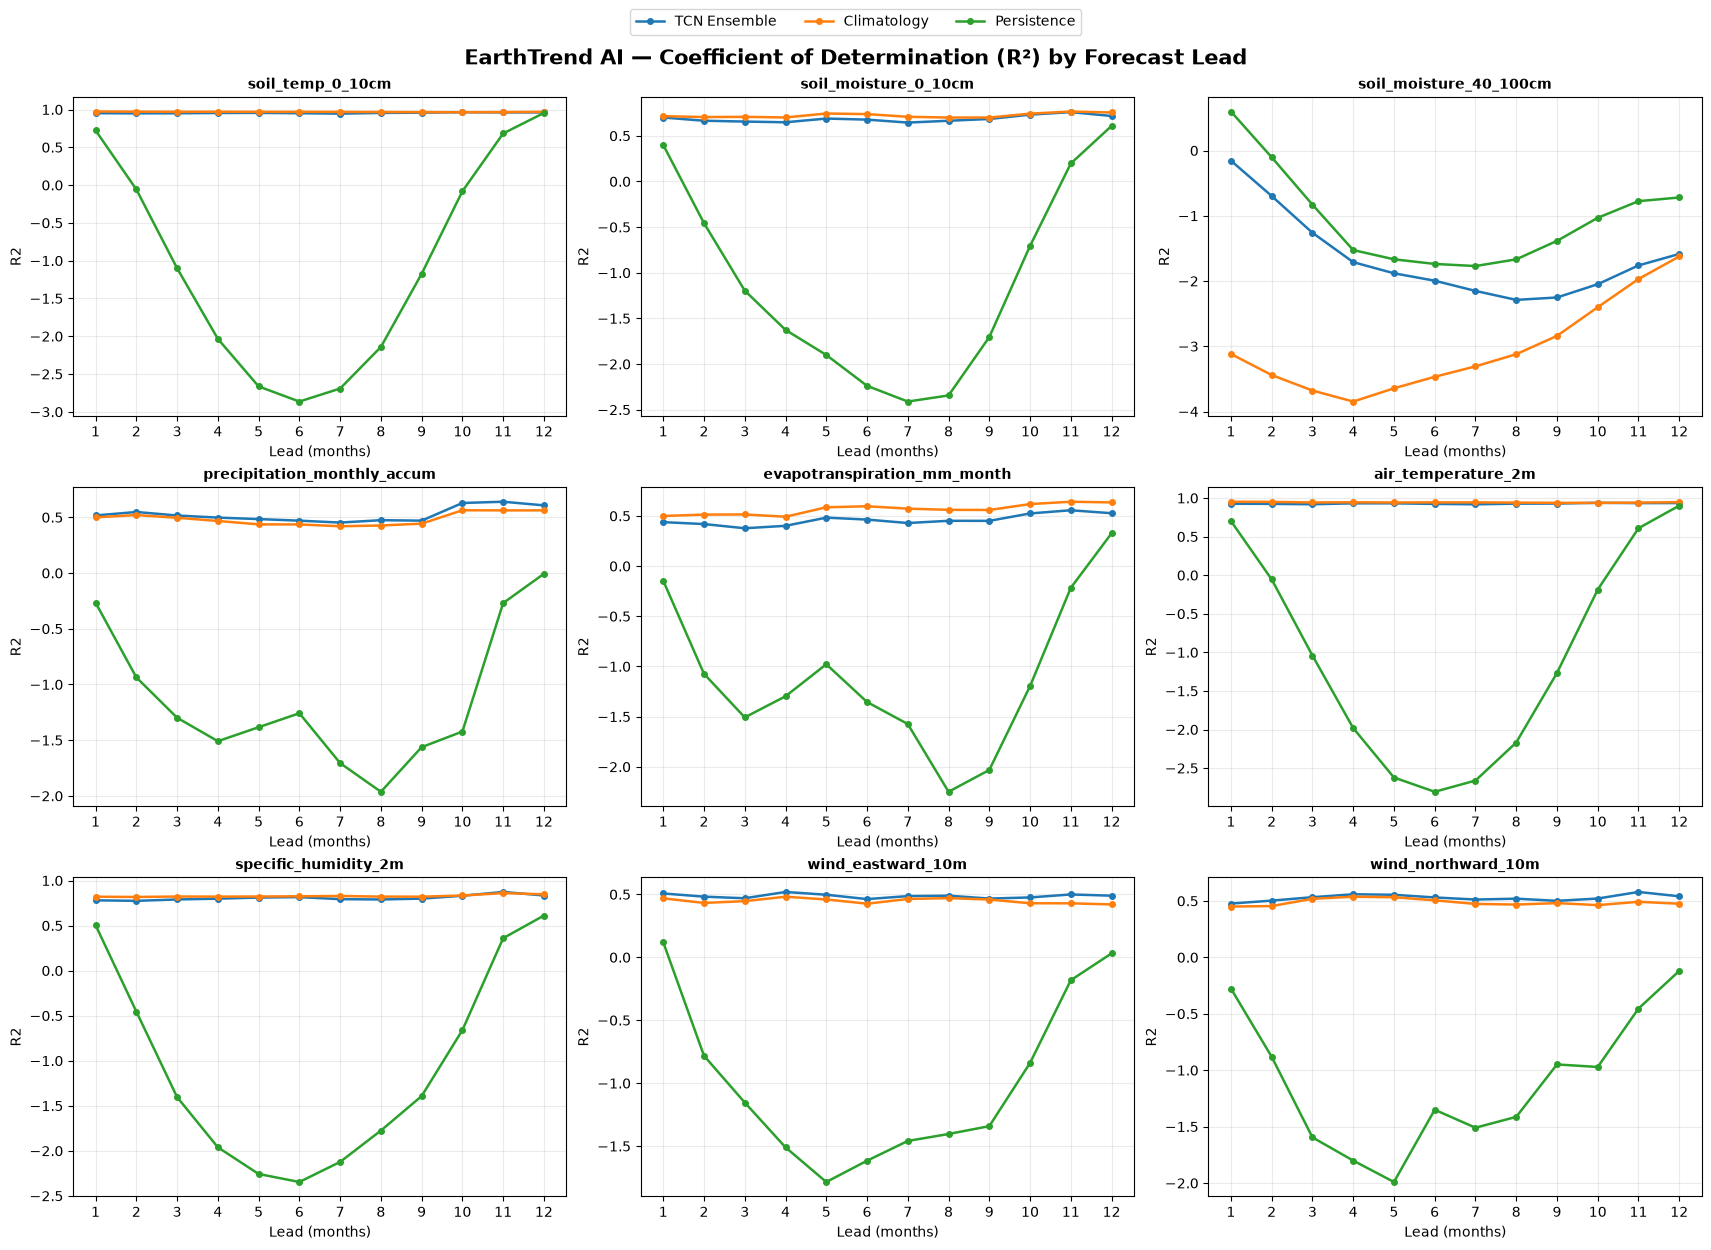


Calculando intervalos de confianza mediante block bootstrap...


In [ ]:

# ================================================================
# EARTHTREND AI — EVALUACIÓN FINAL Y VISUALIZACIÓN
# Heatmaps + comparación de modelos + incertidumbre
# ================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ------------------------------------------------
# 1. CONFIGURACIÓN
# ------------------------------------------------

OUTPUT_DIR = Path("EarthTrend_AI_Final_Evaluation")
OUTPUT_DIR.mkdir(exist_ok=True)

MODELS = ["TCN Ensemble", "Climatology", "Persistence"]

COLORS = {
    "TCN Ensemble": "tab:blue",
    "Climatology": "tab:orange",
    "Persistence": "tab:green"
}

N_BOOTSTRAP = 2000
BLOCK_LENGTH = 3
RANDOM_SEED = 42

rng = np.random.default_rng(RANDOM_SEED)

# Comprobar objetos necesarios
required = [
    "metrics_df",
    "variables",
    "y_true_original",
    "predictions_baselines"
]

missing = [x for x in required if x not in globals()]

if missing:
    raise RuntimeError(f"Faltan objetos del notebook: {missing}")

# Trabajaremos principalmente con el horizonte de 12 meses
df12 = metrics_df[
    metrics_df["Horizon"] == 12
].copy()

print("=" * 75)
print("EARTHTREND AI — EVALUACIÓN FINAL")
print("=" * 75)


# ================================================================
# 2. MAPAS DE CALOR: MEJORA PORCENTUAL DEL TCN
# ================================================================

print("\nGenerando mapas de calor...")

def calculate_skill_table(baseline):

    pivot = df12.pivot_table(
        index="Variable",
        columns="Lead",
        values="RMSE",
        aggfunc="first"
    )

    tcn = df12[
        df12["Model"] == "TCN Ensemble"
    ].pivot(
        index="Variable",
        columns="Lead",
        values="RMSE"
    )

    base = df12[
        df12["Model"] == baseline
    ].pivot(
        index="Variable",
        columns="Lead",
        values="RMSE"
    )

    # Mejora porcentual positiva = TCN tiene menor RMSE
    skill = ((base - tcn) / base) * 100

    return skill.reindex(variables)


skill_clim = calculate_skill_table("Climatology")
skill_persist = calculate_skill_table("Persistence")

fig, axes = plt.subplots(
    2, 1,
    figsize=(15, 11),
    constrained_layout=True
)

for ax, data, title in [
    (
        axes[0],
        skill_clim,
        "TCN Skill Relative to Climatology"
    ),
    (
        axes[1],
        skill_persist,
        "TCN Skill Relative to Persistence"
    )
]:

    values = data.values.astype(float)

    limit = np.nanpercentile(
        np.abs(values),
        95
    )

    limit = max(limit, 1)

    im = ax.imshow(
        values,
        aspect="auto",
        cmap="RdYlGn",
        vmin=-limit,
        vmax=limit
    )

    ax.set_title(title, fontsize=13, weight="bold")
    ax.set_xlabel("Forecast Lead Time (months)")
    ax.set_ylabel("Environmental Variable")

    ax.set_xticks(range(12))
    ax.set_xticklabels(range(1, 13))

    ax.set_yticks(range(len(variables)))
    ax.set_yticklabels(variables)

    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            if np.isfinite(values[i, j]):
                ax.text(
                    j, i,
                    f"{values[i,j]:.0f}",
                    ha="center",
                    va="center",
                    fontsize=7
                )

    fig.colorbar(
        im,
        ax=ax,
        label="RMSE improvement (%)"
    )

plt.savefig(
    OUTPUT_DIR / "01_RMSE_Skill_Heatmaps.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ================================================================
# 3. COMPARACIÓN DE LOS TRES MODELOS
#    RMSE, MAE Y R²
# ================================================================

print("\nGenerando gráficas comparativas...")

metrics_to_plot = [
    ("RMSE", "Root Mean Squared Error"),
    ("MAE", "Mean Absolute Error"),
    ("R2", "Coefficient of Determination (R²)")
]

for metric, ylabel in metrics_to_plot:

    fig, axes = plt.subplots(
        3, 3,
        figsize=(17, 12),
        constrained_layout=True
    )

    for ax, variable in zip(
        axes.flat,
        variables
    ):

        subset = df12[
            df12["Variable"] == variable
        ]

        for model in MODELS:

            model_data = subset[
                subset["Model"] == model
            ].sort_values("Lead")

            ax.plot(
                model_data["Lead"],
                model_data[metric],
                marker="o",
                linewidth=1.8,
                markersize=4,
                label=model,
                color=COLORS[model]
            )

        ax.set_title(variable, fontsize=10, weight="bold")
        ax.set_xlabel("Lead (months)")
        ax.set_ylabel(metric)
        ax.set_xticks(range(1, 13))
        ax.grid(alpha=0.25)

    handles, labels = axes.flat[0].get_legend_handles_labels()

    fig.legend(
        handles,
        labels,
        loc="upper center",
        ncol=3,
        bbox_to_anchor=(0.5, 1.035)
    )

    fig.suptitle(
        f"EarthTrend AI — {ylabel} by Forecast Lead",
        fontsize=15,
        weight="bold"
    )

    plt.savefig(
        OUTPUT_DIR / f"02_{metric}_Comparison.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


# ================================================================
# 4. BLOCK BOOTSTRAP
#    Diferencia pareada de RMSE y MAE
# ================================================================

print("\nCalculando intervalos de confianza mediante block bootstrap...")

def moving_block_indices(n, block_length, rng):

    """
    Bootstrap circular por bloques consecutivos.
    Conserva parcialmente la dependencia temporal.
    """

    n_blocks = int(np.ceil(n / block_length))

    starts = rng.integers(
        0, n,
        size=n_blocks
    )

    indices = []

    for start in starts:
        indices.extend(
            [(start + j) % n for j in range(block_length)]
        )

    return np.asarray(indices[:n])


def calculate_metrics_pair(actual, prediction):

    valid = (
        np.isfinite(actual) &
        np.isfinite(prediction)
    )

    actual = actual[valid]
    prediction = prediction[valid]

    if len(actual) == 0:
        return np.nan, np.nan

    rmse = np.sqrt(
        np.mean((actual - prediction) ** 2)
    )

    mae = np.mean(
        np.abs(actual - prediction)
    )

    return rmse, mae


def bootstrap_difference(
    actual,
    prediction_tcn,
    prediction_baseline,
    n_bootstrap=2000,
    block_length=3
):

    """
    Diferencia TCN - baseline.

    Valores negativos favorecen al TCN.
    Valores positivos favorecen al baseline.
    """

    valid = (
        np.isfinite(actual) &
        np.isfinite(prediction_tcn) &
        np.isfinite(prediction_baseline)
    )

    actual = actual[valid]
    prediction_tcn = prediction_tcn[valid]
    prediction_baseline = prediction_baseline[valid]

    n = len(actual)

    if n < 5:
        return None

    observed_tcn = calculate_metrics_pair(
        actual,
        prediction_tcn
    )

    observed_base = calculate_metrics_pair(
        actual,
        prediction_baseline
    )

    observed_difference = np.array([
        observed_tcn[0] - observed_base[0],
        observed_tcn[1] - observed_base[1]
    ])

    bootstrap_values = []

    for _ in range(n_bootstrap):

        idx = moving_block_indices(
            n,
            block_length,
            rng
        )

        tcn_metrics = calculate_metrics_pair(
            actual[idx],
            prediction_tcn[idx]
        )

        base_metrics = calculate_metrics_pair(
            actual[idx],
            prediction_baseline[idx]
        )

        bootstrap_values.append([
            tcn_metrics[0] - base_metrics[0],
            tcn_metrics[1] - base_metrics[1]
        ])

    bootstrap_values = np.asarray(bootstrap_values)

    lower = np.nanpercentile(
        bootstrap_values,
        2.5,
        axis=0
    )

    upper = np.nanpercentile(
        bootstrap_values,
        97.5,
        axis=0
    )

    return {
        "RMSE_difference": observed_difference[0],
        "RMSE_CI_low": lower[0],
        "RMSE_CI_high": upper[0],
        "MAE_difference": observed_difference[1],
        "MAE_CI_low": lower[1],
        "MAE_CI_high": upper[1]
    }


# Comparar cada lead y variable
bootstrap_results = []

h = 12

actual_all = y_true_original[h]
predictions = predictions_baselines[h]

for lead in range(12):

    for k, variable in enumerate(variables):

        actual = actual_all[:, lead, k]

        tcn = predictions["TCN"][:, lead, k]

        for baseline in ["Climatology", "Persistence"]:

            base = predictions[baseline][:, lead, k]

            result = bootstrap_difference(
                actual,
                tcn,
                base,
                n_bootstrap=N_BOOTSTRAP,
                block_length=BLOCK_LENGTH
            )

            if result is None:
                continue

            bootstrap_results.append({
                "Lead": lead + 1,
                "Variable": variable,
                "Baseline": baseline,
                "N": np.isfinite(
                    actual + tcn + base
                ).sum(),
                **result
            })

bootstrap_df = pd.DataFrame(bootstrap_results)

# Clasificar si el intervalo excluye cero
bootstrap_df["Evidence_TCN_Better_RMSE"] = (
    bootstrap_df["RMSE_CI_high"] < 0
)

bootstrap_df["Evidence_Baseline_Better_RMSE"] = (
    bootstrap_df["RMSE_CI_low"] > 0
)

print("\nRESULTADOS DEL BLOCK BOOTSTRAP")
display(bootstrap_df.round(5))


# ================================================================
# 5. RESUMEN DE INCERTIDUMBRE
# ================================================================

print("\nRESUMEN DE COMPARACIONES CON INTERVALOS QUE NO INCLUYEN CERO")

for baseline in ["Climatology", "Persistence"]:

    subset = bootstrap_df[
        bootstrap_df["Baseline"] == baseline
    ]

    better = subset[
        subset["Evidence_TCN_Better_RMSE"]
    ]

    worse = subset[
        subset["Evidence_Baseline_Better_RMSE"]
    ]

    inconclusive = len(subset) - len(better) - len(worse)

    print(f"\nTCN vs {baseline}")
    print("TCN favorecido:", len(better))
    print("Baseline favorecido:", len(worse))
    print("Intervalo incluye cero:", inconclusive)


# ================================================================
# 6. EXPORTAR TABLAS
# ================================================================

skill_clim.to_csv(
    OUTPUT_DIR / "TCN_skill_vs_climatology.csv"
)

skill_persist.to_csv(
    OUTPUT_DIR / "TCN_skill_vs_persistence.csv"
)

metrics_df.to_csv(
    OUTPUT_DIR / "All_model_metrics.csv",
    index=False
)

bootstrap_df.to_csv(
    OUTPUT_DIR / "Block_bootstrap_confidence_intervals.csv",
    index=False
)

print("\n" + "=" * 75)
print("EVALUACIÓN FINAL COMPLETADA")
print("=" * 75)

print("Archivos guardados en:")
print(OUTPUT_DIR.resolve())

print("\nArchivos generados:")
for file in sorted(OUTPUT_DIR.iterdir()):
    print(" -", file.name)
